### import

In [ ]:
import numpy as np
import pandas as pd
from copy import deepcopy
import pickle #객체 파일로 저장
from tqdm.auto import tqdm #진행률 프로그래스
from collections import Counter
import itertools
import json
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import Binarizer
from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

import torch
from torch import nn
from torch import optim
from torch.optim.lr_scheduler import OneCycleLR #leanring rate scheduler

import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split,TensorDataset

from sklearn.metrics import precision_recall_curve,classification_report, average_precision_score, matthews_corrcoef
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix, roc_auc_score
from sklearn.metrics import roc_curve, auc

import seaborn as sns
import matplotlib.pyplot as plt

import argparse
from typing import List, Dict
from typing import Optional

import lightning.pytorch as L
from lightning.pytorch.loggers import CSVLogger,TensorBoardLogger,WandbLogger
from lightning.pytorch.tuner import Tuner
from lightning.pytorch.callbacks.early_stopping import EarlyStopping
from lightning.pytorch.callbacks import LearningRateFinder, LearningRateMonitor, ModelCheckpoint

import optuna
from optuna.integration import PyTorchLightningPruningCallback
from packaging import version

from torchmetrics import MetricCollection
from torchmetrics.classification import BinaryAccuracy, BinaryPrecision, BinaryRecall,BinaryF1Score, BinaryMatthewsCorrCoef
from torchmetrics.classification import BinaryPrecisionRecallCurve, BinarySpecificity, BinaryROC, BinaryAUROC, BinaryAveragePrecision

import re
from pathlib import Path

import shap

from pprint import pprint

from pytorch_tabnet.tab_model import TabNetClassifier
import lightgbm as lgb
import xgboost as xgb
import catboost as cat
from catboost import CatBoostClassifier, Pool

from scipy.stats import chisquare
from datetime import datetime

In [ ]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.RandomState(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(seed=42)

In [ ]:
import os
NUM_DATALOADER_WORKERS = os.cpu_count()
NUM_DATALOADER_WORKERS

#==============================================================

#### get_clf_eval_thres

In [ ]:
def get_clf_eval_thres(y_test, pred_po, threshold, f1_show=False, auc_show=False):
    eval_df = pd.DataFrame()

    for thres in threshold:
        # threshold에 따른 예측 분류 값
        binarizer = Binarizer(threshold = thres)
        binarizer.fit(pred_po)
        thres_pred = binarizer.transform(pred_po)

        # 평가지표 - F1 스코어는 목차 4, roc는 목차 5에서 확인
        tn, fp, fn, tp = confusion_matrix(y_test, thres_pred).ravel()
        ppv = tp / (tp + fp) if (tn + fp) > 0 else 0.0
        npv = tn / (tn + fn) if (tn + fn) > 0 else 0.0
        fnr = fn / (tp + fn) if (tp + fn) > 0 else 0.0
        fpr = fp / (tn + fp) if (tn + fp) > 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        #acc = (tn+tp)/(tn+fp+fn+tp)

        accuracy = accuracy_score(y_test, thres_pred)
        precision = precision_score(y_test, thres_pred) #tp/(tp+fp)
        recall = recall_score(y_test, thres_pred) #tp/(tp+fn)
        f1 = f1_score(y_test, thres_pred) # 2*precision*recall / (precision+recall)
        mcc = matthews_corrcoef(y_test, thres_pred)
        gmean = gmean([recall , specificity]) #math.sqrt(recall * specificity)

        auc = roc_auc_score(y_test, pred_po)
        auprc = average_precision_score(y_test, pred_po)

        # 데이터 프레임 형태
        eval_lst = np.array([accuracy, precision, recall, specificity, f1, auc, auprc, mcc,gmean,
                             ppv,npv,fnr,fpr,tn, fp, fn, tp]).reshape(-1,1)
        temp = pd.DataFrame(eval_lst, columns=[thres],
                            index = ["Accuracy", "Precision", "Recall(=Sens)", "Spec", "F1",
                                     "AUC", "AUPRC", "MCC", "G-mean","PPV","NPV","FNR","FPR", "TN", "FP", "FN", "TP"])
        eval_df = pd.concat([eval_df,temp], axis=1)

    eval_df.columns.names = ["Threshold"]

    if f1_show == False:
        eval_df.drop("F1스코어", axis=0, inplace=True)

    if auc_show == False:
        eval_df.drop("AUC", axis=0, inplace=True)

    print(classification_report(y_test, thres_pred))

    return round(eval_df,4)


In [ ]:
thres_lst = [float(optimal_threshold), 0.5, 0.6,0.7,0.8]

display(get_clf_eval_thres(y1, y_hat1, thres_lst, f1_show=True, auc_show=True))

#### precision_recall_curve_plot

In [ ]:
def precision_recall_curve_plot(y_test, pred_proba_c1, png):
    # threshold ndarray와 이 threshold에 따른 정밀도, 재현율 ndarray 추출.
    precisions, recalls, thresholds = precision_recall_curve(y_test, pred_proba_c1)

    # X축을 threshold값으로, Y축은 정밀도, 재현율 값으로 각각 Plot 수행. 정밀도는 점선으로 표시
    plt.figure(figsize=(8,6))
    threshold_boundary = thresholds.shape[0]
    plt.plot(thresholds, precisions[0:threshold_boundary], linestyle='--', label='precision')
    plt.plot(thresholds, recalls[0:threshold_boundary],label='recall')

    # threshold 값 X 축의 Scale을 0.1 단위로 변경
    start, end = plt.xlim()
    plt.xticks(np.round(np.arange(start, end, 0.1),2))

    # x축, y축 label과 legend, 그리고 grid 설정
    plt.xlabel('Threshold value'); plt.ylabel('Precision and Recall value')
    plt.legend(); plt.grid()
    plt.show()
    #plt.savefig(png)

In [ ]:
png = 'precision_recall.png'
print(y1.shape,y1.dtype, type(y1))
print(y_hat1.reshape(-1,1).shape,y_hat1.reshape(-1,1).dtype, type(y_hat1.reshape(-1,1)))

precision_recall_curve_plot(y1, y_hat1.reshape(-1,1), png)

### evaluation_thres / plot_roc_prc / plot_roc_prc_multi

In [ ]:
def evaluation_thres(header, y_test, pred_po, thresholds, save_png):
    eval_index = ["thres", "Accuracy", "F1", "MCC", "Precision", "Recall(=Sens)",
                  "Specificity", "AUC", "AUCPR","G-mean", "PPV","NPV","FNR","FPR","TN", "FP", "FN", "TP"]
    _eval_metrics = pd.DataFrame(index = eval_index)

    auc = roc_auc_score(y_test, pred_po)
    auprc = average_precision_score(y_test, pred_po)

    _fpr, _tpr, _thresholds = roc_curve(y_test, pred_po)
    _thres_idx = np.argmax(_tpr - _fpr)
    thres_auc = _thresholds[_thres_idx]

    if thres_auc > 0:
        thresholds.append(thres_auc)

    _precision, _recall, _thresholds = precision_recall_curve(y_test, pred_po)
    _f1 = 2 * (_precision * _recall) / (_precision + _recall)
    _thres_idx = _f1.argmax()
    thres_auprc = _thresholds[_thres_idx]

    if thres_auprc > 0:
        thresholds.append(thres_auprc)

    _thres_idx = np.where(_recall == _precision)
    if len(_thres_idx[0]) > 0:
        thres_auprc = float(_thresholds[_thres_idx][0])
        if thres_auprc > 0:
            thresholds.append(thres_auprc)

    #plot_roc_prc(_fpr, _tpr, _recall, _precision, auc, auprc, save_png)

    for thres in thresholds:
        # threshold에 따른 예측 분류 값
        binarizer = Binarizer(threshold = thres)
        binarizer.fit(pred_po)
        thres_pred = binarizer.transform(pred_po)

        # 평가지표 - F1 스코어는 목차 4, roc는 목차 5에서 확인
        tn, fp, fn, tp = confusion_matrix(y_test, thres_pred).ravel()
        ppv = tp / (tp + fp) if (tn + fp) > 0 else 0.0
        npv = tn / (tn + fn) if (tn + fn) > 0 else 0.0
        fnr = fn / (tp + fn) if (tp + fn) > 0 else 0.0
        fpr = fp / (tn + fp) if (tn + fp) > 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        #acc = (tn+tp)/(tn+fp+fn+tp)

        accuracy = accuracy_score(y_test, thres_pred)
        precision = precision_score(y_test, thres_pred) #tp/(tp+fp)
        recall = recall_score(y_test, thres_pred) #tp/(tp+fn)
        f1 = f1_score(y_test, thres_pred) # 2*precision*recall / (precision+recall)
        mcc = matthews_corrcoef(y_test, thres_pred)
        _gmean = gmean([recall , specificity]) #math.sqrt(recall * specificity)

        eval_lst = np.array([thres, accuracy, f1, mcc, precision, recall,
                             specificity, auc, auprc, _gmean, ppv,npv,fnr,fpr, tn, fp, fn, tp]).reshape(-1,1)

        _eval_metrics[f'{header}_{thres:.4f}'] = eval_lst

    return round(_eval_metrics, 4)

def plot_roc_prc(_fpr, _tpr, _recall, _precision, auc, auprc, save_png):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=150)

    #sns.lineplot(x = _fpr, y = _tpr, label = f'AUC = {auc:.3f}', ax = ax[0])
    ax[0].plot(_fpr, _tpr, label = f'AUC = {auc:.3f}')
    ax[0].plot([0, 1], [0, 1], color='gray', linestyle='dotted',)
    ax[0].set_xlabel('False Positive Rate(1-Specificity)')
    ax[0].set_ylabel('True Positive Rate(Sensitivity)')
    ax[0].set_title('Receiver Operating Characteristic (ROC) Curve')
    ax[0].legend(loc='lower right')
    ax[0].grid(True)

    #sns.lineplot(x = _recall, y = _precision, label = f'auprc=-{auprc:.3f}', ax = ax[1])
    ax[1].plot(_recall, _precision, label = f'AUC = {auprc:.3f}')
    #ax[1].plot([0, 1], [0, 1], color='gray', linestyle='dotted', label='Random (AUC = 0.5)')
    ax[1].set_xlabel('Recall')
    ax[1].set_ylabel('Precision')
    ax[1].set_title('Precision-Recall(PR) Curve')
    ax[1].legend(loc='lower left')
    ax[1].grid(True)

    plt.tight_layout()

    if save_png:
        plt.savefig(save_png)

    plt.show()

def plot_roc_prc_multi(header, _df_oob, save_png):
    aucs=[]
    auprcs = []
    fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=150)

    folds = _df_oob['fold'].unique()
    folds = np.sort(folds)
    for fold in folds:
        y_test = _df_oob.loc[_df_oob['fold'] == fold, 'y']
        pred_po = _df_oob.loc[_df_oob['fold'] == fold, 'y_pred'].values.reshape(-1,1)

        auc = roc_auc_score(y_test, pred_po)
        auprc = average_precision_score(y_test, pred_po)
        aucs.append(auc)
        auprcs.append(auprc)

        _fpr, _tpr, _thresholds = roc_curve(y_test, pred_po)
        _precision, _recall, _thresholds = precision_recall_curve(y_test, pred_po)

        ax[0].plot(_fpr, _tpr, label = f'AUC(fold={fold}) = {auc:.4f}')
        ax[1].plot(_recall, _precision, label = f'PRC(fold={fold}) = {auprc:.4f}')

    auc_mean = np.mean(aucs)
    auc_std = np.std(aucs)
    auprc_mean = np.mean(auprcs)
    auprc_std = np.std(auprcs)

    ax[0].plot([0, 1], [0, 1], color='gray', linestyle='dotted',)
    ax[0].set_xlabel('False Positive Rate(1-Specificity)')
    ax[0].set_ylabel('True Positive Rate(Sensitivity)')
    ax[0].set_title(f'ROC Curve (Mean(AUC) = {auc_mean:.4f} $\pm$ {auc_std:.4f})')
    ax[0].legend(loc='lower right')
    ax[0].grid(True)

    ax[1].set_xlabel('Recall')
    ax[1].set_ylabel('Precision')
    ax[1].set_title('Precision-Recall(PR) Curve')
    ax[1].set_title(f'PR Curve (Mean(AUC) = {auprc_mean:.4f} $\pm$ {auprc_std:.4f})')
    ax[1].legend(loc='lower left')
    ax[1].grid(True)

    plt.tight_layout()
    plt.savefig(save_png)
    plt.show()


#### save_optuna

In [ ]:
def save_optuna(study, study_name):
    folder = os.path.join(os.getcwd(), study_name)
    file_pkl = os.path.join(folder, f"optuna_{study_name}.pkl")
    joblib.dump(study, file_pkl)

    file_csv = os.path.join(folder, f"optuna_{study_name}.csv")
    df_optuna = study.trials_dataframe()
    df_optuna.sort_values(by='value',ascending=False).to_csv(file_csv, sep="\t", index=False)

def show_optuna(study, study_name, _title):
    print("!!! best parameter")
    print("Number of finished trials: {}".format(len(study.trials)))

    print("Best trial:")
    trial = study.best_trial
    #print(trial)
    print("  Trial {} Value: {}".format(trial.number,trial.value))

    print("  Params: ")
    for key, value in trial.params.items():
        print("    {}: {}".format(key, value))

    df_optuna = study.trials_dataframe()
    display(df_optuna.sort_values(by='value',ascending=False).head())

    #image save
    #file_png = os.path.join(folder, f"optuna_{ml_name}_importance.png")
    #optuna.visualization.matplotlib.plot_param_importances(study)
    #plt.savefig(file_png)
    #fig.figure.savefig('param_importances.png')

    #plotly_config = {'staticPlot': True}
    #fig.show(config=plotly_config)

    fig = optuna.visualization.plot_param_importances(study)
    fig.update_layout(title_text=_title, title_font_size = 24,
                title_x = 0.5, title_y = 0.93,
                title_xanchor = "center", title_yanchor = "middle")
    fig.update_layout(width=600, height=450,
                  margin_l=50, margin_r=10,
                  margin_t=50, margin_b=10,
                  )
    fig.update_xaxes(title_font_size = 16, tickfont_size=12)
    fig.update_yaxes(title_font_size = 16, tickfont_size=12)
    fig.show()

    fig = optuna.visualization.plot_optimization_history(study, error_bar=False)
    fig.show()

    fig = optuna.visualization.plot_intermediate_values(study)
    fig.show()

    fig = optuna.visualization.plot_parallel_coordinate(study)
    fig.show()

    fig = optuna.visualization.plot_timeline(study)
    fig.show()

In [ ]:
optuna.visualization.plot_param_importances(study)
_save_png = png_fold + "/"+ f'radar_{tool_name}_compare_dataset.png'
    print("!!! Save(PMG): ", _save_png)
    fig.write_image(_save_png, scale=3)
    fig.show()

In [ ]:
fig = optuna.visualization.plot_param_importances(study)
fig.update_layout(title_text='XGBoost', title_font_size = 24,
                title_x = 0.5, title_y = 0.93,
                title_xanchor = "center", title_yanchor = "middle")
fig.update_layout(width=600, height=450,
                  margin_l=50, margin_r=10,
                  margin_t=50, margin_b=10,
                  )
fig.update_xaxes(title_font_size = 16, tickfont_size=12)
fig.update_yaxes(title_font_size = 16, tickfont_size=12)

fig.show()

#### save_feature

In [ ]:
def save_feature(_df, study_name, file_name):
    print(f"!!! SAVE: feature_{file_name}.txt")

    file_txt = os.path.join(study_name, f'feature_{file_name}.csv')
    with open(file_txt, 'w') as f:
        for i, col in enumerate(_df.columns):
            f.write(f'{i+1}\t{col}\n')

#### plot_classification_report

In [ ]:
def plot_classification_report(df, title='Classification', cmap='RdBu'):
    y_real, y_pred = df['y'].values, df['y_pred'].values.reshape(-1,1)
    binarizer = Binarizer(threshold = 0.5)
    binarizer.fit(y_pred)
    thres_pred = binarizer.transform(y_pred)
    df['y_hat'] = thres_pred.astype('int')
    df['eq'] = df.apply(lambda x: 1 if x['y'] == x['y_hat'] else 0, axis=1)

    report =classification_report(y_real, thres_pred)

    class_t = {0:'Benign', 1:'Pathogenic'}
    report = report.replace('\n\n', '\n')
    report = report.replace(' / ', '/')
    lines = report.split('\n')

    classes, score, support, class_names = [], [], [], []
    for line in lines[1 : (len(lines) - 4)]:  # if you don't want avg/total result, then change [1:] into [1:-1]
        t = line.strip().replace(' avg', '-avg').split()
        if len(t) < 2:
            continue
        classes.append(t[0])
        v = [float(x) for x in t[1: len(t) - 1]]
        support.append(int(t[-1]))
        class_names.append(t[0])
        score.append(v)

    score = np.array(score)
    xticklabels = ['Precision', 'Recall', 'F1-score']
    yticklabels = [f'{class_t[idx]}\n({sup:,.0f})' for idx, sup in enumerate(support)]

    plt.figure(figsize=(5,3))

    plt.imshow(score, interpolation='nearest', cmap=cmap, vmin=0.9, vmax=1,)
    plt.title(title)
    plt.colorbar()

    plt.xticks(np.arange(3), xticklabels, rotation=0)
    plt.yticks(np.arange(len(classes)), yticklabels)

    upper_thresh = score.min() + (score.max() - score.min()) / 10 * 8
    lower_thresh = score.min() + (score.max() - score.min()) / 10 * 2
    for i, j in itertools.product(range(score.shape[0]), range(score.shape[1])):
        plt.text(j, i, format(score[i, j], '.2f'),
                 horizontalalignment="center",
                 #color="white" if (score[i, j] > upper_thresh or score[i, j] < lower_thresh) else "black",
                 color='black')


    #plt.ylabel('Classes')
    #plt.xlabel('Metrics')
    plt.tight_layout()
    return df

#### def: make_shap_value(model, df)

In [ ]:
def make_shap_value(model, df):

    shap_explainer = shap.TreeExplainer(model)
    shap_values = shap_explainer.shap_values(df)
    base_values = shap_explainer.expected_value

    #base_values = np.round(base_values, 3)
    #shap_values = np.round(shap_values, 3)

    print("base value: ", base_values, type(base_values))
    print("shap_values: ", len(shap_values), type(shap_values), shap_values.shape,)

    df_shap = pd.DataFrame({"mean_abs_shap": np.mean(np.abs(shap_values), axis=0),
                            "stdev_abs_shap": np.std(np.abs(shap_values), axis=0),
                            "name": df.columns})
    #display(df_shap.sort_values("mean_abs_shap", ascending=False).head())

    return base_values, shap_values

def plot_shap(df, base_values, shap_values, fold_name):
    # decision
    save_png = fold_name + "/" + f'shap_decision.png'
    plt.figure()
    shap.decision_plot(base_values, shap_values, df,  show=False, ignore_warnings=True)
    fig = plt.gcf()
    fig.savefig(save_png)

    # summary - dot
    save_png = fold_name + "/" + f'shap_summary.png'
    plt.figure()
    #shap.summary_plot(shap_values, df,  #plot_size=[5,4])
    shap.summary_plot(shap_values, df, show=False,)
    #plt.title("Feature Importance - Dot", fontsize=16)
    fig = plt.gcf()
    fig.savefig(save_png)

    # summary - bar
    save_png = fold_name + "/" + f'shap_summary_bar.png'
    plt.figure()
    #shap.summary_plot(shap_values, df, plot_type="bar", plot_size=[5,4])
    shap.summary_plot(shap_values, df, plot_type="bar", show=False,)
    #plt.title("Feature Importance - Bar", fontsize=16)
    fig = plt.gcf()
    fig.savefig(save_png)

    for col_name in df.columns:
        # dependence
        save_png = fold_name + "/" + f'shap_dependence_{col_name}.png'
        plt.figure()
        shap.dependence_plot(col_name, shap_values, df, show=False)
        fig = plt.gcf()
        fig.savefig(save_png)

        # embedding
        save_png = fold_name + "/" + f'shap_embedding_{col_name}.png'
        plt.figure()
        shap.embedding_plot(col_name, shap_values, feature_names=df.columns, method='pca', alpha=1.0, show=False)
        fig = plt.gcf()
        fig.savefig(save_png)

#### def: make_shap_value_deep(model, df)

In [ ]:
def make_shap_value_deep(model, df):
    shap_input = torch.from_numpy(df.values).float()

    shap_explainer = shap.DeepExplainer(model, shap_input)
    base_values = shap_explainer.expected_value
    shap_values = shap_explainer.shap_values(shap_input) ## very very slow

    #base_values = np.round(base_values, 3)
    #shap_values = np.round(shap_values, 3)

    print("base value: ", base_values, type(base_values))
    print("shap_values: ", len(shap_values), type(shap_values), shap_values.shape,)

    shap_values = np.squeeze(shap_values, axis=2)
    df_shap = pd.DataFrame({"mean_abs_shap": np.mean(np.abs(shap_values), axis=0),
                            "stdev_abs_shap": np.std(np.abs(shap_values), axis=0),
                            "name": df.columns})
    df_shap.sort_values("mean_abs_shap", ascending=False)[:10]
    return base_values, shap_values

In [ ]:
base_values, shap_values = make_shap_value_deep(pretrained_model, X_test.loc[rand_idx])
plot_shap(X_test.loc[rand_idx], base_values, shap_values)

#### make_yyyy_mm_dd

In [ ]:
from datetime import datetime
def make_yyyy_mm_dd():
    now = datetime.now()
    return now.strftime("%Y_%m_%d")
make_yyyy_mm_dd()

'2024_12_16'

#===============================================================

# DataSplit

In [ ]:
class Splitter:
    def __init__(self, split_t = True, split_n = 5, df = pd.DataFrame(), size_test = 0.5):
        self.split_n = split_n
        self.split_t = split_t
        self.df = df
        self.size_test = size_test
        print(self.split_n, self.split_t, self.size_test)

    def split_data(self, X, y, random_state_list):
        if self.split_t == 'skf':
            print('StratifiedKFold')
            for random_state in random_state_list:
                kf = StratifiedKFold(n_splits = self.split_n, random_state = random_state, shuffle = True,)
                for train_index, val_index in kf.split(X, y):
                    X_train, X_val = X.iloc[train_index], X.iloc[val_index]
                    y_train, y_val = y.iloc[train_index], y.iloc[val_index]
                    yield X_train, X_val, y_train, y_val, val_index
        elif self.split_t:
            print('KFold')
            for random_state in random_state_list:
                kf = KFold(n_splits = self.split_n, random_state = random_state, shuffle = True)
                for train_index, val_index in kf.split(X):
                    X_train, X_val = X.iloc[train_index], X.iloc[val_index]
                    y_train, y_val = y.iloc[train_index], y.iloc[val_index]
                    yield X_train, X_val, y_train, y_val, val_index
        else:
            print("train_test_split")
            for random_state in random_state_list:
                X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = self.size_test, stratify=y, random_state = random_state)
                yield X_train, X_val, y_train, y_val, y_val.index

In [ ]:
random_state = 42
split_t = 'skf'
split_n = 10
size_test=0.5
random_state_list = [42]
#cat_df = pd.DataFrame(y.values, columns=['target'])

splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)
print(data_n)
for i, (X_train_, X_valid_, y_train_, y_valid_, val_index) in enumerate(data_n):
    print(f"Fold: {i+1}", X_train_.shape, X_valid_.shape, X_train_.index[0], X_valid_.index[0], type(X_train_), type(y_valid_),)
    print(f"Fold: {i+1}", Counter(y_train_),Counter(y_valid_) )

In [ ]:
random_state = 42
split_t = False
split_n = 10
size_test=0.1
random_state_list = [42]
#cat_df = pd.DataFrame(y.values, columns=['target'])

splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)
print(data_n)
for i, (X_train_, X_valid_, y_train_, y_valid_, val_index) in enumerate(data_n):
    print(f"Fold: {i+1}", X_train_.shape, X_valid_.shape, X_train_.index[0], X_valid_.index[0], type(X_train_), type(y_valid_),)
    print(f"Fold: {i+1}", Counter(y_train_),Counter(y_valid_) )

10 False 0.1
<generator object Splitter.split_data at 0x7e4f50927d80>
train_test_split
Fold: 1 (43124, 34) (4792, 34) 47262 25035 <class 'pandas.core.frame.DataFrame'> <class 'pandas.core.series.Series'>
Fold: 1 Counter({1: 23773, 0: 19351}) Counter({1: 2642, 0: 2150})


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000055 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 87
[LightGBM] [Info] Number of data points in the train set: 120, number of used features: 4
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

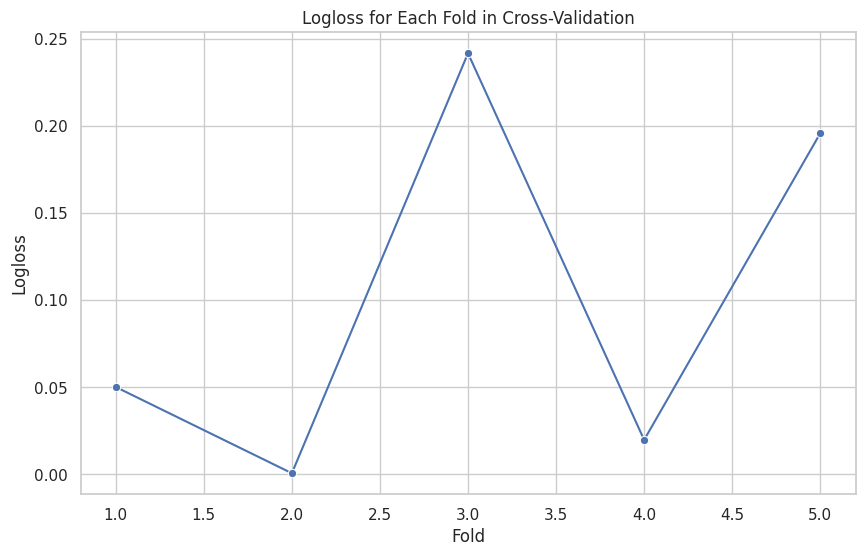

In [ ]:
import lightgbm as lgb
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold

# Iris 데이터셋 로드
iris = load_iris()
X, y = iris.data, iris.target

# Stratified K-Fold를 사용한 교차 검증
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logloss_list = []

for train_idx, val_idx in cv.split(X, y):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # LightGBM 데이터셋 생성
    train_data = lgb.Dataset(X_train, label=y_train)
    val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

    # LightGBM 모델 파라미터 설정
    params = {
        'objective': 'multiclass',
        'num_classes': 3,
        'metric': 'multi_logloss',
        'boosting_type': 'gbdt',
        'num_leaves': 31,
        'learning_rate': 0.05,
        'feature_fraction': 0.9,
        'early_stopping_rounds' : 50,  # Early stopping 적용 (50회 연속 개선 없을 때)
    }

    # LightGBM 모델 훈련
    num_round = 1000
    bst = lgb.train(
        params,
        train_data,
        num_round,
        valid_sets=[train_data, val_data],
    )

    # 해당 폴드의 Logloss 저장
    logloss_list.append(bst.best_score['valid_1']['multi_logloss'])

# 각 폴드에 대한 Logloss를 시각화
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.lineplot(x=range(1, len(logloss_list) + 1), y=logloss_list, marker='o')
plt.xlabel('Fold')
plt.ylabel('Logloss')
plt.title('Logloss for Each Fold in Cross-Validation')
plt.show()

# config

In [ ]:
import time
import math
import datetime

# Settings
split_t = True
split_n = 4 # Fix for group by Year
n_reapts = 1 # Fix for group by Year
random_state = 42
n_estimators = 3000 # 9999
early_stopping_rounds = 200
n_trials = 100 # 2000
verbose = False
device = 'cpu'

# Fix seed
random.seed(random_state)
random_state_list = random.sample(range(9999), n_reapts)

# metrics
def aucscore(y_true, y_pred):
    return roc_auc_score(y_true, y_pred)

metric = aucscore
metric_name = metric.__name__.upper()

# To calculate runtime
def sec_to_minsec(t):
    min_ = int(t / 60)
    sec = int(t - min_*60)
    return min_, sec

# Process

# Suppress warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from colorama import Style, Fore
blk = Style.BRIGHT + Fore.BLACK
red = Style.BRIGHT + Fore.RED
blu = Style.BRIGHT + Fore.BLUE
res = Style.RESET_ALL

# Plot

In [ ]:
def plot_eval_metric(lossfunc_key, _eval_results, _best_iters, ml_name, file_png):

    if ml_name == 'tabnet':
        _df_metric = pd.DataFrame(index = _eval_results.keys())
        _df_metric['value'] = _eval_results.values()
        _train = _df_metric['value'].apply(lambda x: x[f'train_{lossfunc_key}'])
        _valid = _df_metric['value'].apply(lambda x: x[f'val_{lossfunc_key}'])
    elif ml_name == 'cat':
        _df_metric = pd.DataFrame(index = _eval_results.keys())
        _df_metric['value'] = _eval_results.values()
        _train = _df_metric['value'].apply(lambda x: x['validation_0'][f'{lossfunc_key}'])
        _valid = _df_metric['value'].apply(lambda x: x['validation_1'][f'{lossfunc_key}'])
    else:
        _df_metric = pd.DataFrame.from_dict(_eval_results).T
        _train = _df_metric['train'].apply(lambda x: x[lossfunc_key])
        _valid = _df_metric['val'].apply(lambda x: x[lossfunc_key])

    n_cols = 5
    n_splits = len(_eval_results)
    n_rows = int(np.ceil(n_splits / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4), dpi=150, sharex=False, sharey=True)
    ax = axes.flatten()

    for i, (_t, _v, _best_iter) in enumerate(zip(_train, _valid, _best_iters)):
        #_x_range = range(1, len(_t) + 1)
        _x_range = range(0, len(_t) )
        #sns.lineplot(x = _x_range, y = _t, ax=ax[i], label='train', color='red', )
        #sns.lineplot(x = _x_range, y = _v, ax=ax[i], label='val', color='blue', )
        ax[i].plot( _x_range, _t, label='train', color='red', )
        ax[i].plot( _x_range, _v, label='val', color='blue', )
        ax[i].axvline(x = _best_iter, color='gray', linestyle='--', )#label='Early Stopping',)

        ax[i].spines['top'].set_visible(False)
        ax[i].spines['right'].set_visible(False)
        ax[i].set_title(f'Fold {i+1}', fontsize=15, fontweight='bold')

        ax[i].set_xlim(0, len(_t) + 1)
        ax[i].set_ylim(0, 1)
        ax[i].set_xlabel('Boosting Round', fontsize=12)
        ax[i].set_ylabel(f'{lossfunc_key}', fontsize=12)
        ax[i].legend(loc='upper right', title=lossfunc_key)
        ax[i].grid(True)

    for j in range(i+1, n_rows * n_cols):
        ax[j].axis('off')

    plt.tight_layout()
    plt.savefig(file_png)
    plt.show()

def plot_feature_importance(type, fi, file_png):
    n_cols = 2
    n_splits = len(type)
    n_rows = int(np.ceil(n_splits / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 6), dpi=150)
    ax = axes.flatten()

    for i, name in enumerate(type):
        _df_feature = fi[[col for col in fi.columns if col.startswith(name)]].mean(axis=1)

        _df_feature_sort = _df_feature.sort_values(ascending=False)
        #_df_feature_sort = _df_feature_sort.head(20)
        #display(_df_feature_sort)
        _df_feature_sort = _df_feature_sort[_df_feature_sort.values>0]
        sns.barplot(x = _df_feature_sort.values, y = _df_feature_sort.index,
                    color='#1E90FF', linewidth=0.5,  ax=ax[i])

        ax[i].set_title(f'{name}', fontdict={'fontweight': 'bold'})
        ax[i].set_xlabel("Importance", fontsize=12)
        ax[i].set_ylabel("Feature", fontsize=12)
        ax[i].spines['right'].set_visible(False)
        ax[i].spines['top'].set_visible(False)

    for j in range(i+1, n_rows * n_cols):
        ax[j].axis('off')

    plt.tight_layout()
    plt.savefig(file_png)
    plt.show()

def plot_score_dist_old(df_score):
    #fig, axes = plt.subplots(1,1, figsize=(6,4), dpi=150)

    #plt.figure(figsize=(5, 3), dpi=150)
    g=sns.displot(data=df_score, x='y_pred', kind="kde", hue='y', fill=True, legend=False,
                  height=3, aspect=1.5)
    g.add_legend(title='Variants', labels=['(likely) pathogenic','(likely) benign'])
    #plt.legend(title='Variants', labels=['(likely) pathogenic','(likely) benign'])  # 범례 라벨 설정
    g.set_axis_labels("Score", "Density")
    g.set_titles("test")
    plt.show()

def plot_score_dist(df_score):
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), dpi=150)
    ax = axes.flatten()

    sns.kdeplot(data=df_score, x='y_pred',  hue='y', fill=True, legend=False, ax=ax[0])

    ax[0].set_xlabel('Score', fontsize=12)
    ax[0].set_ylabel('Density', fontsize=12)
    #ax[0].set_titles("test", fontdict={'fontweight': 'bold', 'fontsize' :15})
    ax[0].legend(loc='upper left', title='Variants', labels=['(likely) pathogenic','(likely) benign'])
    ax[1].axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_training_process(lossfunc_key, eval_results_, best_iters_, early_stopping_rounds, file_png):

    metric_score_folds = pd.DataFrame.from_dict(eval_results_).T
    fit_rmsle = metric_score_folds.fit.apply(lambda x: x[lossfunc_key])
    val_rmsle = metric_score_folds.val.apply(lambda x: x[lossfunc_key])

    n_splits = len(metric_score_folds)
    n_rows = math.ceil(n_splits / 3)

    fig, axes = plt.subplots(n_rows, 3, figsize=(20, n_rows * 4), dpi=150)
    ax = axes.flatten()

    for i, (f, v, best_iter) in enumerate(zip(fit_rmsle, val_rmsle, best_iters_)):
        sns.lineplot(f, color='#B90000', ax=ax[i], label='fit')
        sns.lineplot(v, color='#048BA8', ax=ax[i], label='val')
        ax[i].legend()
        ax[i].spines['top'].set_visible(False)
        ax[i].spines['right'].set_visible(False)
        ax[i].set_title(f'Fold {i}', fontdict={'fontweight': 'bold'})

        color = ['#048BA8', '#90A6B1']
        span_range = [[0, best_iter], [best_iter + 10, best_iter + early_stopping_rounds]]

        for idx, sub_title in enumerate([f'Best\nIteration: {best_iter}', f'Early\n Stopping: {early_stopping_rounds}']):
            ax[i].annotate(sub_title,
                           xy=(sum(span_range[idx]) / 2, 4000),
                           xytext=(0, 0),
                           textcoords='offset points',
                           va="center",
                           ha="center",
                           color="w",
                           fontsize=12,
                           fontweight='bold',
                           bbox=dict(boxstyle='round4', pad=0.4, color=color[idx], alpha=0.6))
            ax[i].axvspan(span_range[idx][0] - 0.4, span_range[idx][1] + 0.4, color=color[idx], alpha=0.07)

        ax[i].set_xlim(0, best_iter + 20 + early_stopping_rounds)
        ax[i].set_xlabel('Boosting Round', fontsize=12)
        ax[i].set_ylabel(f'{lossfunc_key}', fontsize=12)
        ax[i].legend(loc='upper right', title=lossfunc_key)

    for j in range(i+1, n_rows * 3):
        ax[j].axis('off')

    plt.tight_layout()
    plt.savefig(file_png)
    plt.show()



def plot_feature_importance(fi, file_png):
    fi_gain = fi[[col for col in fi.columns if col.startswith('gain')]].mean(axis=1)
    fi_splt = fi[[col for col in fi.columns if col.startswith('weight')]].mean(axis=1)
    fi_cove = fi[[col for col in fi.columns if col.startswith('cover')]].mean(axis=1)

    fig, ax = plt.subplots(1, 3, figsize=(18, 6), dpi=150)

    # Split fi.
    data_splt = fi_splt.sort_values(ascending=False)
    data_splt = data_splt.head(20)
    sns.barplot(x=data_splt.values, y=data_splt.index,
                color='#1E90FF', linewidth=0.5, edgecolor="black", ax=ax[0])
    ax[0].set_title(f'Feature Importance "Weight"', fontdict={'fontweight': 'bold'})
    ax[0].set_xlabel("Importance", fontsize=12)
    ax[0].spines['right'].set_visible(False)
    ax[0].spines['top'].set_visible(False)

    # Gain fi.
    data_gain = fi_gain.sort_values(ascending=False)
    data_gain = data_gain.head(20)
    sns.barplot(x=data_gain.values, y=data_gain.index,
                color='#4169E1', linewidth=0.5, edgecolor="black", ax=ax[1])
    ax[1].set_title(f'Feature Importance "Gain"', fontdict={'fontweight': 'bold'})
    ax[1].set_xlabel("Importance", fontsize=12)
    ax[1].spines['right'].set_visible(False)
    ax[1].spines['top'].set_visible(False)
    #display(data_gain.head(20))

    # Gain fi.
    data_cove = fi_cove.sort_values(ascending=False)
    data_cove = data_cove.head(20)
    sns.barplot(x=data_cove.values, y=data_cove.index, color='#4169E1', linewidth=0.5, edgecolor="black", ax=ax[2])
    ax[2].set_title(f'Feature Importance "Cover"', fontdict={'fontweight': 'bold'})
    ax[2].set_xlabel("Importance", fontsize=12)
    ax[2].spines['right'].set_visible(False)
    ax[2].spines['top'].set_visible(False)


    plt.tight_layout()
    plt.savefig(file_png)
    plt.show()

    #plt.figure(figsize=(20, 10))

    #sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False))
    #plt.title('LightGBM Features (avg over folds)')
    #plt.tight_layout()
    #plt.show()
    #plt.savefig('lgbm_importances-01.png')


def plot_true_oof(df, title=''):
    plt.figure(figsize=(15, 6))
    sns.lineplot(data=df, x="date", y="true", label="True", alpha=0.7, color='blue')
    sns.lineplot(data=df, x="date", y="oof", label="Out of Sample", alpha=0.4, color='red')

    plt.xlabel('Date')
    plt.ylabel('Number of Products Sold')
    plt.title(f'Number of Products Sold: True vs Out-of-fold {title}', fontweight='bold', fontsize=10)

    plt.legend(loc='upper right')
    plt.tight_layout()
    sns.despine()  # グラフの枠線を削除

    plt.show()

#===============================================================

# Class: Multi_Train

In [ ]:
from colorama import Style, Fore, Back
bgy = Back.YELLOW
blk = Style.BRIGHT + Fore.BLACK
red = Style.BRIGHT + Fore.RED
blu = Style.BRIGHT + Fore.BLUE
grn = Style.BRIGHT + Fore.GREEN
mgt = Style.BRIGHT + Fore.MAGENTA
wht = Style.BRIGHT + Fore.WHITE
res = Style.RESET_ALL

print(f'{bgy}{red}Fold: {blu}Fold: {grn}Fold: {mgt}Fold: Fold:')

Fold: Fold: Fold: Fold: Fold:


In [ ]:
class Multi_Train:
    def __init__(self, split_data_n, X_Train, y_Train, trial_num):
        self.split_data_n = split_data_n
        self.params = None
        self.ml_name = None
        self.X_Train = X_Train
        self.y_Train = y_Train
        self.best_model = None
        self.best_models = []
        self.trial_num = trial_num
        self.early_stopping_rounds = 10
        self.result = None
        self.folder_path = None

    def _create_folder(self):
        if not os.path.exists(self.folder_path):
            os.makedirs(self.folder_path)

    def execute(self, ml_name, params, pruning, fold_name):
        _feature_importances = pd.DataFrame(index = self.X_Train.columns)
        _oob = pd.DataFrame(index = self.X_Train.index)
        _eval_results = {}
        _best_iters = []
        val_scores = []
        eval_name = 'auc'
        #eval_name = 'binary_logloss'
        self.params = params
        self.ml_name = ml_name
        self.pruning = pruning
        self.fold_name = fold_name

        _oob2 = pd.DataFrame(index = X_test.index)
        _oob2.loc[y_test.index, 'y'] = y_test

        self.folder_path = os.path.join(os.getcwd(), f"{fold_name}/trial_{self.trial_num}/")
        self._create_folder()

        model = None
        if self.ml_name == 'tabnet':
            model = TabNetClassifier(**self.params)

        print(f"{bgy}{grn} [!!! Start] Train: {self.ml_name} | Trial: {self.trial_num} | Total Folds: {res}",)
        for i, (_X_train, _X_val, _y_train, _y_val, idx_val) in enumerate(self.split_data_n):
            fold = i+1
            _oob.loc[_y_val.index, 'y'] = _y_val
            _oob.loc[_y_val.index, 'fold'] = fold

            #print(_X_train.shape, _X_val.shape, _X_train.index[0], _X_val.index[0], type(_X_train), type(_y_train),)
            print(f'Train: {_X_train.shape[0]} / Val: {_X_val.shape[0]}')

            val_score = 0
            val_error = 0
            _eval_names = []
            start_time = time.time()

            if self.ml_name == 'cat':
                set_train = Pool(_X_train, _y_train)
                set_valid = Pool(_X_val, _y_val)
                set_test = X_test

                _eval_names = [self.params['eval_metric'].upper(), 'Logloss']
                _importance_types = ['gain']
                callbacks = []
                callbacks.append(self.pruning) if self.pruning else print("!!! no pruning")

                model = CatBoostClassifier(**self.params)
                model.fit(set_train, eval_set=[set_train, set_valid], use_best_model=True,
                        early_stopping_rounds=10, verbose = 0, #100
                          callbacks = callbacks,)

                _eval_results[fold] = model.evals_result_
                best_iter = model.best_iteration_
                val_score = _eval_results[fold]['validation_1'][eval_name.upper()][best_iter]

                for _imp_type in _importance_types:
                    _feature_importances[f'{_imp_type}_{fold}'] = model.feature_importances_

            if self.ml_name == 'xgb':
                set_train = xgb.DMatrix(_X_train, _y_train)
                set_valid = xgb.DMatrix(_X_val, _y_val)
                set_test = xgb.DMatrix(X_test)

                _eval_names = self.params['eval_metric']
                _importance_types = ['weight', 'gain', 'cover', 'total_gain', 'total_cover']

                model, _eval_results[fold] = self._xgb_train(set_train, set_valid)
                val_error = _eval_results[fold]['val']['error'][model.best_iteration]
                val_score = _eval_results[fold]['val'][eval_name][model.best_iteration]
                best_iter = model.best_iteration
                #print(_eval_results[fold])
                for _imp_type in _importance_types:
                    _feature_importances[f'{_imp_type}_{fold}'] = _feature_importances.index.map(model.get_score(importance_type = _imp_type))

            if self.ml_name == 'lgb':
                set_train = lgb.Dataset(_X_train, _y_train)
                set_valid = lgb.Dataset(_X_val, _y_val)
                set_test  = X_test

                _eval_names = self.params['metric']
                _importance_types = ['gain', 'split']

                model, _eval_results[fold] = self._lgb_train(set_train, set_valid)

                val_score = model.best_score['val'][eval_name]
                best_iter = model.best_iteration

                for _imp_type in _importance_types:
                    _feature_importances[f'{_imp_type}_{fold}'] = model.feature_importance(importance_type = _imp_type)

                set_valid = _X_val

            if self.ml_name == 'tabnet':
                set_valid = [(_X_train.values, _y_train.values), (_X_val.values, _y_val.values)]
                set_test  = X_test.values

                _eval_names = ['auc', 'accuracy', 'logloss'] #self.params['metric']
                _importance_types = ['gain']
                #print('!!!',model)
                model.fit(X_train = _X_train.values, y_train = _y_train.values,
                          eval_set = set_valid,
                          eval_name=['train', 'val'],
                          eval_metric = _eval_names,
                          max_epochs=100,
                          patience = 10, #early stopping
                          #eval_metric=['logloss','auc', 'balanced_accuracy', 'accuracy'],
                          num_workers=NUM_DATALOADER_WORKERS,
                          drop_last=False,
                          #max_epochs=10,weights=1,
                          batch_size=512,
                          )
                #print("!!!",model.history)
                _eval_results[fold] = model.history.history
                best_iter = model.best_epoch
                val_score = model.history[f'val_{eval_name}'][best_iter]

                _feature_importances[f'gain_{fold}'] = model.feature_importances_

                set_valid = _X_val.values

            self.best_model = model
            self.best_models.append(model)

            _best_iters.append(best_iter)
            val_scores.append(val_score)

            end_time = time.time()
            min, sec = sec_to_minsec(end_time - start_time)

            print(f'{mgt} ===> Train: {self.ml_name} | Trial: {self.trial_num} | {blu}Fold: {fold} | SEED- {mgt}| {blu}{eval_name}: {val_score:.5f} {mgt}| {blu}Best iteration: {best_iter:>4} {mgt}| {blu}Runtime {min}min {sec}s{res}')
            #print(f'!!!Accuracy: {1-val_error:.5f}')
            #self._val_model(fold, set_valid, _y_val)
            y_pred = self._pred_model(type_pred = f'val{fold}', set_pred = set_valid, y_real = _y_val)
            _oob.loc[_y_val.index, 'y_pred'] = y_pred

        mean_cv_score = np.mean(val_scores)

        print(f'{mgt}{"*" * 100}{res}')
        #print(f'{mgt} ===> Train: {self.ml_name} | Trial {self.trial_num} |
        #{blu}Mean({eval_name}) : {mgt}{mean_cv_score:.5f}{res}')
        print(f"{bgy}{grn} [!!! End] Train: {self.ml_name} | Trial: {self.trial_num} | Total Folds: {fold} | {blu}Mean({eval_name}) : {mgt}{mean_cv_score:.5f}{res}",)

        self._save_png(_eval_names, _eval_results, _best_iters, _importance_types, _feature_importances)
        self._save_csv(_eval_results, 'eval')
        self._save_csv(_feature_importances, 'feature')

        _oob['y'] = _oob['y'].astype('int')
        _oob['fold'] = _oob['fold'].astype('int')
        self._plot_roc_pr(f'val', _oob)

        _oob['y'] = _oob['y'].astype('category')
        plot_score_dist(_oob)

        y_pred = self._pred_model(type_pred = f'test', set_pred = set_test, y_real = y_test)
        _oob2.loc[y_test.index, 'y_pred'] = y_pred
        _oob2['y'] = _oob2['y'].astype('int').astype('category')
        plot_score_dist(_oob2)

        y_pred = self._pred_models(type_pred = f'test', set_pred = set_test, y_real = y_test)
        _oob2.loc[y_test.index, 'y_pred'] = y_pred
        _oob2['y'] = _oob2['y'].astype('int').astype('category')
        plot_score_dist(_oob2)

        self._save_model()
        self._save_csv('', 'result')

        display(self.result.T)

        return mean_cv_score

    def _xgb_train(self, set_train, set_valid):
        evals_results = {}
        set_evals = [(set_train, 'train'), (set_valid, 'val')]
        callbacks = []
        callbacks.append(xgb.callback.EarlyStopping(self.early_stopping_rounds, data_name='val', save_best=True,))
        callbacks.append(self.pruning) if self.pruning else print("!!! no pruning")

        model = xgb.train(params = self.params,
                          dtrain = set_train,
                          evals = set_evals,
                          evals_result = evals_results,
                          verbose_eval = False,
                          num_boost_round = self.params['n_estimators'],
                          callbacks = callbacks,
                          )
        print("!!! end:model")
        return model, evals_results

    def _lgb_train(self, set_train, set_valid):
        evals_results = {}
        set_evals = [set_train, set_valid]
        callbacks = []
        callbacks.append(lgb.early_stopping(stopping_rounds = self.early_stopping_rounds))
        callbacks.append(lgb.record_evaluation(evals_results))
        callbacks.append(self.pruning) if self.pruning else print("!!! no pruning")

        model = lgb.train(self.params,
                          set_train,
                          num_boost_round = self.params['num_iterations'],
                          valid_sets = set_evals,
                          valid_names = ['train','val'],
                          callbacks = callbacks,
                          )
        return model, evals_results

    def _save_png(self, _eval_names, _eval_results, _best_iters, _importance_types, _feature_importances):
        for _eval_name in _eval_names:
            continue
            file_name = f'trial{self.trial_num}_eval_{_eval_name}.png'
            file_png = os.path.join(self.folder_path, file_name)
            plot_eval_metric(_eval_name, _eval_results, _best_iters, self.ml_name, file_png)

        file_name = f'trial{self.trial_num}_feature.png'
        file_png = os.path.join(self.folder_path, file_name)
        plot_feature_importance(_importance_types, _feature_importances, file_png)

    def _save_model(self):
        file_name = f'trial{self.trial_num}_model.pkl'
        file_pkl = os.path.join(self.folder_path, file_name)

        with open(file_pkl, 'wb') as fw:
            pickle.dump(self.best_model, fw)

    def _save_csv(self, _df, name):
        #file_name = f'trial{self.trial_num}_{name}.txt'
        file_name = f'trial{self.trial_num}_{name}.csv'
        file_csv = os.path.join(self.folder_path, file_name)

        if name == 'result':
            self.result.T.to_csv(file_csv, sep="\t")
        elif name == 'eval':
            with open(file_csv, 'w') as f:
                json.dump(_df, f)
        else:
            _df.to_csv(file_csv, sep="\t")

    def _pred_model(self, type_pred, set_pred, y_real, show_df = False):
        print(type_pred)
        if self.ml_name == 'tabnet' or self.ml_name == 'cat':
            pred_proba = self.best_model.predict_proba(set_pred)
            pred_proba = pred_proba[:,1]
        else:
            pred_proba = self.best_model.predict(set_pred)
        y_hat = pred_proba.reshape(-1, 1)

        name = f'trial{self.trial_num}_{type_pred}_roc'
        file_name = f'{name}.png'
        file_png = os.path.join(self.folder_path, file_name)

        thres_lst = [0.5]
        _df = evaluation_thres(name, y_real, y_hat, thres_lst, save_png = file_png)
        if show_df:
            display(_df)
        else:
            self.result = pd.concat([self.result,_df], axis=1)

        return pred_proba

    def _plot_roc_pr(self, type_pred, _df_oob):
        print(type_pred)

        name = f'trial{self.trial_num}_{type_pred}_roc_multi'
        file_name = f'{name}.png'
        file_png = os.path.join(self.folder_path, file_name)

        plot_roc_prc_multi('a', _df_oob, file_png)

        name = f'trial{self.trial_num}_{type_pred}_roc'
        file_name = f'{name}.png'
        file_png = os.path.join(self.folder_path, file_name)

        thres_lst = [0.5]
        _df = evaluation_thres(name, _df_oob['y'], _df_oob['y_pred'].values.reshape(-1, 1), thres_lst, save_png = file_png)
        self.result = pd.concat([self.result,_df], axis=1)

    def _pred_models(self, type_pred, set_pred, y_real, show_df = False):
        print(type_pred)
        if self.ml_name == 'tabnet' or self.ml_name == 'cat':
            pred_proba = self.best_model.predict_proba(set_pred)
            pred_proba = pred_proba[:,1]
        else:
            pred_probas = np.array([model.predict(set_pred) for model in self.best_models])
            pred_proba = np.mean(pred_probas, axis=0)
        y_hat = pred_proba.reshape(-1, 1)

        name = f'trial{self.trial_num}_{type_pred}_roc_10'
        file_name = f'{name}.png'
        file_png = os.path.join(self.folder_path, file_name)

        thres_lst = [0.5]
        _df = evaluation_thres(name, y_real, y_hat, thres_lst, save_png = file_png)
        if show_df:
            display(_df)
            self.result = _df
        else:
            self.result = pd.concat([self.result,_df], axis=1)

        return pred_proba

## exe_xgb
* https://xgboost.readthedocs.io/en/stable/parameter.html

In [ ]:
_name1 = 'test'

_name = 'clinvar_and_0.0003'
X_Train, y_Train, head_Train = test_X[_name], test_y[_name], test_head[_name]
X_test, y_test, head_test = X_Train, y_Train, head_Train
print(X_Train.shape, y_Train.value_counts())

(50883, 34) clnSig2
1    26383
0    24500
Name: count, dtype: int64


!!! cuda 1732600179.4603655 test_default_xgb clinvar_and_0.0003
10 skf 0.25
 [!!! Start] Train: xgb | Trial: clinvar_and_0.0003 | Total Folds: 
StratifiedKFold
Train: 45794 / Val: 5089
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: clinvar_and_0.0003 | Fold: 1 | SEED- | auc: 0.99836 | Best iteration:   58 | Runtime 0min 0s
val1
Train: 45794 / Val: 5089
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: clinvar_and_0.0003 | Fold: 2 | SEED- | auc: 0.99770 | Best iteration:   55 | Runtime 0min 0s
val2
Train: 45794 / Val: 5089
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: clinvar_and_0.0003 | Fold: 3 | SEED- | auc: 0.99884 | Best iteration:   63 | Runtime 0min 0s
val3
Train: 45795 / Val: 5088
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: clinvar_and_0.0003 | Fold: 4 | SEED- | auc: 0.99844 | Best iteration:   84 | Runtime 0min 0s
val4
Train: 45795 / Val: 5088
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: clinvar_and_0.0003 | Fold: 5 | SEED- | auc: 0.99

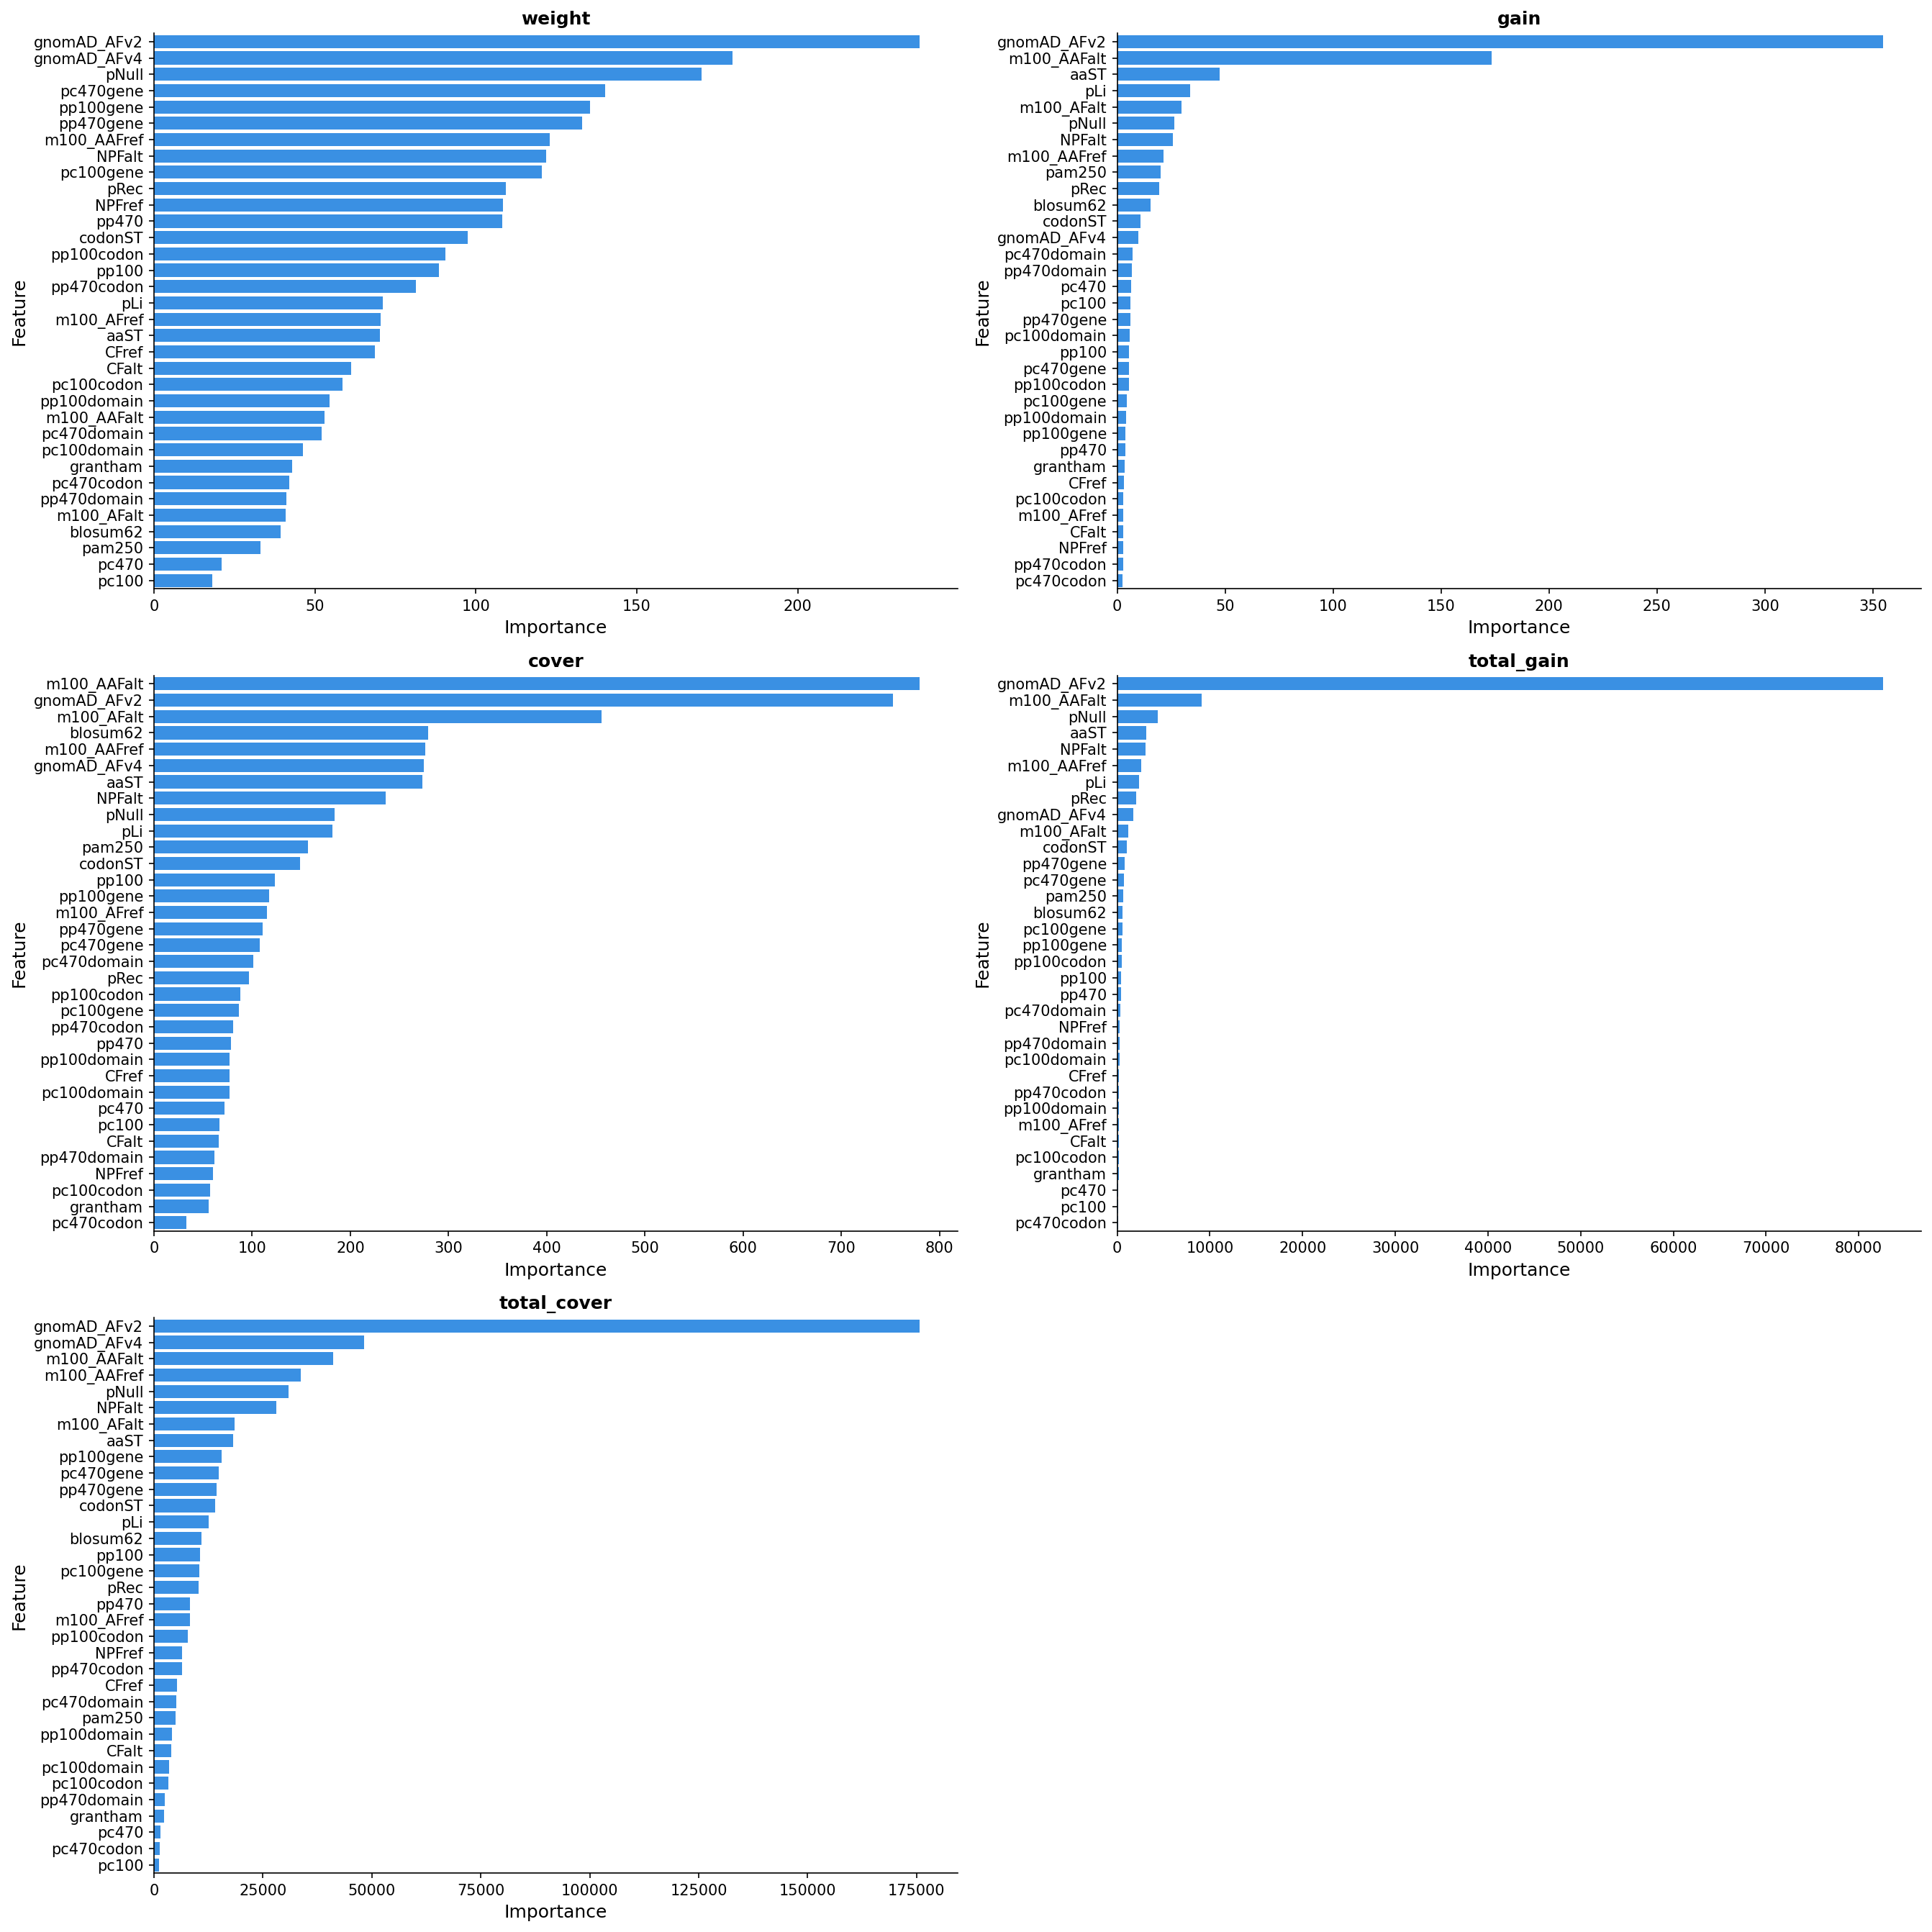

val


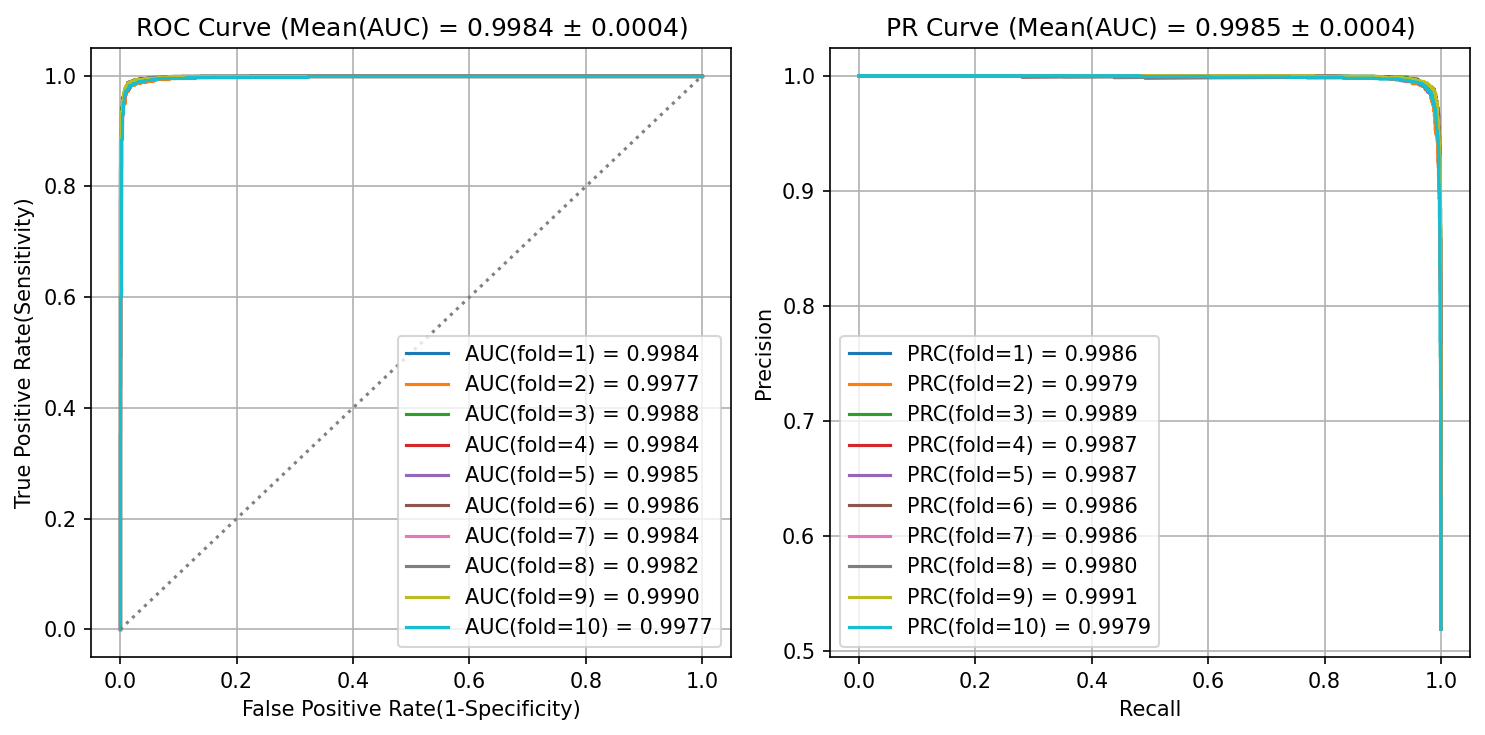

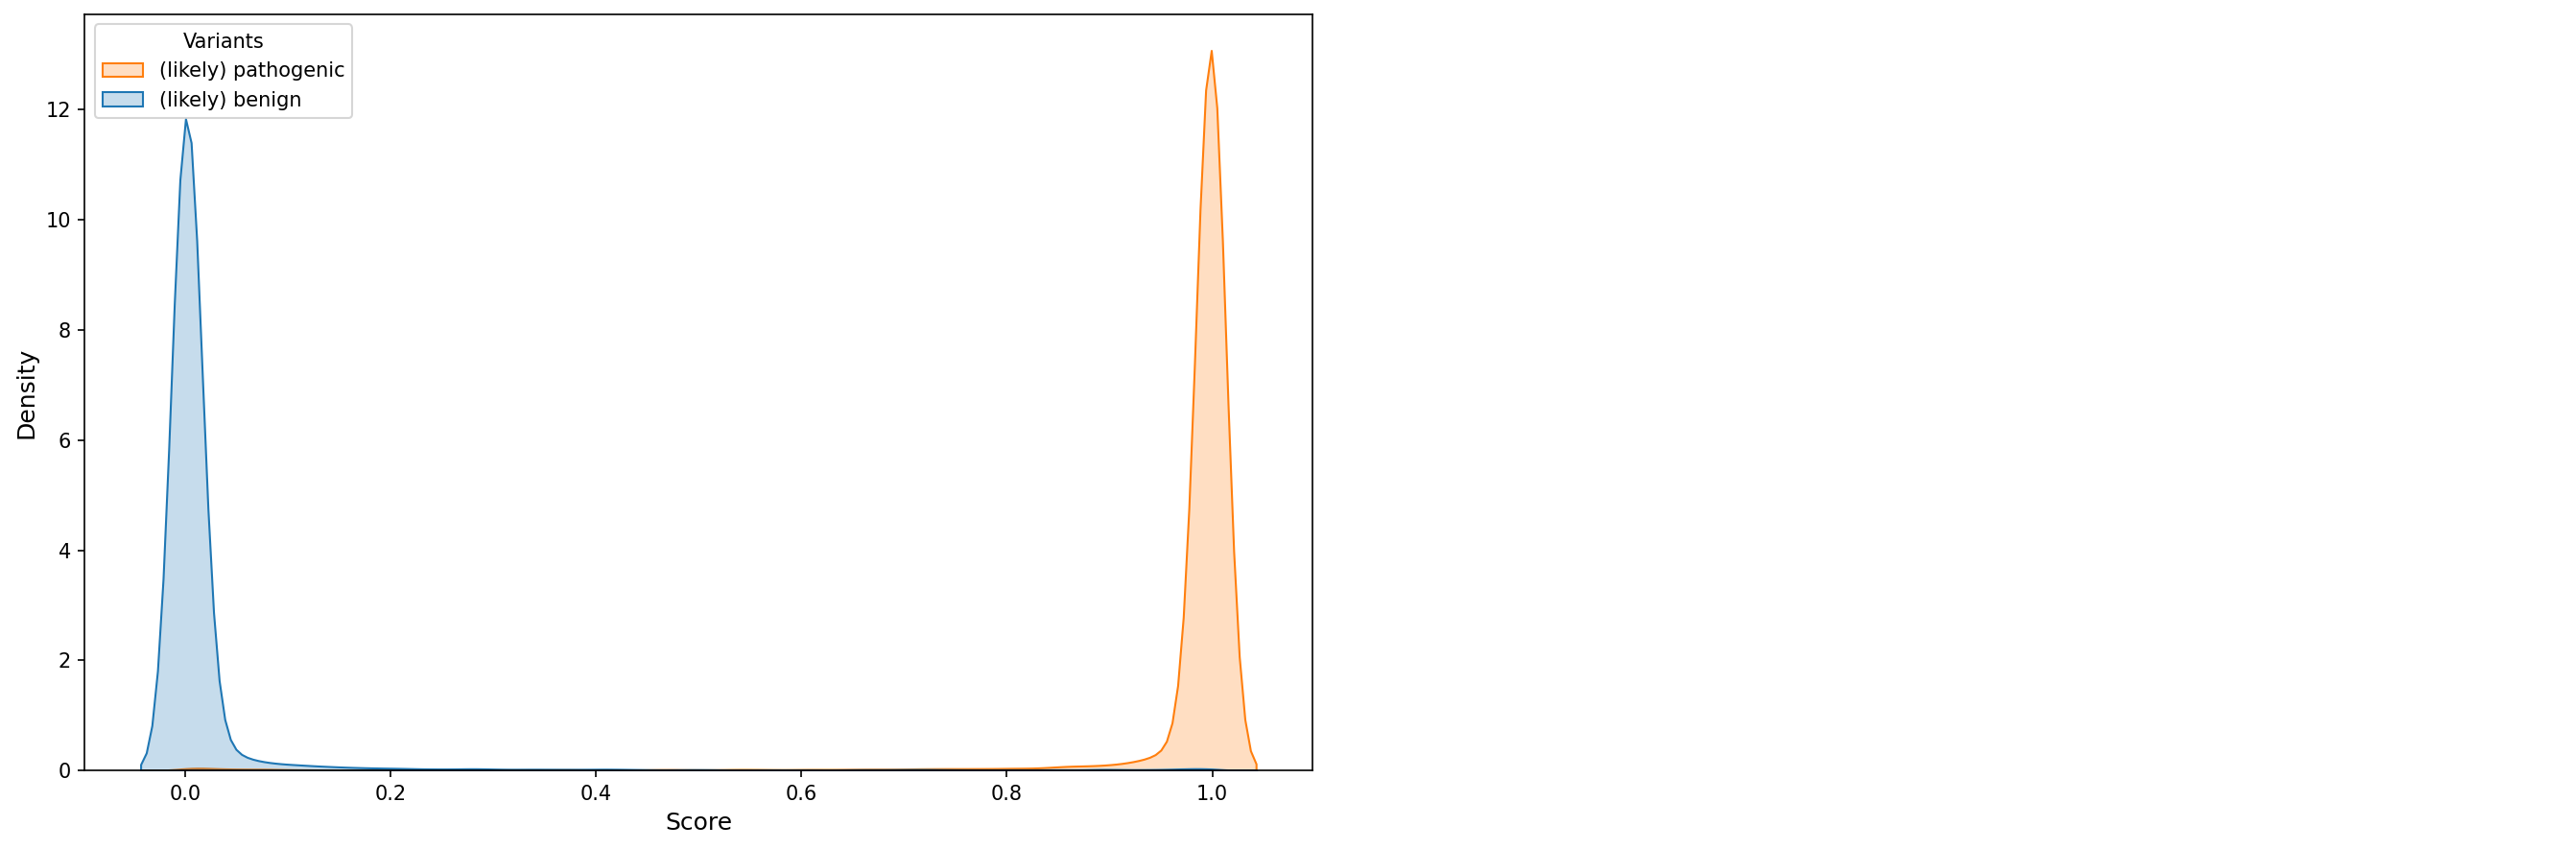

test


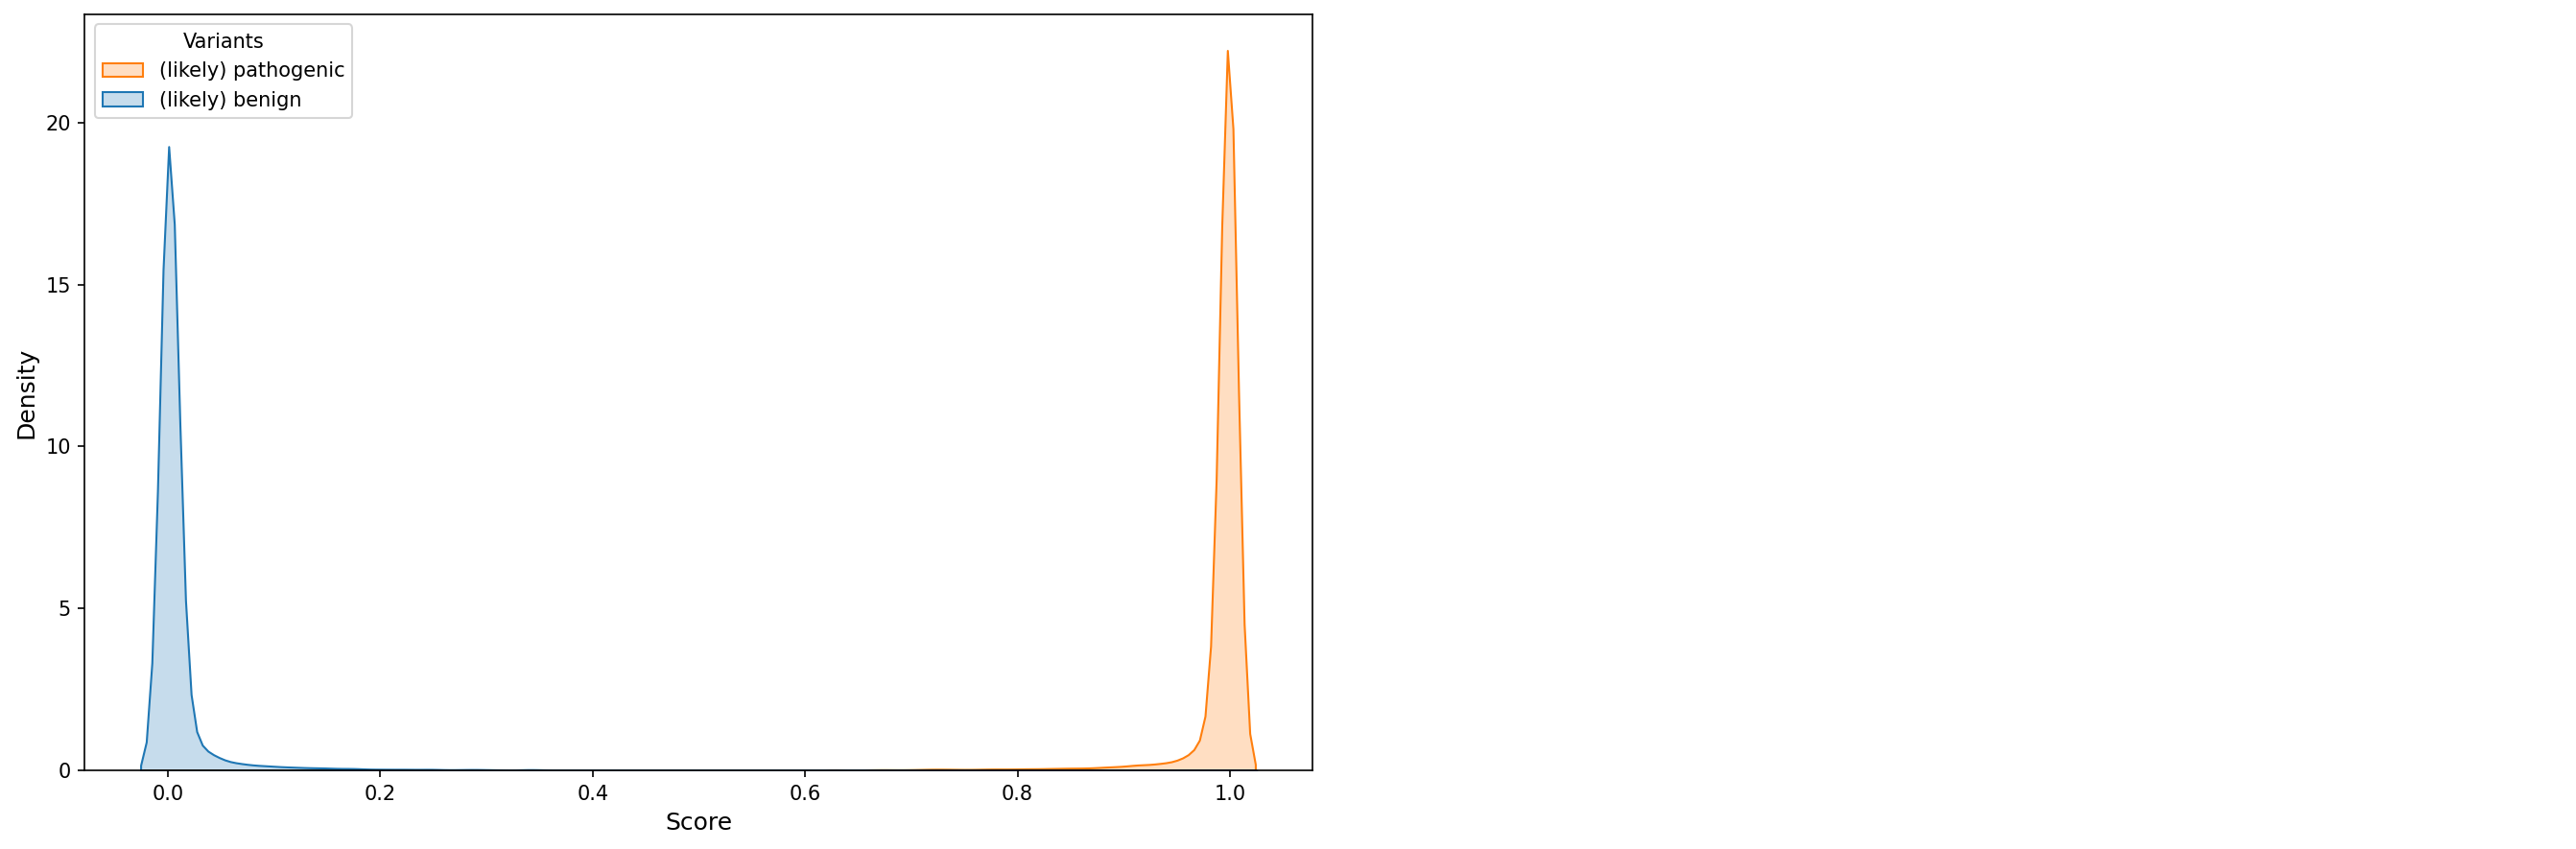

test


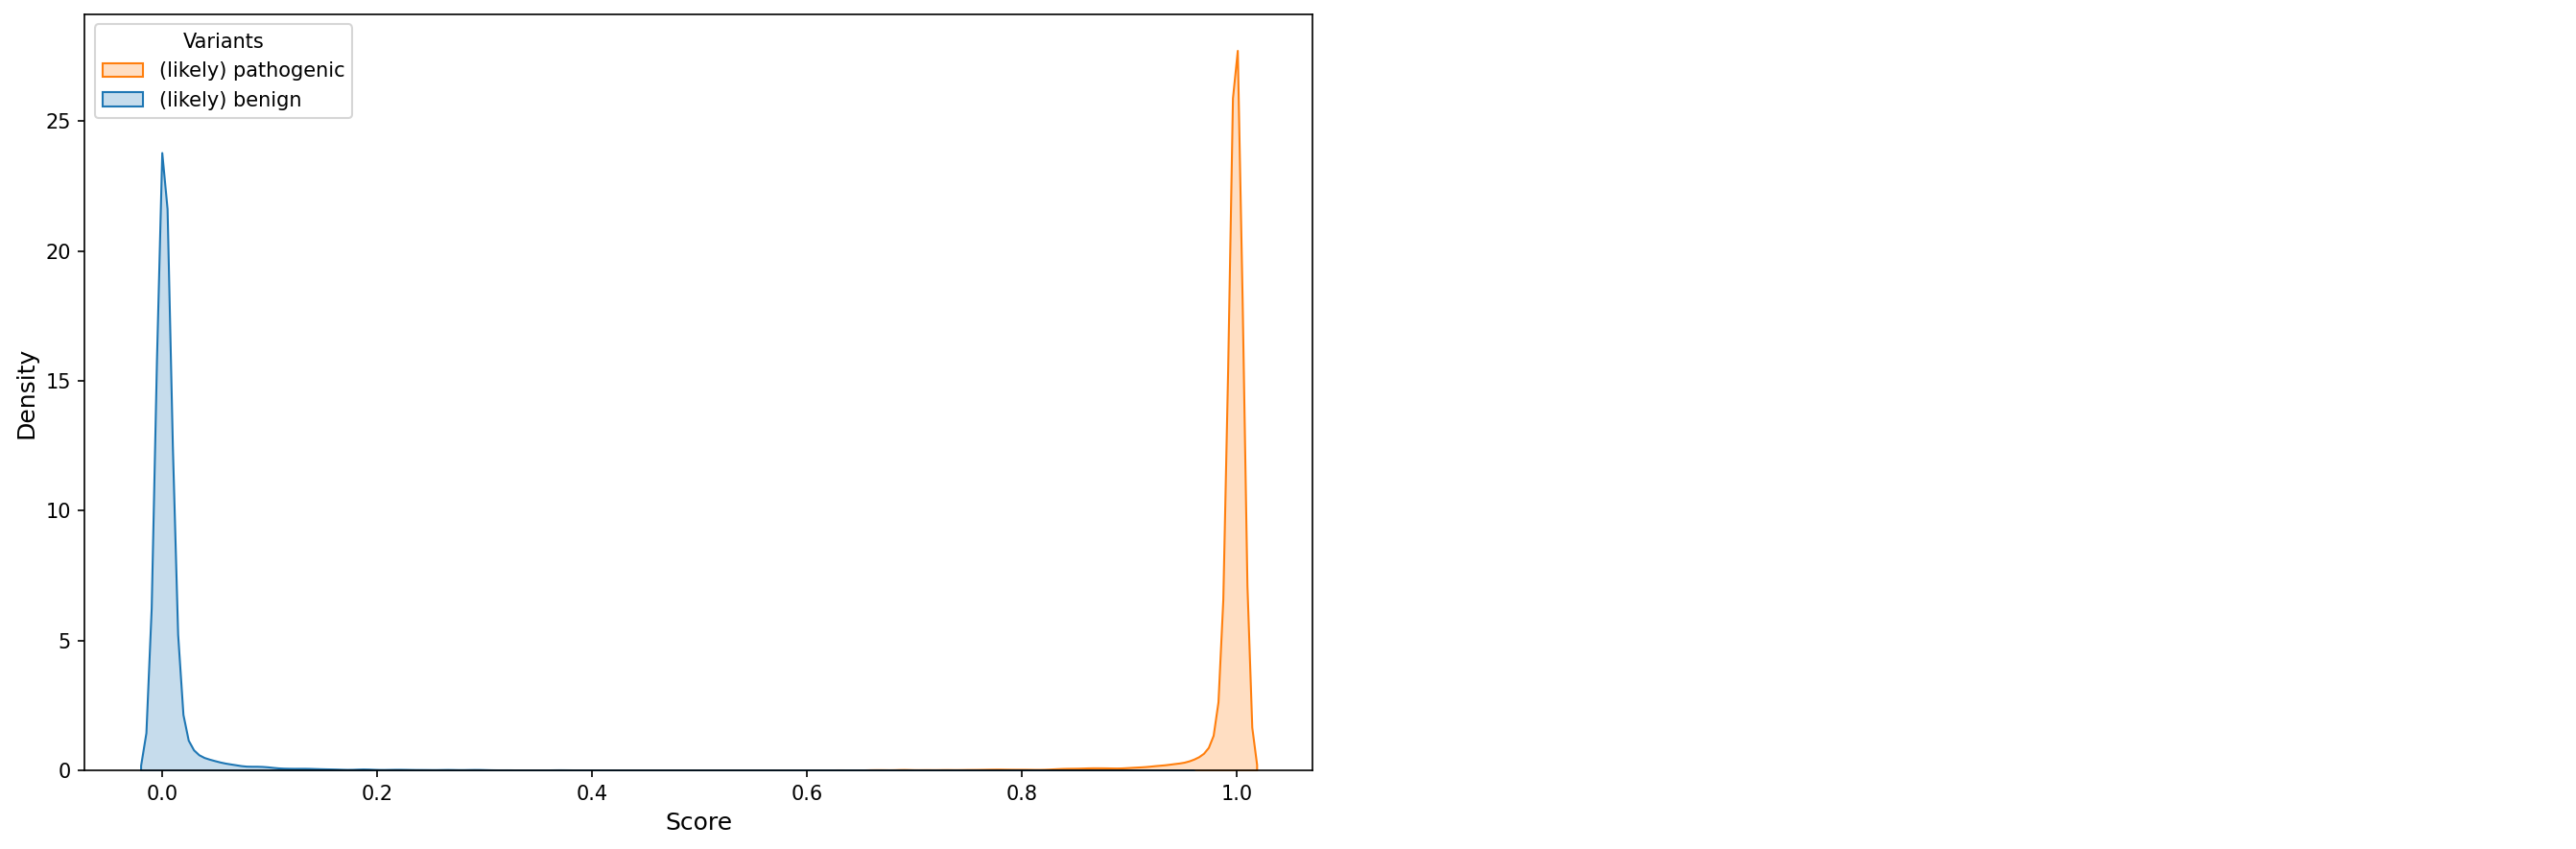

,thres,Accuracy,F1,MCC,Precision,Recall(=Sens),Specificity,AUC,AUCPR,G-mean,PPV,NPV,FNR,FPR,TN,FP,FN,TP
trialclinvar_and_0.0003_val1_roc_0.5000,0.5000,0.9827,0.9833,0.9654,0.9841,0.9826,0.9829,0.9984,0.9986,0.9827,0.9841,0.9813,0.0174,0.0171,2408.0,42.0,46.0,2593.0
trialclinvar_and_0.0003_val1_roc_0.5207,0.5207,0.9831,0.9837,0.9662,0.9855,0.9818,0.9845,0.9984,0.9986,0.9831,0.9855,0.9805,0.0182,0.0155,2412.0,38.0,48.0,2591.0
trialclinvar_and_0.0003_val1_roc_0.4690,0.4690,0.9825,0.9831,0.9650,0.9833,0.9829,0.9820,0.9984,0.9986,0.9825,0.9833,0.9816,0.0171,0.0180,2406.0,44.0,45.0,2594.0
trialclinvar_and_0.0003_val2_roc_0.5000,0.5000,0.9823,0.9829,0.9646,0.9855,0.9803,0.9845,0.9977,0.9979,0.9824,0.9855,0.9789,0.0197,0.0155,2412.0,38.0,52.0,2587.0
trialclinvar_and_0.0003_val2_roc_0.4415,0.4415,0.9829,0.9835,0.9658,0.9848,0.9822,0.9837,0.9977,0.9979,0.9829,0.9848,0.9809,0.0178,0.0163,2410.0,40.0,47.0,2592.0
trialclinvar_and_0.0003_val2_roc_0.3606,0.3606,0.9821,0.9828,0.9642,0.9829,0.9826,0.9816,0.9977,0.9979,0.9821,0.9829,0.9812,0.0174,0.0184,2405.0,45.0,46.0,2593.0
trialclinvar_and_0.0003_val3_roc_0.5000,0.5000,0.9845,0.9850,0.9689,0.9860,0.9841,0.9849,0.9988,0.9989,0.9845,0.9860,0.9829,0.0159,0.0151,2413.0,37.0,42.0,2597.0
trialclinvar_and_0.0003_val3_roc_0.4552,0.4552,0.9851,0.9856,0.9701,0.9852,0.9860,0.9841,0.9988,0.9989,0.9850,0.9852,0.9849,0.0140,0.0159,2411.0,39.0,37.0,2602.0
trialclinvar_and_0.0003_val3_roc_0.4628,0.4628,0.9845,0.9850,0.9689,0.9852,0.9848,0.9841,0.9988,0.9989,0.9845,0.9852,0.9837,0.0152,0.0159,2411.0,39.0,40.0,2599.0
trialclinvar_and_0.0003_val4_roc_0.5000,0.5000,0.9845,0.9850,0.9689,0.9856,0.9845,0.9845,0.9984,0.9987,0.9845,0.9856,0.9833,0.0155,0.0155,2412.0,38.0,41.0,2597.0


--- 20.338481187820435 seconds ---


In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
xgb_params = {'booster': 'gbtree', 'verbosity': 1,
              'objective':'binary:logistic',
              'seed': 42, #random_state
              'eval_metric' : ['auc','aucpr','pre', 'error', 'logloss', ],
              #'eval_metric' : ['error','auc','aucpr','pre', 'logloss', ],
              'n_estimators': 1000,
              'eta': 0.3, #0~1 / learning_rate
              'gamma': 0, #0~ / min_split_loss
              'max_depth': 6,
              'min_child_weight': 1,
              'subsample': 1, #0~1
              'lambda': 1, #0~ / L2
              'alpha': 0, #0~ / L1
              'colsample_bytree' : 1, #0~1
              'device': device,
}
ml_name = 'xgb'
#fold_name = f'{ml_name}_default_{X_Train.shape[1]}'
fold_name = f'{_name1}_default_{ml_name}'
_trial_num = _name
split_t = 'skf'
split_n = 10
size_test = 0.25
random_state_list = [42]
start_time = time.time()
print("!!!",device, start_time, fold_name, _trial_num)
splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
split_data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)

multi_model = Multi_Train(split_data_n=split_data_n, X_Train = X_Train, y_Train = y_Train, trial_num = _trial_num)
return_auc = multi_model.execute(ml_name, xgb_params, "", fold_name)
print("--- %s seconds ---" % (time.time() - start_time))

#### predict:xgb

In [ ]:
# xgb
prefix_test = ('clinvar','clinvar2', 'uniprot', 'clingen')
a = (X_test, clinvar2_X, uniprot_X, clingen_X)
b = (y_test, clinvar2_y, uniprot_y, clingen_y)

for i, (_x, _y) in enumerate(zip(a,b)):
    print(prefix_test[i], i, _x.shape, _y.shape, _y[_y==0].shape, _y[_y==1].shape)
    set_test = xgb.DMatrix(_x)
    y_pred = multi_model._pred_models(type_pred = 'val', set_pred = set_test, y_real = _y, show_df=True)


    #_oob = pd.DataFrame(index=_y.index)
    _oob = c[i]
    _oob.loc[_y.index, 'y'] = _y
    _oob['y'] = _oob['y'].astype(int).astype('category')
    _oob.loc[_y.index, 'y_pred'] = y_pred

    plot_score_dist(_oob)

    binarizer = Binarizer(threshold = 0.5)
    binarizer.fit(y_pred.reshape(-1,1))
    thres_pred = binarizer.transform(y_pred.reshape(-1,1))

    plot_classification_report(_oob)

    save_csv = f'{fold_name}/{prefix_test[i]}.{ml_name}.{_trial_num}.predict.oob.csv'
    print("!!! save:", save_csv)
    _oob.to_csv(save_csv, sep="\t", index=False)

    save_csv = f'{fold_name}/{prefix_test[i]}.{ml_name}.{_trial_num}.predict.eval.csv'
    print("!!! save:", save_csv)
    multi_model.result.T.to_csv(save_csv, sep="\t", index=True)


## exe_lgb
* https://lightgbm.readthedocs.io/en/stable/Parameters.html

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
lgb_params = {"objective": "binary",'boosting_type': 'gbdt', "seed": 42, 'verbosity' : -1,
        'metric': ['auc','average_precision', 'binary_error', 'binary_logloss'],
        'num_iterations': 100, #0~ / num_boost_round
        "learning_rate" : 0.1, #0~ / eta
        "max_depth" : -1, #no limit / 0~
        "min_sum_hessian_in_leaf" :1e-3, #0~ / min_child_weight
        "bagging_fraction": 1, #0~1 / subsample
        'lambda_l1':0,  #0~ / reg_alpha
        'lambda_l2':0,  #0~ / lambda
        'feature_fraction':1, #0~1 / colsample_bytree
}

ml_name = 'lgb'
#fold_name = f'{ml_name}_default_BPchangeX_allCx'
fold_name = f'{_name1}_default_{ml_name}'
_trial_num = 1
split_t = 'skf'
split_n = 10
size_test = 0.25
random_state_list = [42]

start_time = time.time()
print("!!!",device, start_time,fold_name, _trial_num)

splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
split_data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)

multi_model = Multi_Train(split_data_n=split_data_n, X_Train = X_Train, y_Train = y_Train, trial_num = _trial_num)
return_auc = multi_model.execute(ml_name, lgb_params, "", fold_name)

print("--- %s seconds ---" % (time.time() - start_time))

### predict:lgb

In [ ]:
# lgb
prefix_test = ('clinvar','clinvar2', 'uniprot', 'clingen')
a = (X_test, clinvar2_X, uniprot_X, clingen_X)
b = (y_test, clinvar2_y, uniprot_y, clingen_y)

for i, (_x, _y) in enumerate(zip(a,b)):
    print(prefix_test[i], i, _x.shape, _y.shape, _y[_y==0].shape, _y[_y==1].shape)
    set_test = _x
    y_pred = multi_model._pred_models(type_pred = 'val', set_pred = set_test, y_real = _y, show_df=True)

    #_oob = pd.DataFrame(index=_y.index)
    _oob = c[i]
    _oob.loc[_y.index, 'y'] = _y
    _oob['y'] = _oob['y'].astype(int).astype('category')
    _oob.loc[_y.index, 'y_pred'] = y_pred

    plot_score_dist(_oob)

    binarizer = Binarizer(threshold = 0.5)
    binarizer.fit(y_pred.reshape(-1,1))
    thres_pred = binarizer.transform(y_pred.reshape(-1,1))

    plot_classification_report(_oob)

    save_csv = f'{fold_name}/{prefix_test[i]}.{ml_name}.{_trial_num}.predict.oob.csv'
    print("!!! save:", save_csv)
    _oob.to_csv(save_csv, sep="\t", index=False)

    save_csv = f'{fold_name}/{prefix_test[i]}.{ml_name}.{_trial_num}.predict.eval.csv'
    print("!!! save:", save_csv)
    multi_model.result.T.to_csv(save_csv, sep="\t", index=True)

## exe_tabnet

* https://dreamquark-ai.github.io/tabnet/generated_docs/README.html
* https://dreamquark-ai.github.io/tabnet/generated_docs/pytorch_tabnet.html#module-pytorch_tabnet.tab_model
classpytorch_tabnet.tab_model.TabNetClassifier(n_d: int = 8, n_a: int = 8, n_steps: int = 3, gamma: float = 1.3, cat_idxs: List[int] = <factory>, cat_dims: List[int] = <factory>, cat_emb_dim: int = 1, n_independent: int = 2, n_shared: int = 2, epsilon: float = 1e-15, momentum: float = 0.02, lambda_sparse: float = 0.001, seed: int = 0, clip_value: int = 1, verbose: int = 1, optimizer_fn: Any = <class 'torch.optim.adam.Adam'>, optimizer_params: Dict = <factory>, scheduler_fn: Any = None, scheduler_params: Dict = <factory>, mask_type: str = 'sparsemax', input_dim: int = None, output_dim: int = None, device_name: str = 'auto', n_shared_decoder: int = 1, n_indep_decoder: int = 1, grouped_features: List[List[int]] = <factory>)

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
tabnet_params = {"optimizer_fn":torch.optim.Adam,'device_name':device,
                 "optimizer_params":dict(lr = 0.04),
                 "scheduler_params":{"step_size":50, # how to use learning rate scheduler
                                 "gamma":0.9},
                 "scheduler_fn":torch.optim.lr_scheduler.StepLR,
                 'verbose':1, 'seed':42,
                 "mask_type":'entmax', # "sparsemax"
                 #"grouped_features" : grouped_features
                }

ml_name = 'tabnet'
fold_name = f'default_{ml_name}'
split_t = 'skf'
split_n = 2
size_test = 0.1
random_state_list = [42]

start_time = time.time()
print("!!!",device, start_time)

splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
split_data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)

multi_model = Multi_Train(split_data_n=split_data_n, X_Train = X_Train, y_Train = y_Train, trial_num = 1)
return_auc = multi_model.execute(ml_name, tabnet_params, "", fold_name)

print("--- %s seconds ---" % (time.time() - start_time))

## exe_cat

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
cat_params = {'eval_metric' : 'AUC',
              'iterations' : 1000,
            'grow_policy' : 'Lossguide',
            'learning_rate':0.01,
            'l2_leaf_reg':0.001,
            'random_seed':42,
}

ml_name = 'cat'
#fold_name = f'{ml_name}_default_BPchangeX_allCx'
fold_name = f'{_name1}_default_{ml_name}'
_trial_num = 1
split_t = 'skf'
split_n = 10
size_test = 0.25
random_state_list = [42]

start_time = time.time()
print("!!!",device, start_time,fold_name, _trial_num)

splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
split_data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)

multi_model = Multi_Train(split_data_n=split_data_n, X_Train = X_Train, y_Train = y_Train, trial_num = _trial_num)
return_auc = multi_model.execute(ml_name, cat_params, "", fold_name)

print("--- %s seconds ---" % (time.time() - start_time))

### predict: cat

In [ ]:
# cat
prefix_test = ('clinvar','clinvar2', 'uniprot', 'clingen')
a = (X_test, clinvar2_X, uniprot_X, clingen_X)
b = (y_test, clinvar2_y, uniprot_y, clingen_y)

for i, (_x, _y) in enumerate(zip(a,b)):
    print(prefix_test[i], i, _x.shape, _y.shape, _y[_y==0].shape, _y[_y==1].shape)
    set_test = Pool(_x)
    y_pred= multi_model._pred_models(type_pred = 'val', set_pred = set_test, y_real = _y, show_df=True)

    #_oob = pd.DataFrame(index=_y.index)
    _oob = c[i]
    _oob.loc[_y.index, 'y'] = _y
    _oob['y'] = _oob['y'].astype(int).astype('category')
    _oob.loc[_y.index, 'y_pred'] = y_pred

    plot_score_dist(_oob)

    binarizer = Binarizer(threshold = 0.5)
    binarizer.fit(y_pred.reshape(-1,1))
    thres_pred = binarizer.transform(y_pred.reshape(-1,1))

    plot_classification_report(_oob)

    save_csv = f'{fold_name}/{prefix_test[i]}.{ml_name}.{_trial_num}.predict.oob.csv'
    print("!!! save:", save_csv)
    _oob.to_csv(save_csv, sep="\t", index=False)

    save_csv = f'{fold_name}/{prefix_test[i]}.{ml_name}.{_trial_num}.predict.eval.csv'
    print("!!! save:", save_csv)
    multi_model.result.T.to_csv(save_csv, sep="\t", index=True)

## predict

In [ ]:
### tabnet

a = (X_test,)
b = (y_test,)
for _x, _y in zip(a,b):
    print(_x.shape, _y.shape)
    set_test = _x.values
    y_pred = multi_model._pred_models(type_pred = 'val', set_pred = set_test, y_real = _y, show_df=True)

    _oob = pd.DataFrame(index=_y.index)
    _oob.loc[_y.index, 'y'] = _y
    _oob['y'] = _oob['y'].astype(int).astype('category')
    _oob.loc[_y.index, 'y_pred'] = y_pred

    plot_score_dist(_oob)

##  2. predict: xgb, lgb, cat

xgb 0 clinvar (47883, 34) (47883,) (21500,) (26383,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.4247,trialclinvar_and_0.0003_val_roc_10_0.4708
thres,0.5000,0.4247,0.4708
Accuracy,0.9984,0.9986,0.9984
F1,0.9986,0.9988,0.9986
MCC,0.9968,0.9973,0.9968
Precision,0.9989,0.9984,0.9986
Recall(=Sens),0.9983,0.9991,0.9986
Specificity,0.9987,0.9980,0.9983
AUC,1.0000,1.0000,1.0000
AUCPR,1.0000,1.0000,1.0000
G-mean,0.9985,0.9986,0.9984


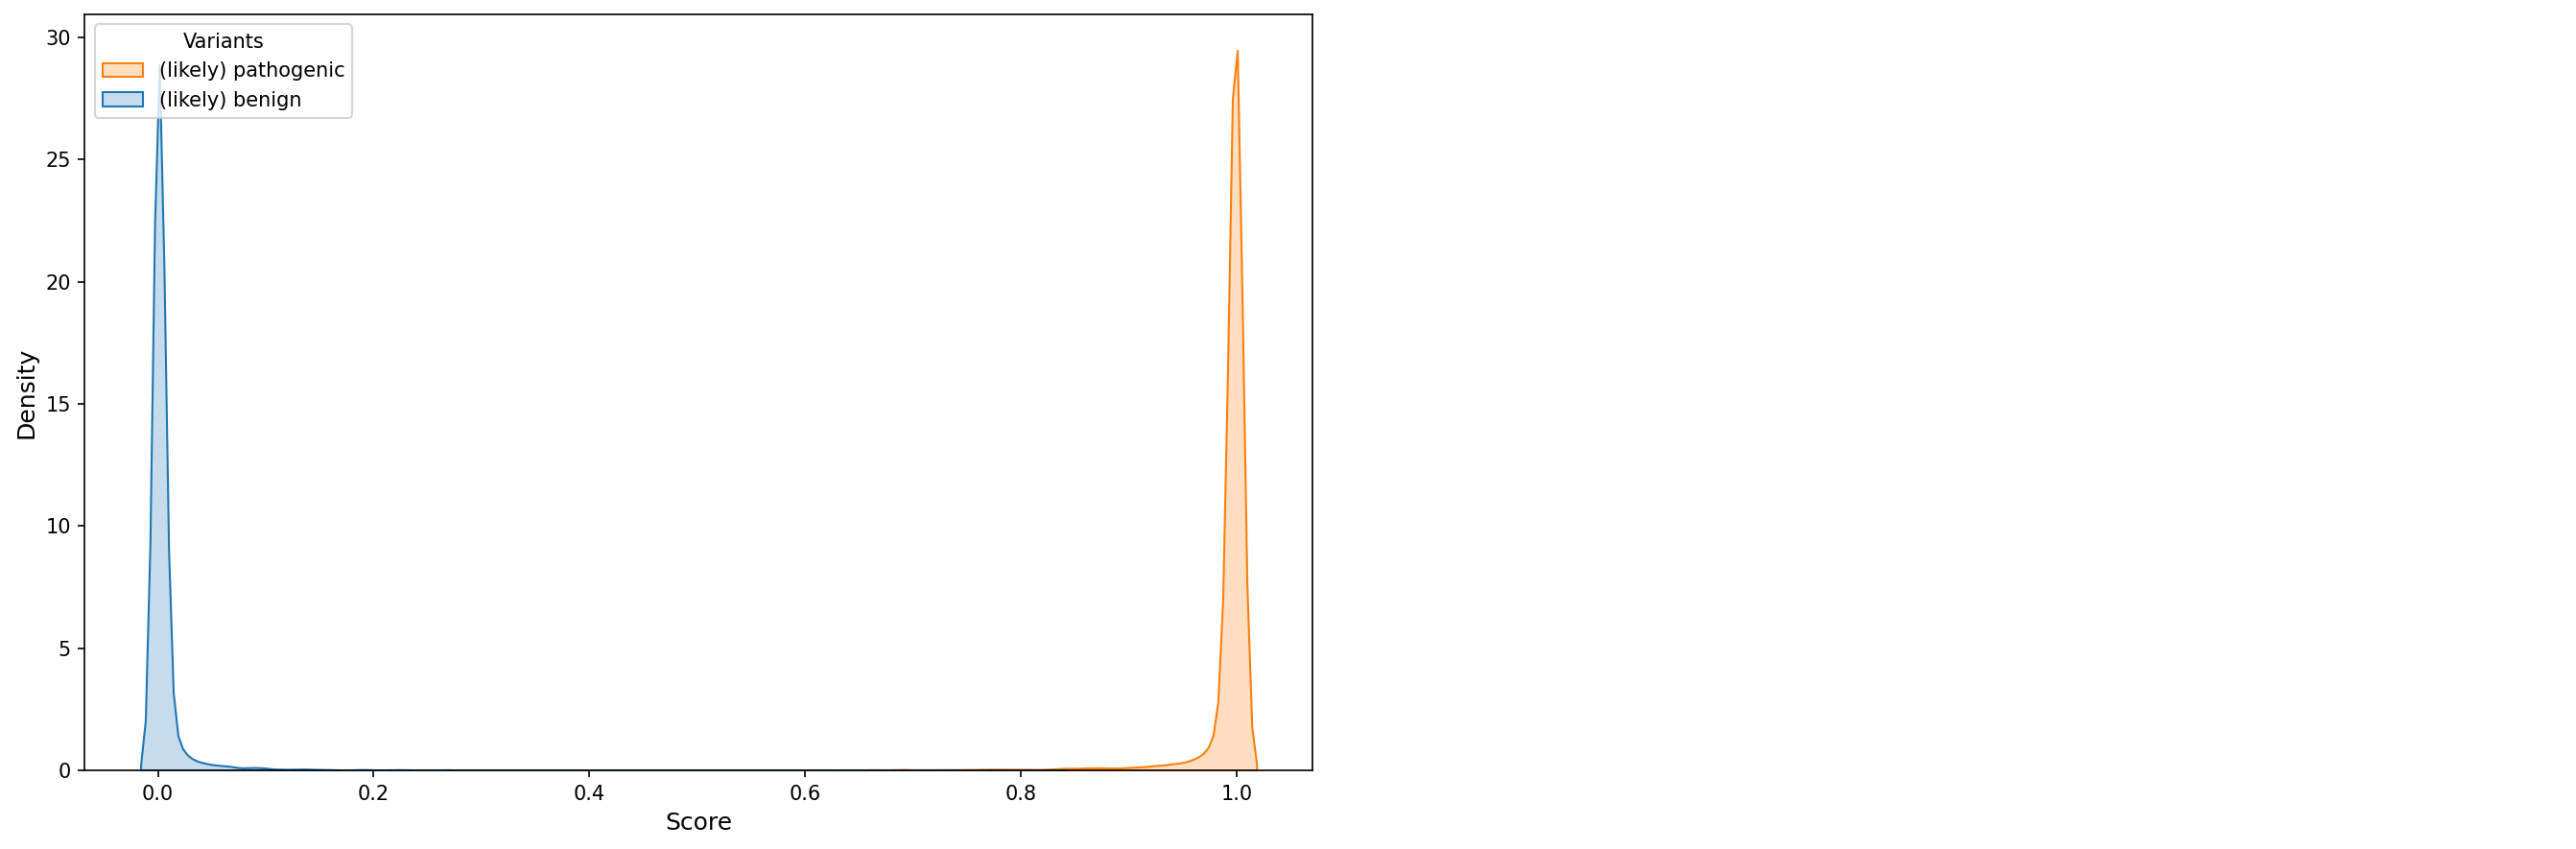

!!! save: test_default_xgb/clinvar.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 1 clinvar1 (35027, 34) (35027,) (21386,) (13641,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.3998,trialclinvar_and_0.0003_val_roc_10_0.4247,trialclinvar_and_0.0003_val_roc_10_0.4424
thres,0.5000,0.3998,0.4247,0.4424
Accuracy,0.9982,0.9985,0.9986,0.9985
F1,0.9977,0.9981,0.9982,0.9981
MCC,0.9962,0.9969,0.9971,0.9968
Precision,0.9988,0.9977,0.9981,0.9981
Recall(=Sens),0.9966,0.9986,0.9983,0.9980
Specificity,0.9992,0.9985,0.9988,0.9988
AUC,1.0000,1.0000,1.0000,1.0000
AUCPR,1.0000,1.0000,1.0000,1.0000
G-mean,0.9979,0.9986,0.9985,0.9984


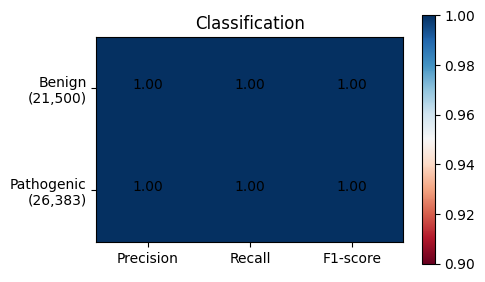

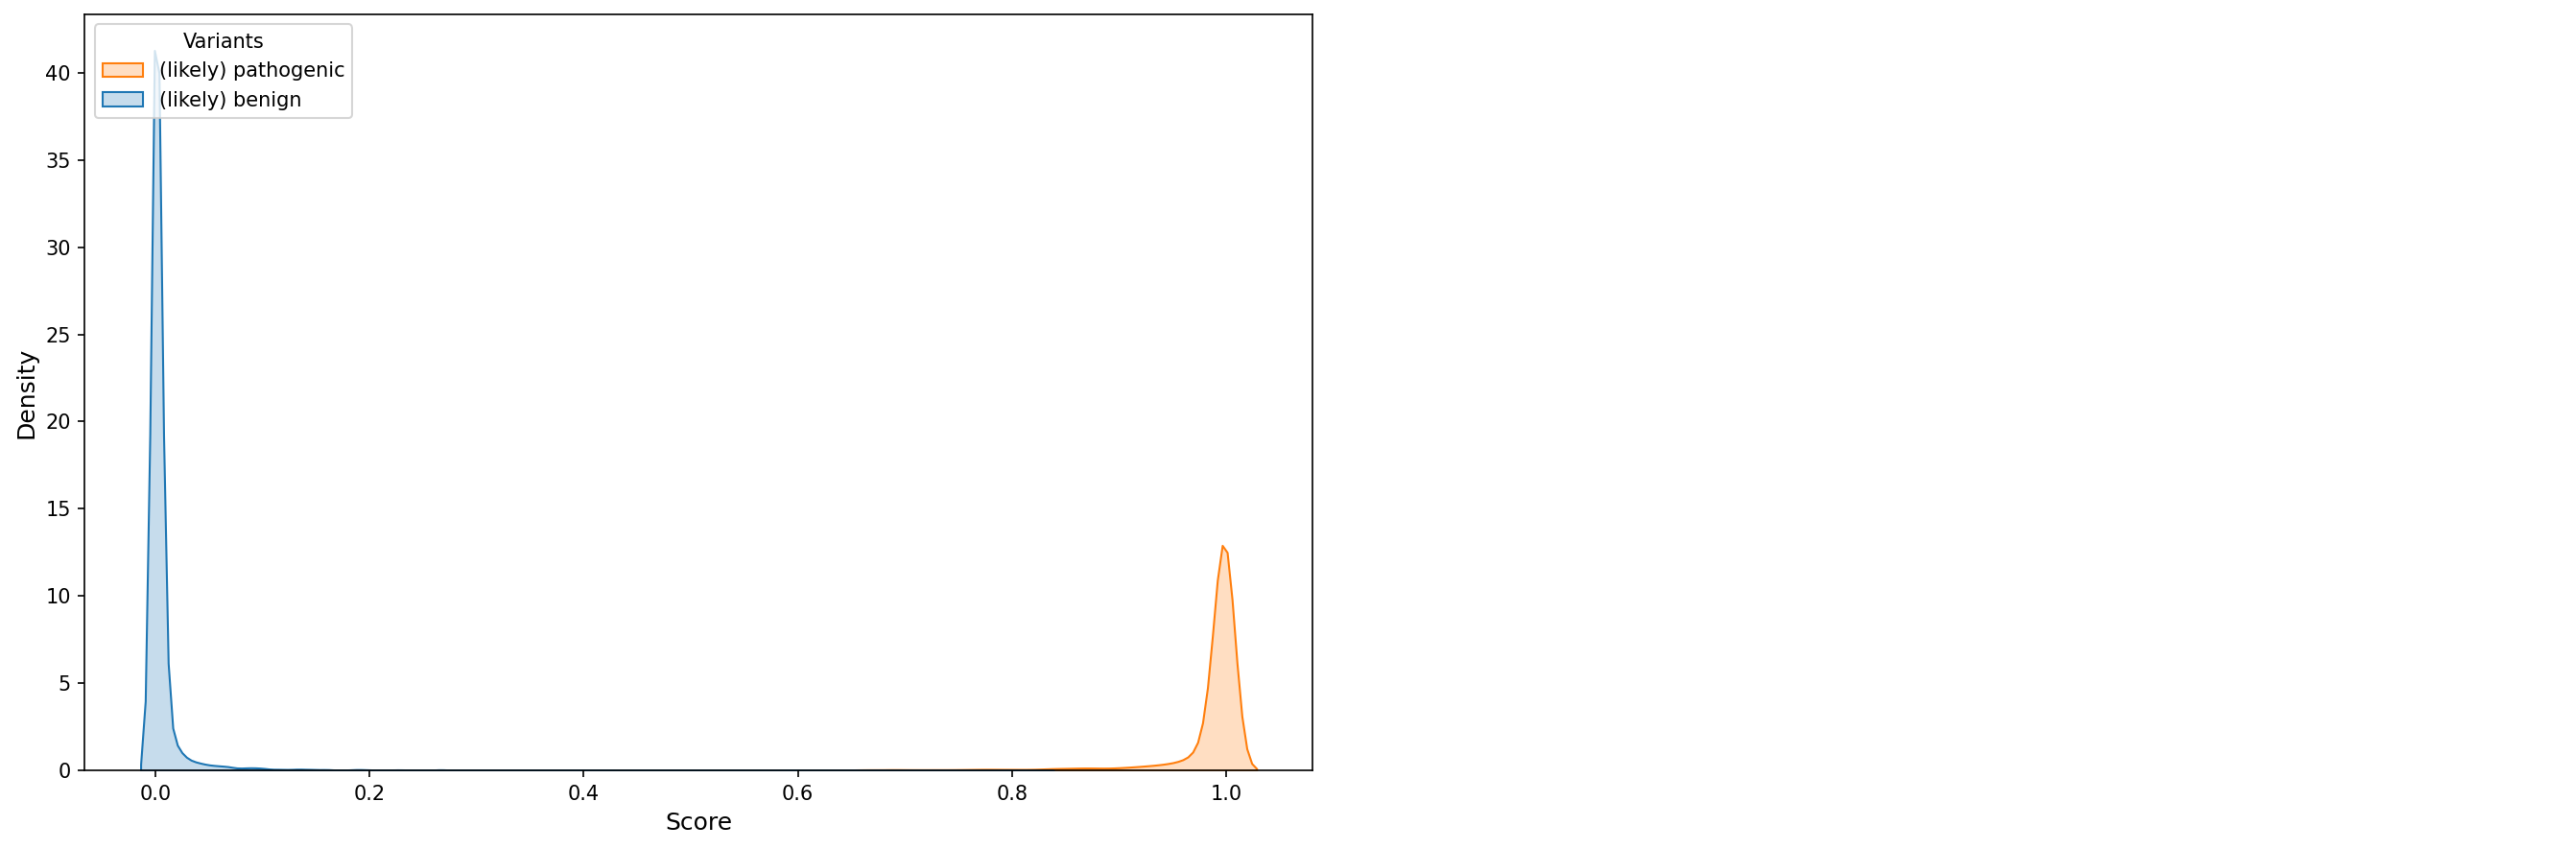

!!! save: test_default_xgb/clinvar1.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar1.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 2 clinvar_only_0.0003 (50883, 34) (50883,) (24500,) (26383,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.6105,trialclinvar_and_0.0003_val_roc_10_0.6474
thres,0.5000,0.6105,0.6474
Accuracy,0.9949,0.9954,0.9950
F1,0.9951,0.9956,0.9952
MCC,0.9899,0.9908,0.9900
Precision,0.9920,0.9947,0.9952
Recall(=Sens),0.9983,0.9965,0.9951
Specificity,0.9913,0.9943,0.9948
AUC,0.9997,0.9997,0.9997
AUCPR,0.9997,0.9997,0.9997
G-mean,0.9948,0.9954,0.9950


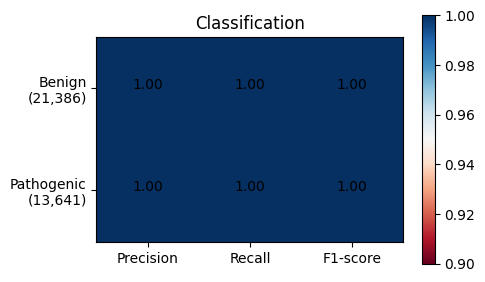

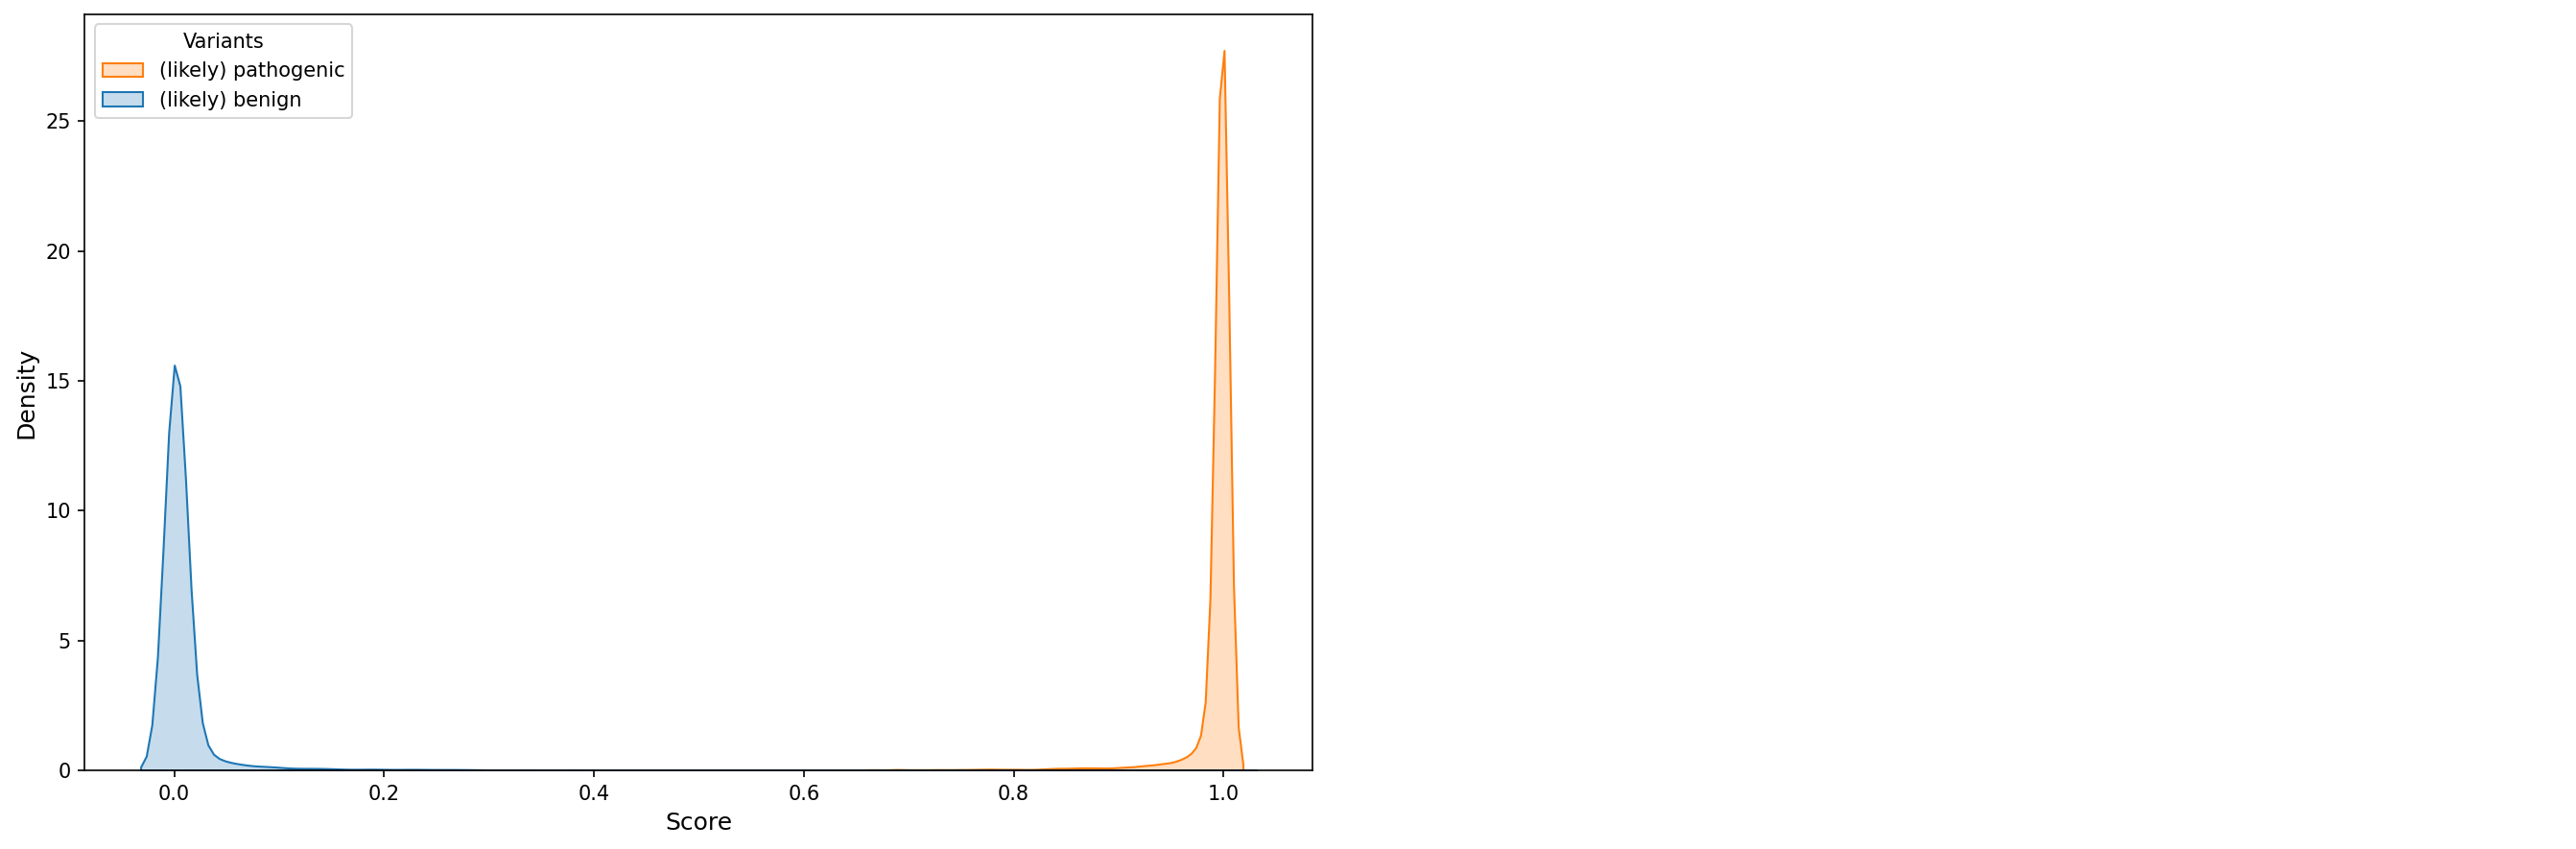

!!! save: test_default_xgb/clinvar_only_0.0003.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar_only_0.0003.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 3 clinvar_and_0.0003 (50883, 34) (50883,) (24500,) (26383,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.5293,trialclinvar_and_0.0003_val_roc_10_0.5118
thres,0.5000,0.5293,0.5118
Accuracy,0.9980,0.9981,0.9980
F1,0.9980,0.9982,0.9981
MCC,0.9959,0.9962,0.9960
Precision,0.9978,0.9984,0.9981
Recall(=Sens),0.9983,0.9979,0.9981
Specificity,0.9976,0.9983,0.9980
AUC,1.0000,1.0000,1.0000
AUCPR,1.0000,1.0000,1.0000
G-mean,0.9979,0.9981,0.9980


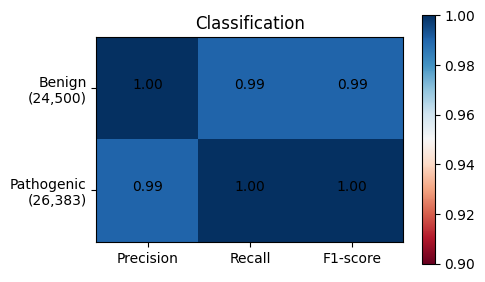

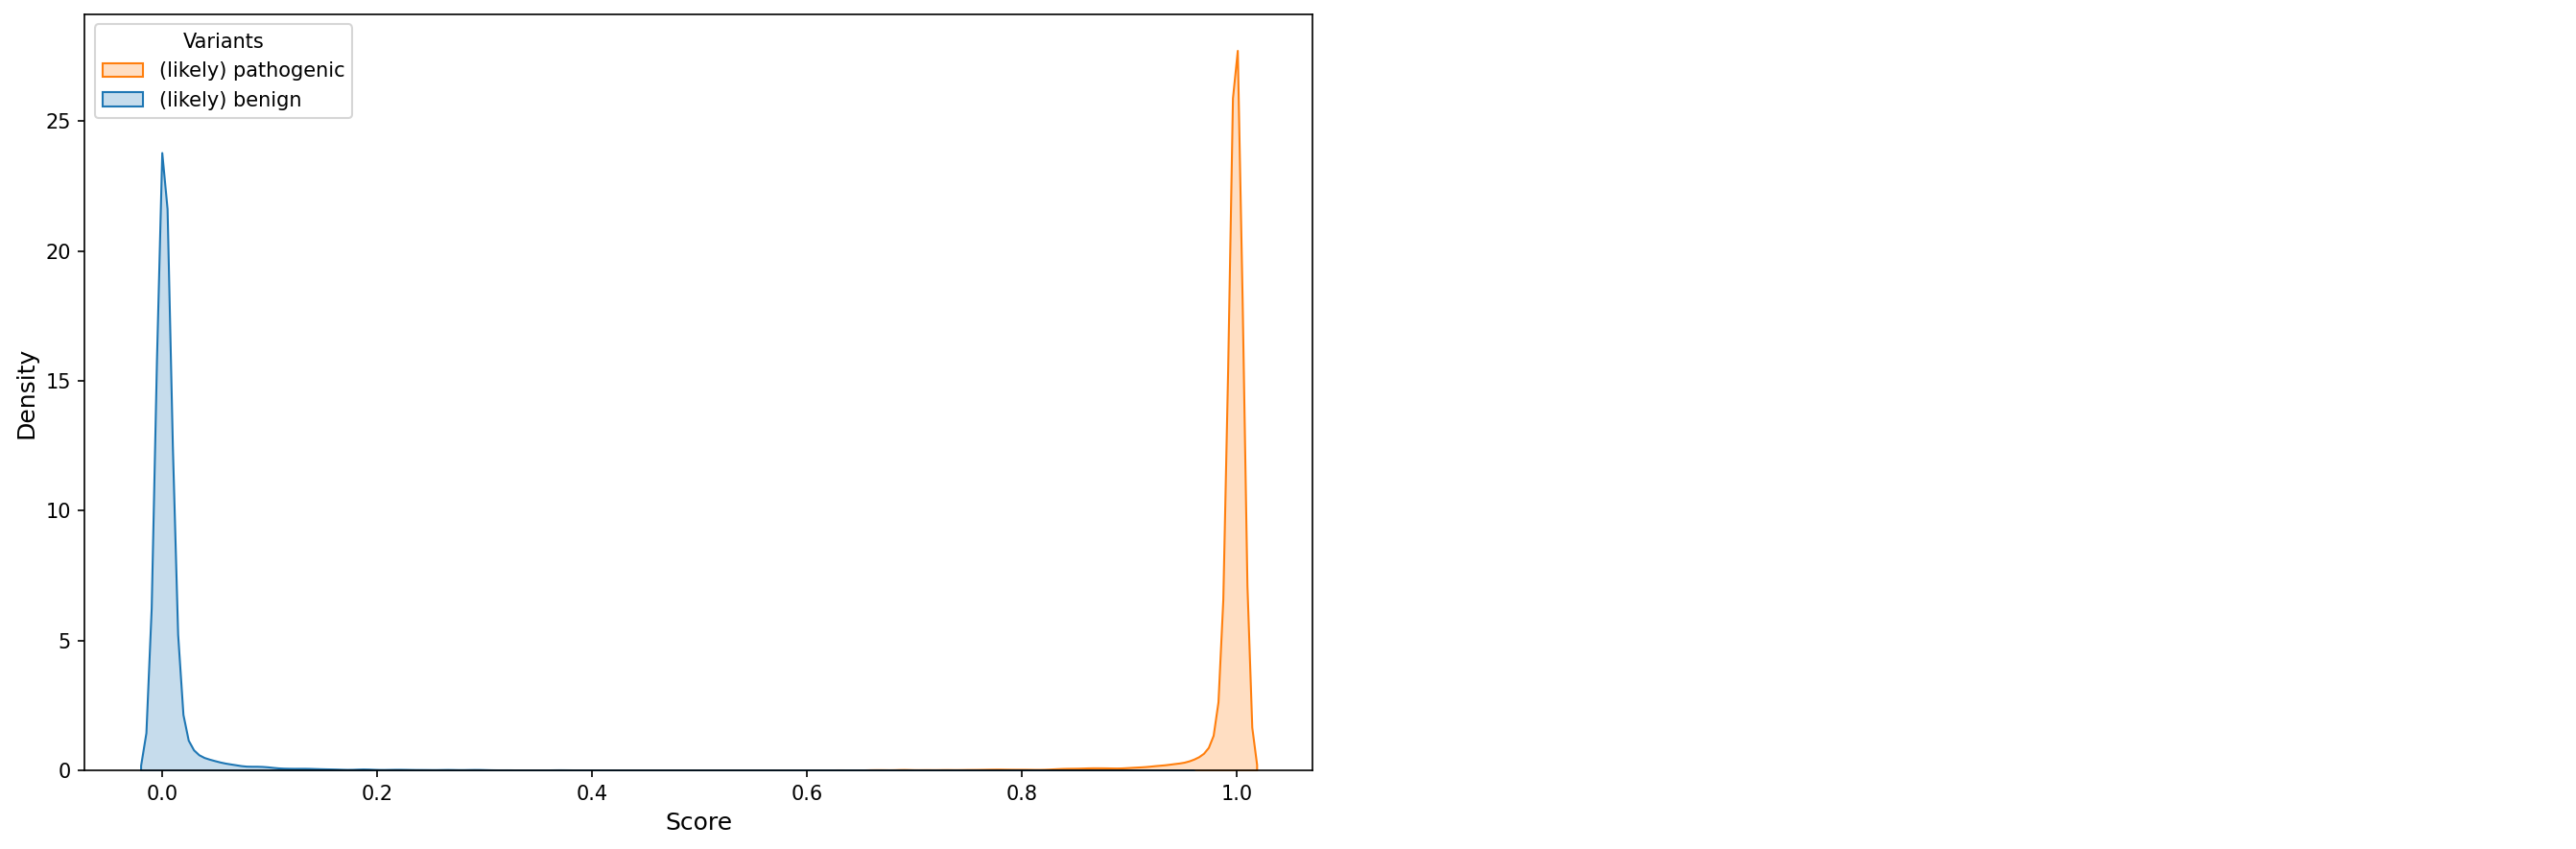

!!! save: test_default_xgb/clinvar_and_0.0003.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar_and_0.0003.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 4 clinvar1_only_0.0003 (38027, 34) (38027,) (24386,) (13641,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.4524,trialclinvar_and_0.0003_val_roc_10_0.6105,trialclinvar_and_0.0003_val_roc_10_0.6448
thres,0.5000,0.4524,0.6105,0.6448
Accuracy,0.9935,0.9933,0.9940,0.9934
F1,0.9910,0.9907,0.9917,0.9908
MCC,0.9860,0.9855,0.9870,0.9857
Precision,0.9855,0.9837,0.9901,0.9908
Recall(=Sens),0.9966,0.9978,0.9933,0.9908
Specificity,0.9918,0.9908,0.9945,0.9949
AUC,0.9996,0.9996,0.9996,0.9996
AUCPR,0.9991,0.9991,0.9991,0.9991
G-mean,0.9942,0.9943,0.9939,0.9928


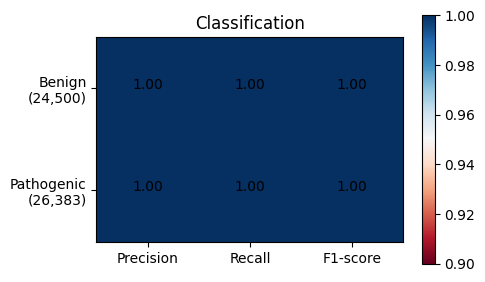

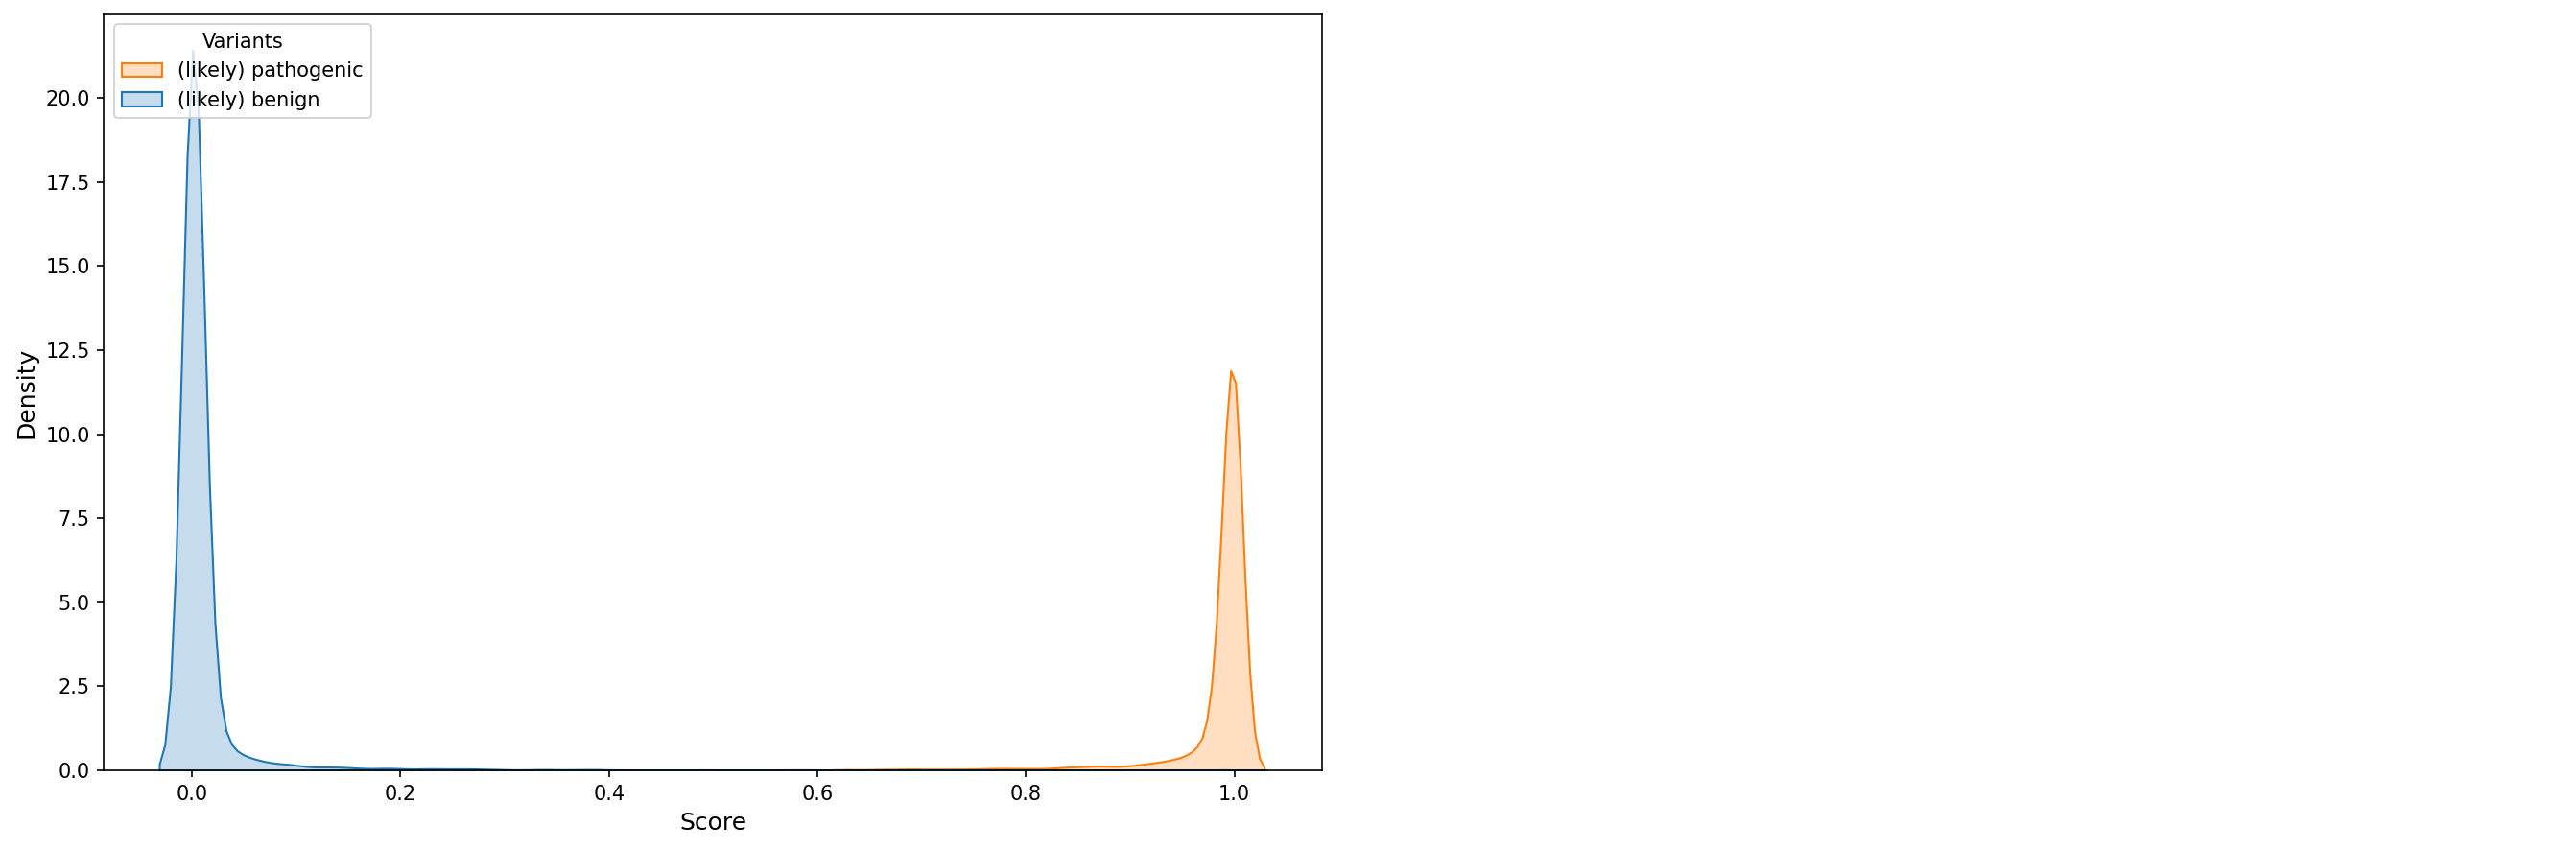

!!! save: test_default_xgb/clinvar1_only_0.0003.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar1_only_0.0003.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 5 clinvar1_and_0.0003 (38027, 34) (38027,) (24386,) (13641,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.4247,trialclinvar_and_0.0003_val_roc_10_0.5293,trialclinvar_and_0.0003_val_roc_10_0.5004
thres,0.5000,0.4247,0.5293,0.5004
Accuracy,0.9976,0.9976,0.9977,0.9976
F1,0.9966,0.9966,0.9968,0.9967
MCC,0.9947,0.9947,0.9951,0.9948
Precision,0.9966,0.9949,0.9977,0.9967
Recall(=Sens),0.9966,0.9983,0.9960,0.9966
Specificity,0.9981,0.9971,0.9987,0.9982
AUC,1.0000,1.0000,1.0000,1.0000
AUCPR,0.9999,0.9999,0.9999,0.9999
G-mean,0.9974,0.9977,0.9973,0.9974


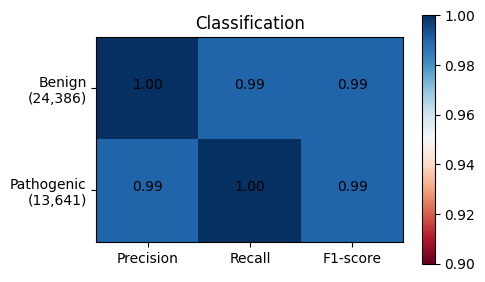

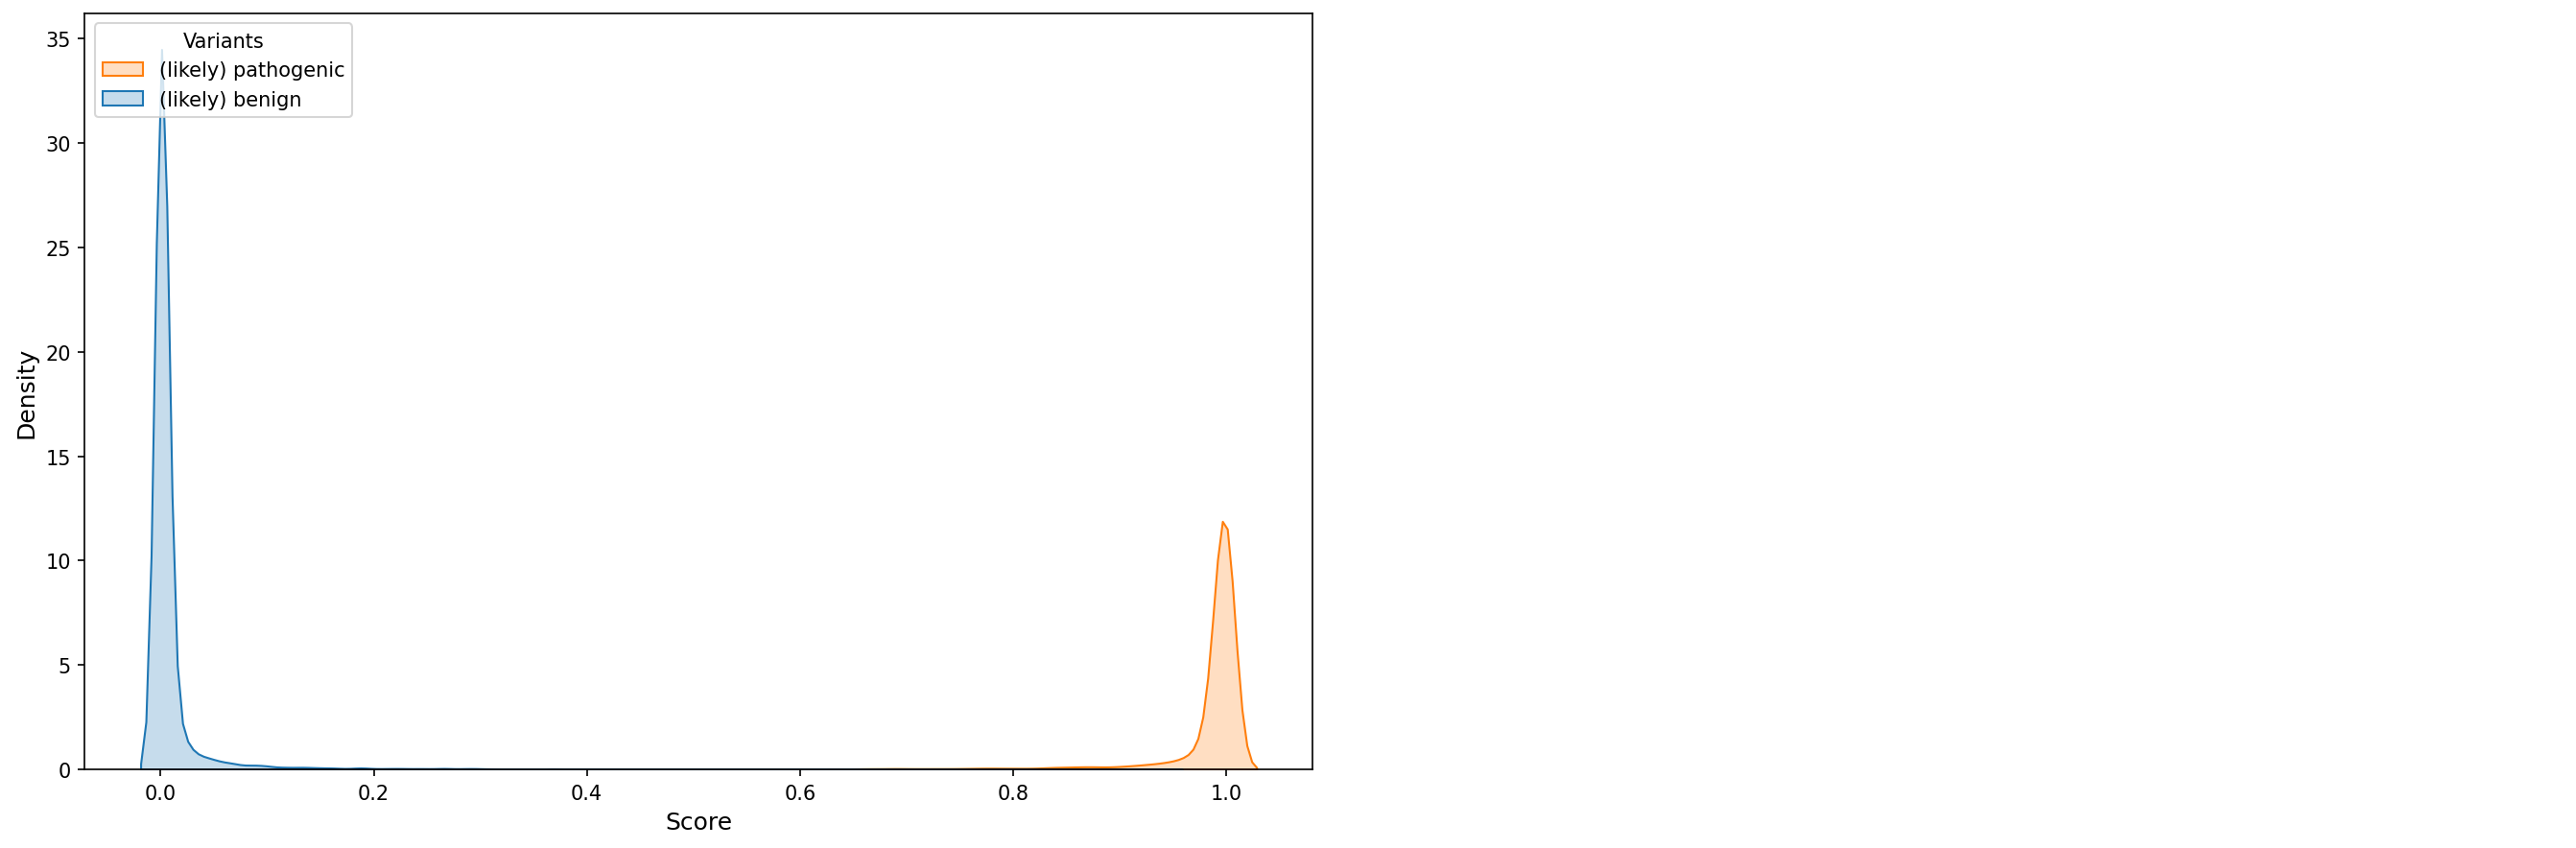

!!! save: test_default_xgb/clinvar1_and_0.0003.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar1_and_0.0003.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 6 clingen (521, 34) (521,) (121,) (400,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.7410
thres,0.5000,0.7410
Accuracy,0.9693,0.9712
F1,0.9801,0.9812
MCC,0.9129,0.9195
Precision,0.9729,0.9825
Recall(=Sens),0.9875,0.9800
Specificity,0.9091,0.9421
AUC,0.9888,0.9888
AUCPR,0.9964,0.9964
G-mean,0.9475,0.9609


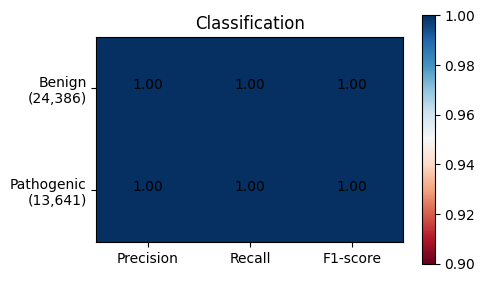

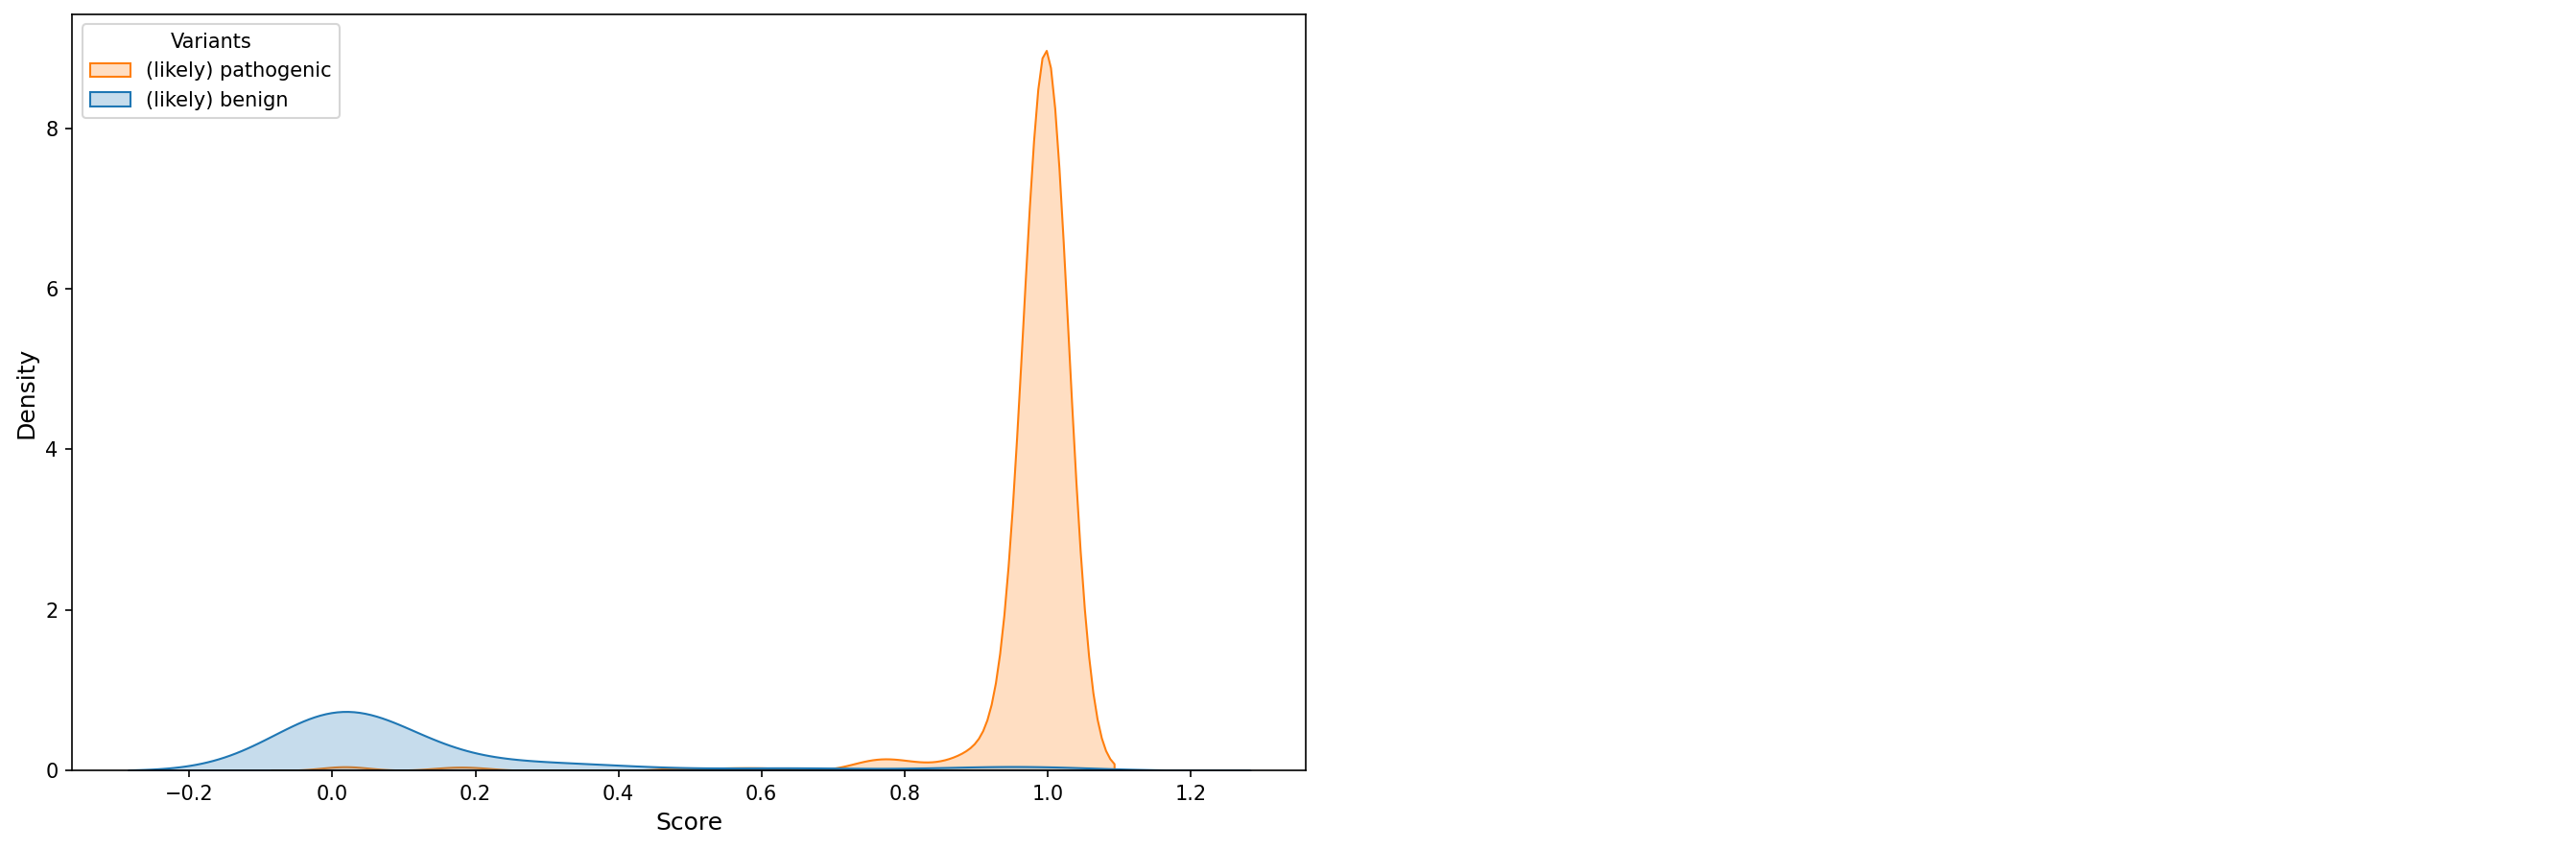

!!! save: test_default_xgb/clingen.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clingen.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 7 clingen_1 (505, 34) (505,) (115,) (390,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.7410
thres,0.5000,0.7410
Accuracy,0.9683,0.9703
F1,0.9796,0.9807
MCC,0.9088,0.9158
Precision,0.9722,0.9820
Recall(=Sens),0.9872,0.9795
Specificity,0.9043,0.9391
AUC,0.9883,0.9883
AUCPR,0.9964,0.9964
G-mean,0.9449,0.9591


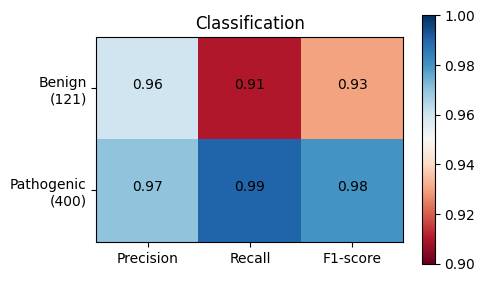

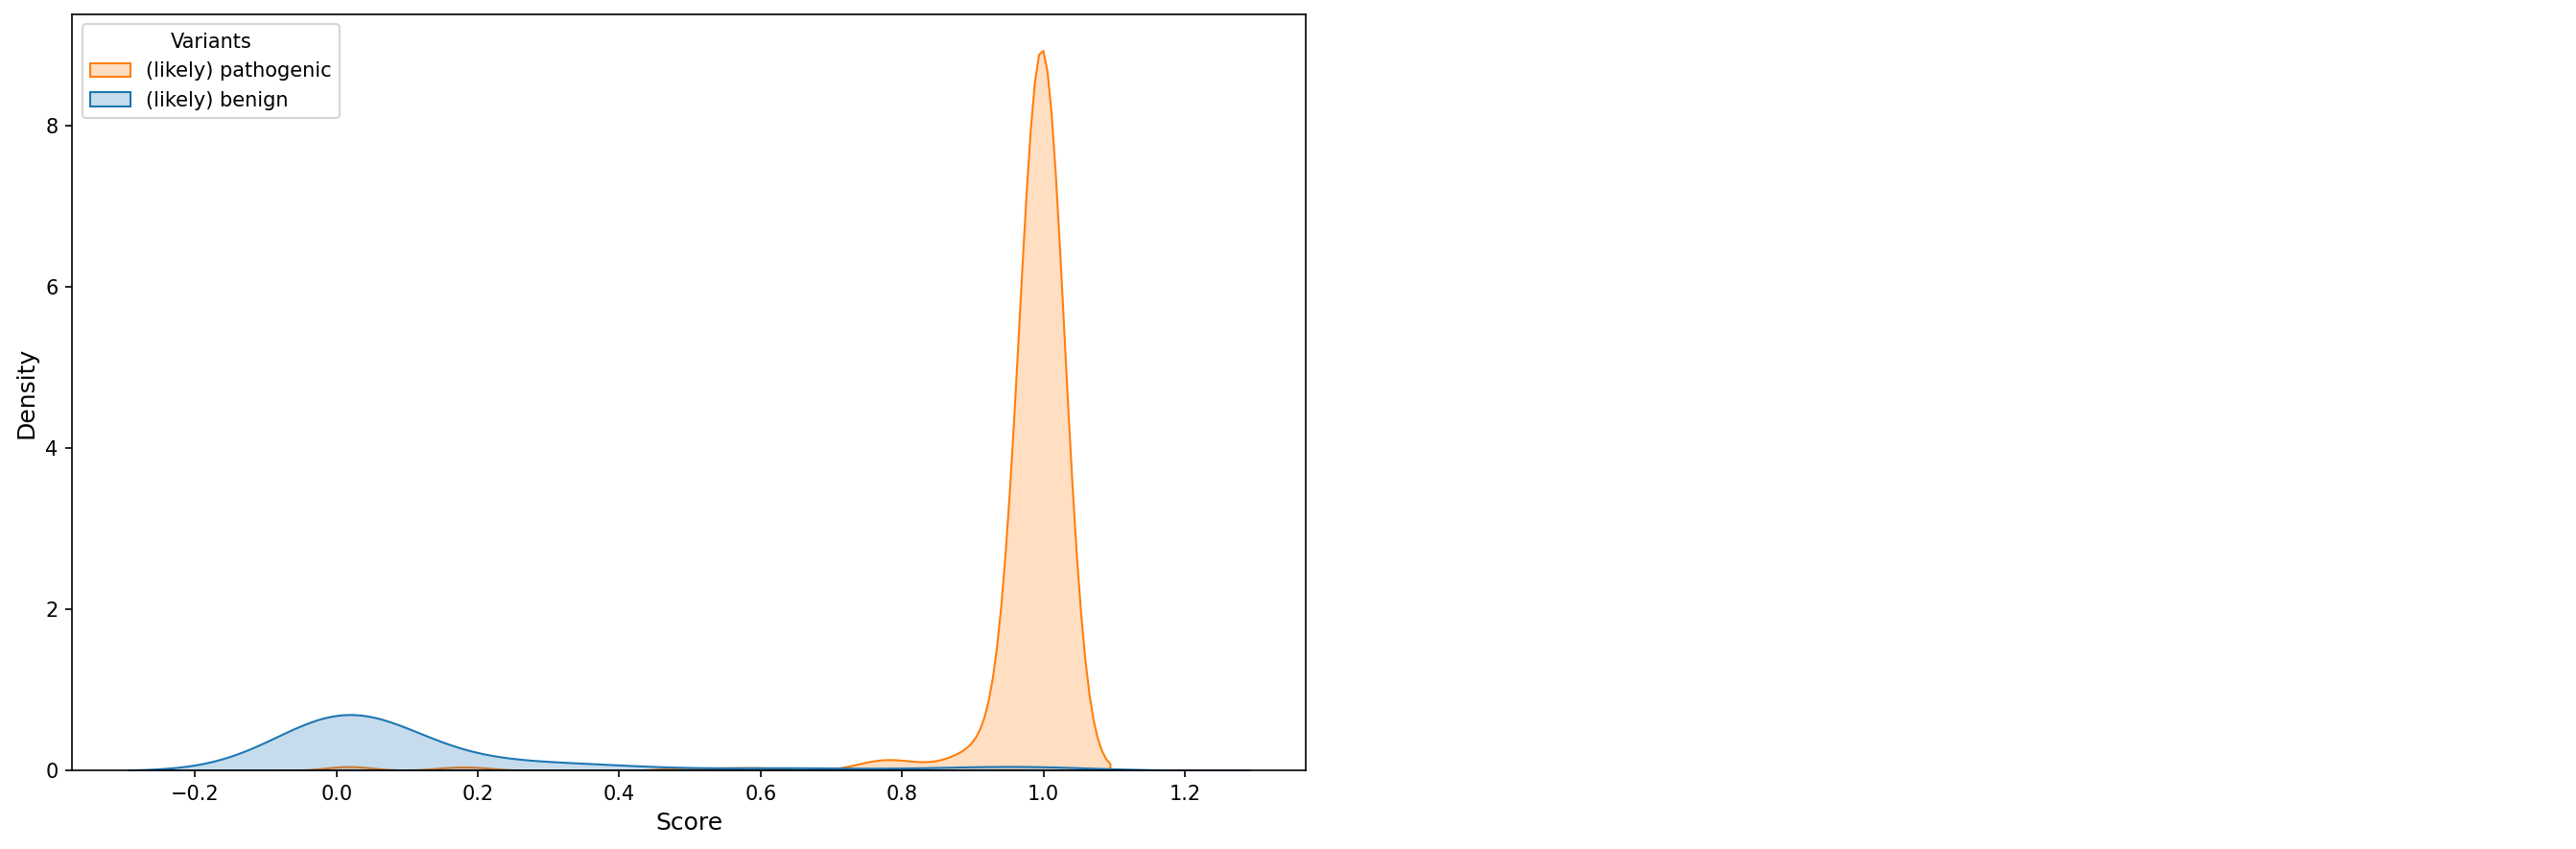

!!! save: test_default_xgb/clingen_1.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clingen_1.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 8 uniprot (32852, 34) (32852,) (23560,) (9292,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.7836,trialclinvar_and_0.0003_val_roc_10_0.9372,trialclinvar_and_0.0003_val_roc_10_0.9864
thres,0.5000,0.7836,0.9372,0.9864
Accuracy,0.8651,0.8784,0.8892,0.8866
F1,0.8013,0.8140,0.8210,0.7995
MCC,0.7263,0.7408,0.7474,0.7205
Precision,0.6866,0.7175,0.7561,0.7996
Recall(=Sens),0.9619,0.9406,0.8981,0.7995
Specificity,0.8269,0.8539,0.8857,0.9210
AUC,0.9487,0.9487,0.9487,0.9487
AUCPR,0.8362,0.8362,0.8362,0.8362
G-mean,0.8918,0.8962,0.8919,0.8581


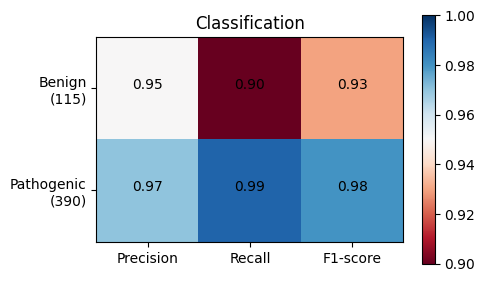

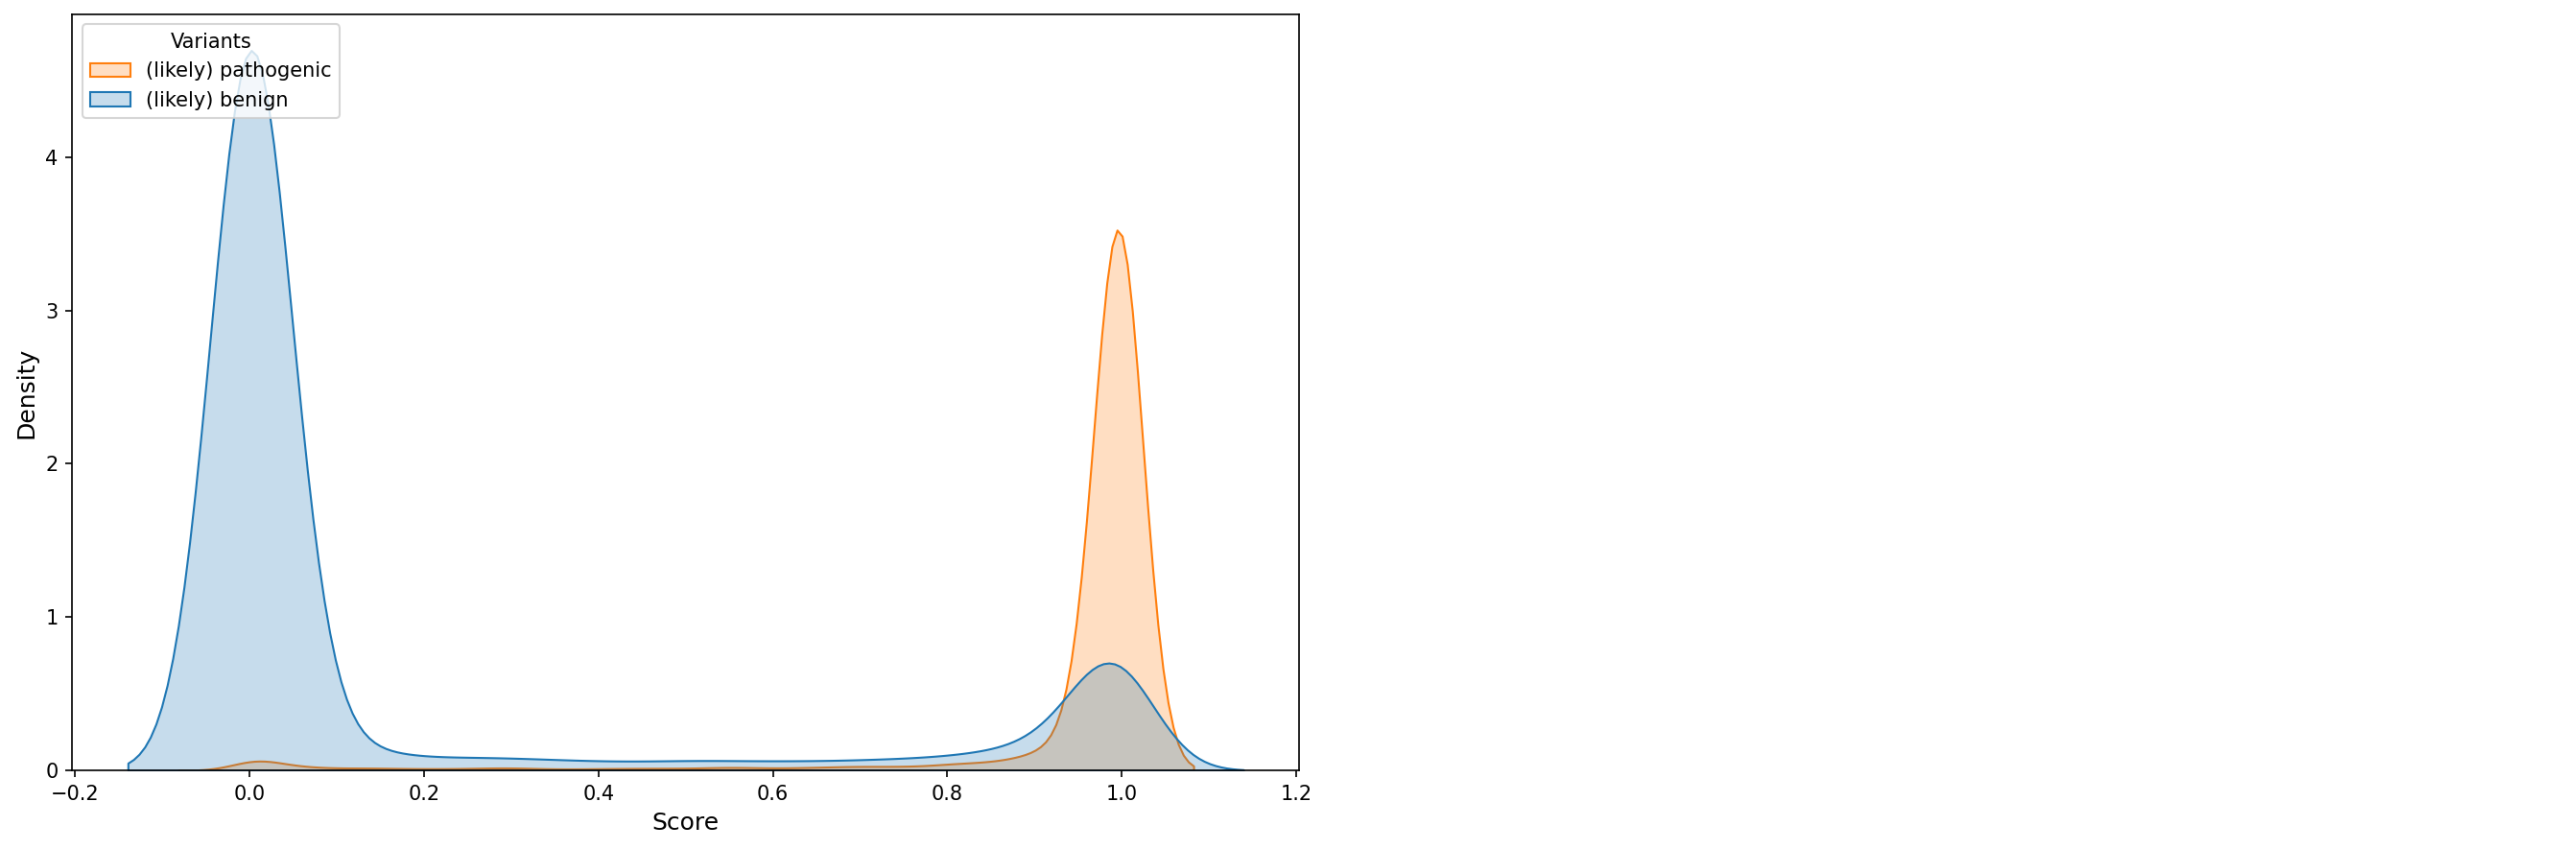

!!! save: test_default_xgb/uniprot.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/uniprot.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 9 uniprot_1 (10852, 34) (10852,) (4012,) (6840,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.2560,trialclinvar_and_0.0003_val_roc_10_0.1141,trialclinvar_and_0.0003_val_roc_10_0.1932
thres,0.5000,0.2560,0.1141,0.1932
Accuracy,0.9815,0.9853,0.9854,0.9853
F1,0.9852,0.9884,0.9885,0.9884
MCC,0.9606,0.9686,0.9687,0.9686
Precision,0.9923,0.9897,0.9862,0.9884
Recall(=Sens),0.9782,0.9870,0.9908,0.9883
Specificity,0.9870,0.9826,0.9763,0.9803
AUC,0.9960,0.9960,0.9960,0.9960
AUCPR,0.9960,0.9960,0.9960,0.9960
G-mean,0.9826,0.9848,0.9835,0.9843


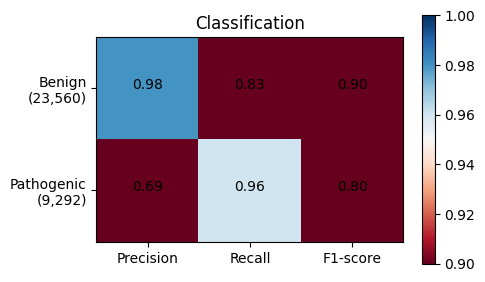

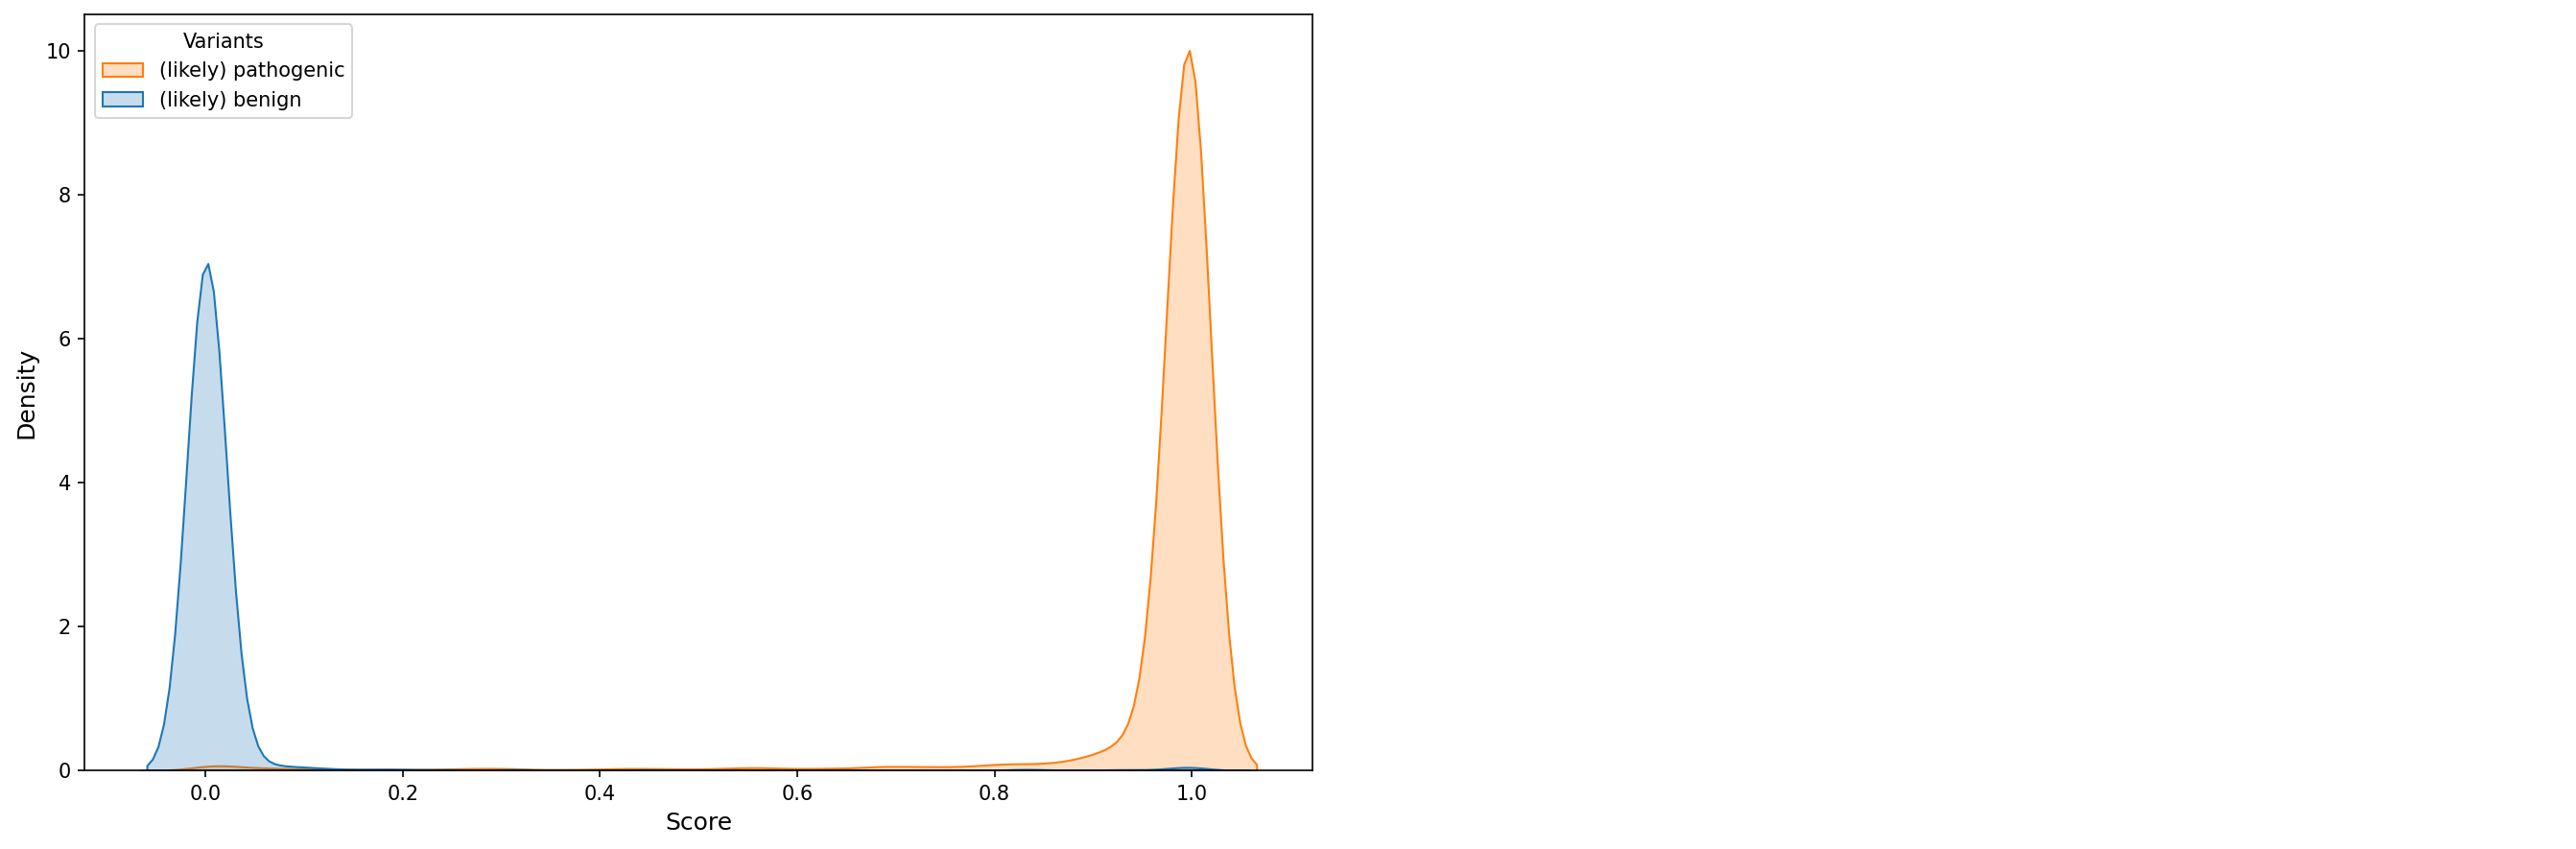

!!! save: test_default_xgb/uniprot_1.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/uniprot_1.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 10 clinvar2 (4920, 34) (4920,) (2079,) (2841,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.7186,trialclinvar_and_0.0003_val_roc_10_0.4104
thres,0.5000,0.7186,0.4104
Accuracy,0.9913,0.9913,0.9904
F1,0.9924,0.9924,0.9917
MCC,0.9821,0.9822,0.9804
Precision,0.9940,0.9965,0.9919
Recall(=Sens),0.9908,0.9884,0.9916
Specificity,0.9918,0.9952,0.9889
AUC,0.9994,0.9994,0.9994
AUCPR,0.9996,0.9996,0.9996
G-mean,0.9913,0.9918,0.9902


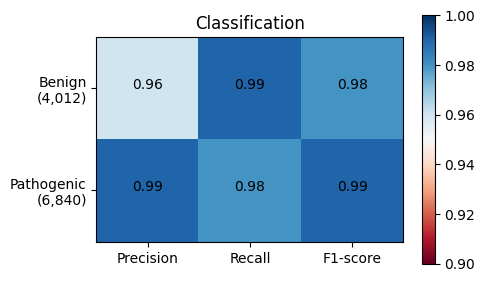

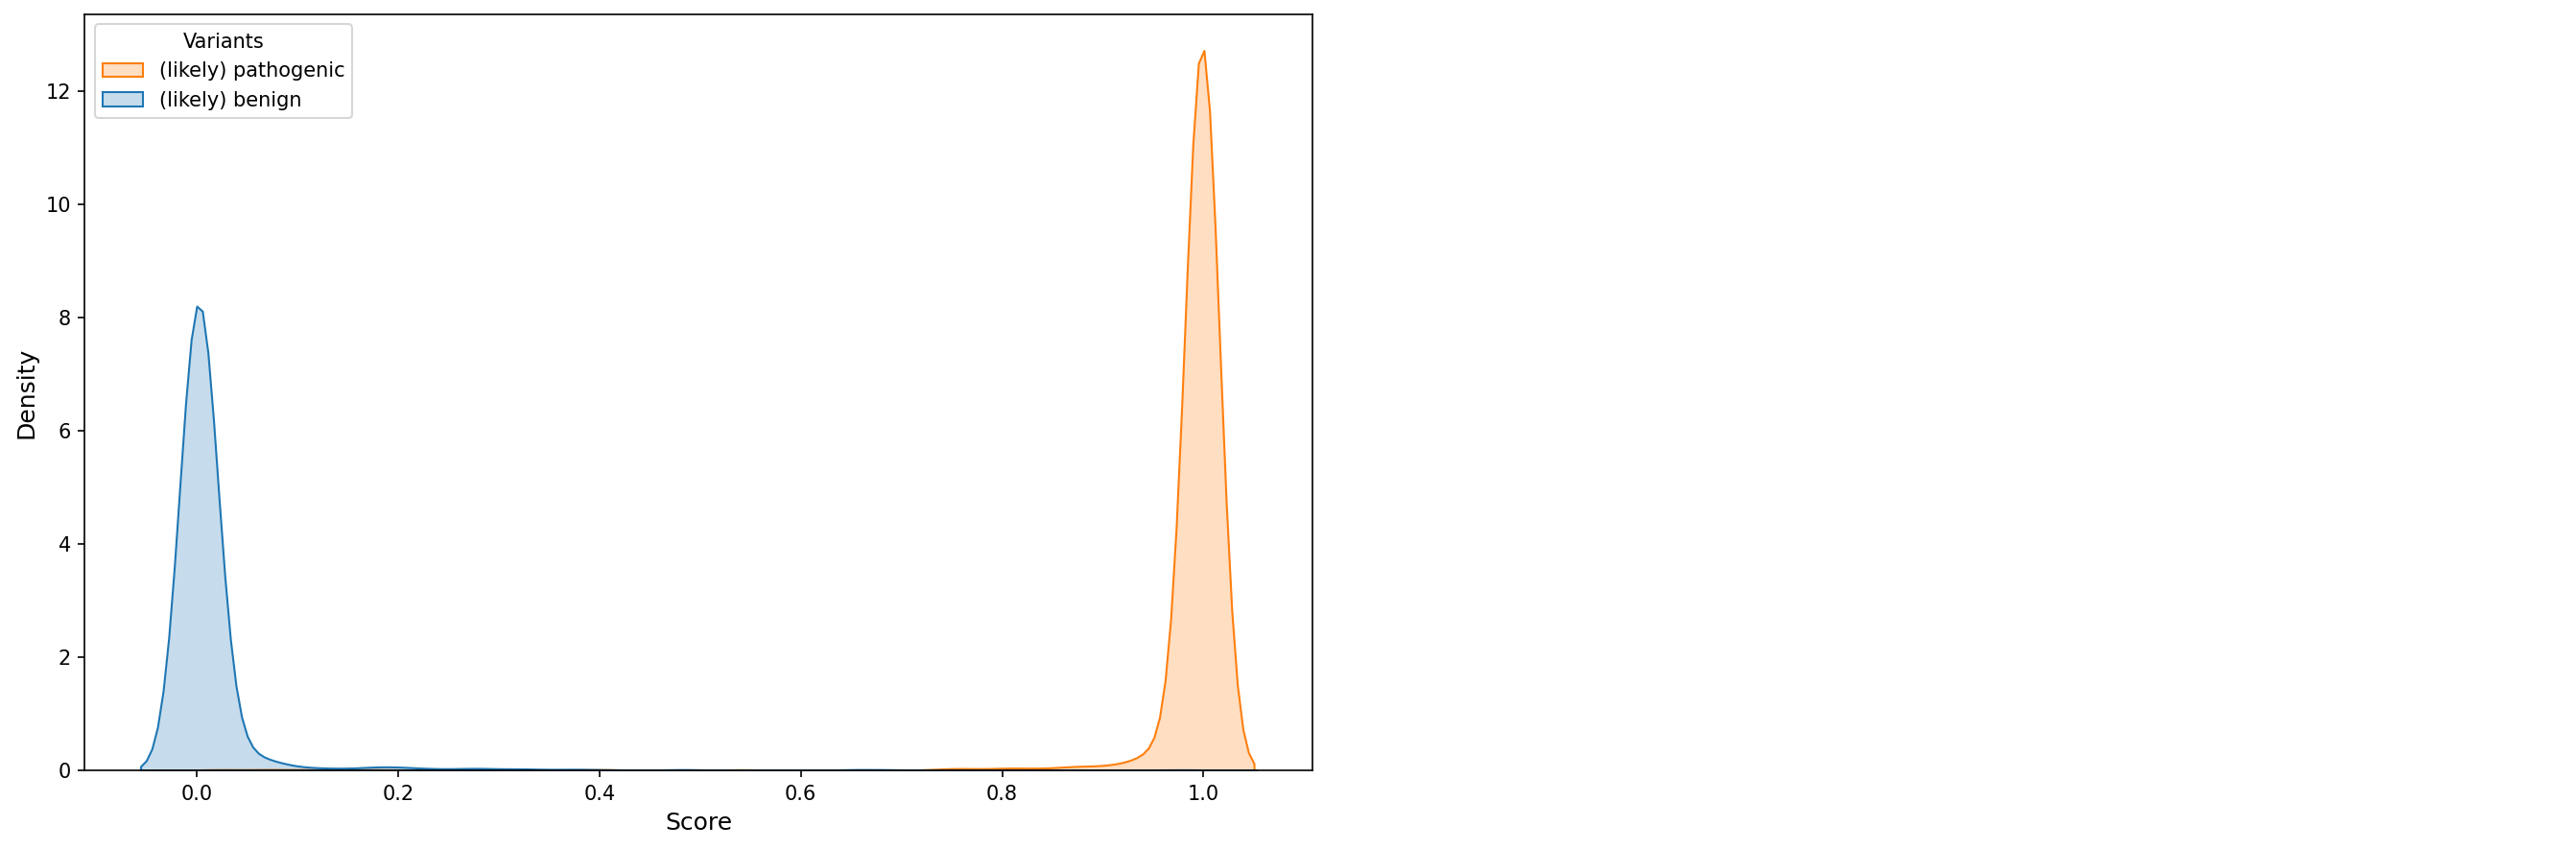

!!! save: test_default_xgb/clinvar2.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar2.xgb.clinvar_and_0.0003.predict.eval.csv
xgb 11 clinvar2_1 (4804, 34) (4804,) (2019,) (2785,)
val


,trialclinvar_and_0.0003_val_roc_10_0.5000,trialclinvar_and_0.0003_val_roc_10_0.7341,trialclinvar_and_0.0003_val_roc_10_0.4250
thres,0.5000,0.7341,0.4250
Accuracy,0.9917,0.9917,0.9915
F1,0.9928,0.9928,0.9926
MCC,0.9829,0.9830,0.9825
Precision,0.9939,0.9964,0.9928
Recall(=Sens),0.9917,0.9892,0.9925
Specificity,0.9916,0.9950,0.9901
AUC,0.9995,0.9995,0.9995
AUCPR,0.9997,0.9997,0.9997
G-mean,0.9917,0.9921,0.9913


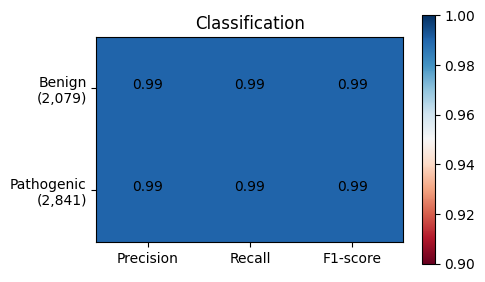

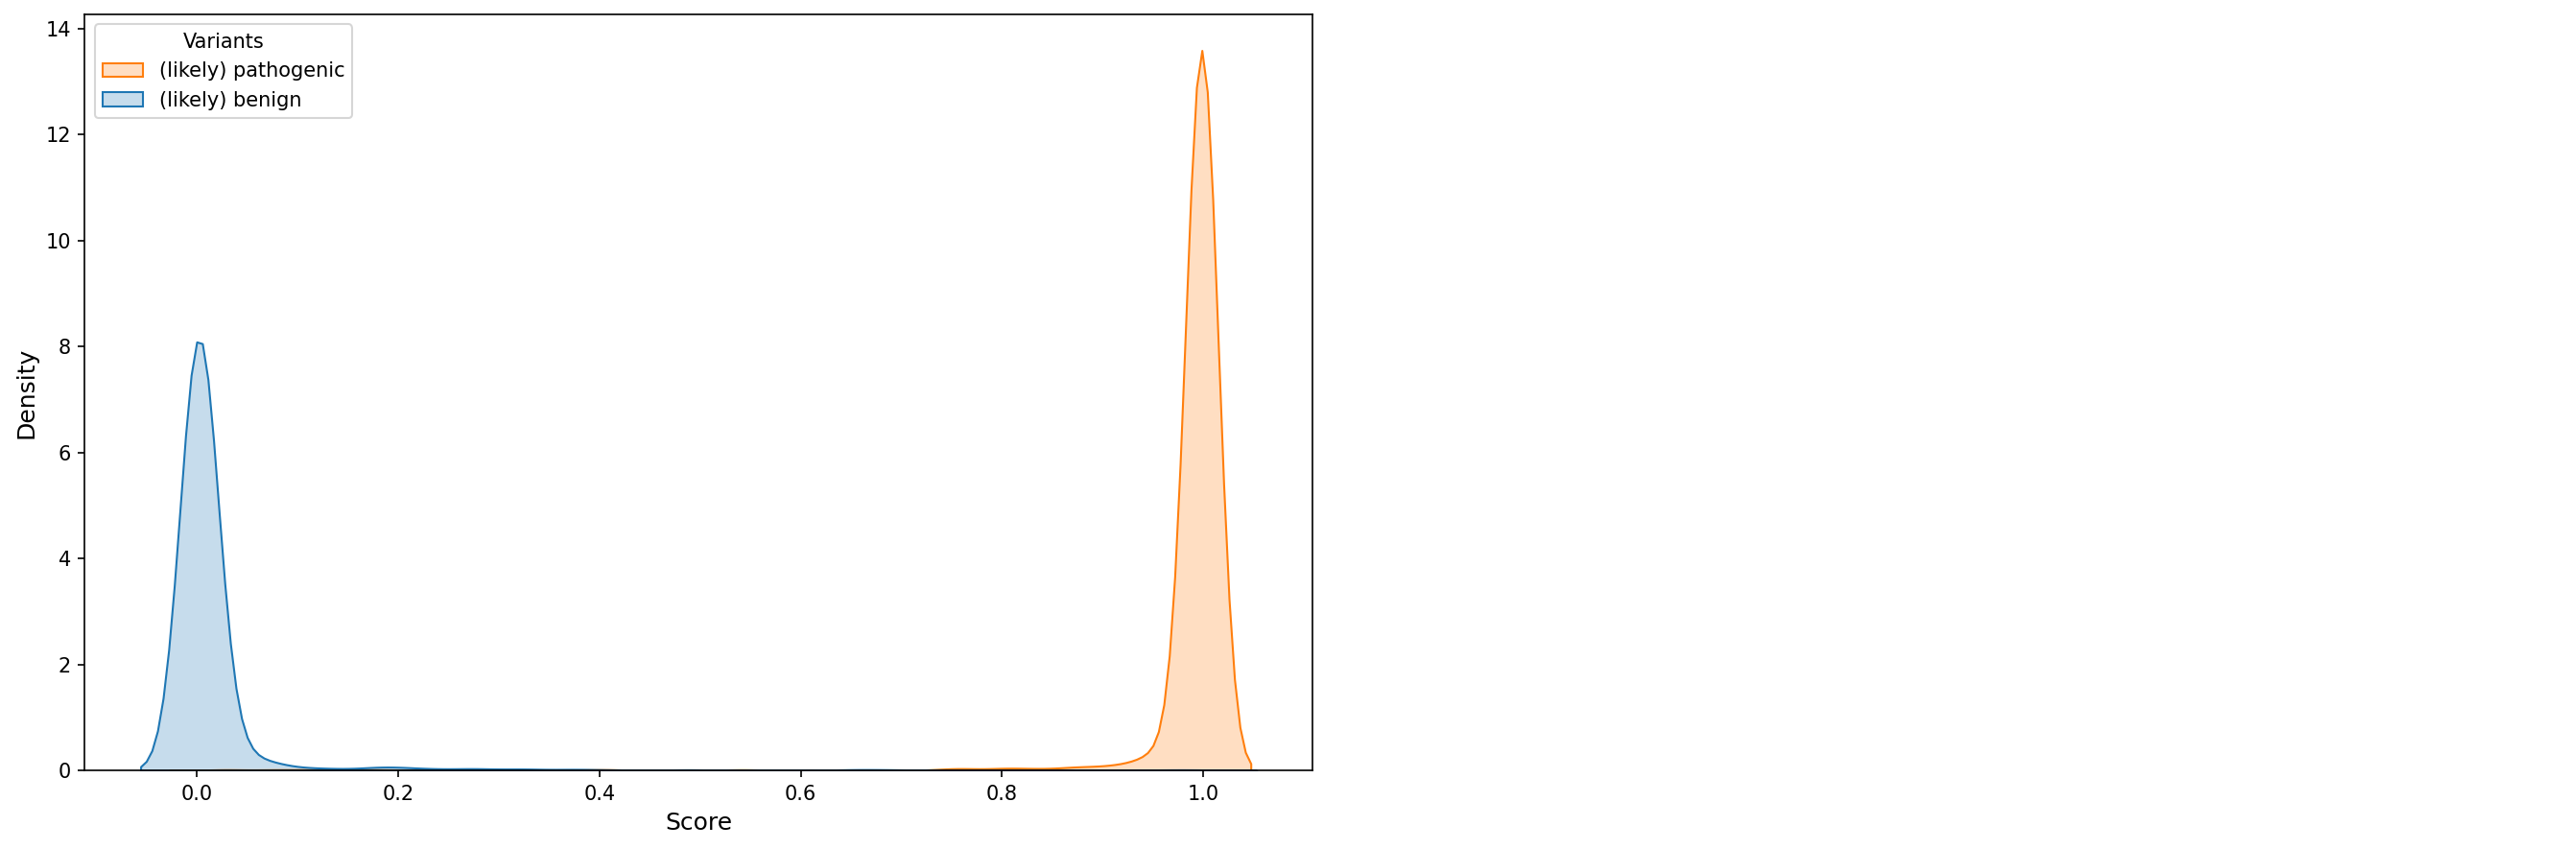

!!! save: test_default_xgb/clinvar2_1.xgb.clinvar_and_0.0003.predict.oob.csv
!!! save: test_default_xgb/clinvar2_1.xgb.clinvar_and_0.0003.predict.eval.csv


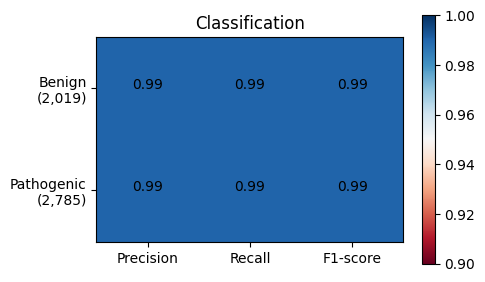

In [ ]:
_set = list(_df.keys())
_set = ['clinvar', 'clingen', 'uniprot', 'clinvar2']
for i, _name in enumerate(_set):
    if _df[_name] is None:
        continue
    _x = test_X[_name]
    _y = test_y[_name]
    print(ml_name, i, _name, _x.shape, _y.shape, _y[_y==0].shape, _y[_y==1].shape)
    set_test = ''
    if ml_name == 'xgb':
        set_test = xgb.DMatrix(_x)
    elif ml_name == 'lgb':
        set_test = _x
    elif ml_name == 'cat':
        set_test = Pool(_x)

    y_pred= multi_model._pred_models(type_pred = 'val', set_pred = set_test, y_real = _y, show_df=True)

    _oob = pd.DataFrame(index=_y.index)
    _oob = test_head[_name]
    _oob.loc[_y.index, 'y'] = _y
    _oob['y'] = _oob['y'].astype(int).astype('category')
    _oob.loc[_y.index, 'y_pred'] = y_pred

    plot_score_dist(_oob)

    binarizer = Binarizer(threshold = 0.5)
    binarizer.fit(y_pred.reshape(-1,1))
    thres_pred = binarizer.transform(y_pred.reshape(-1,1))

    plot_classification_report(_oob)

    save_csv = f'{fold_name}/{_name}.{ml_name}.{_trial_num}.predict.oob.csv'
    print("!!! save:", save_csv)
    _oob.to_csv(save_csv, sep="\t", index=False)

    save_csv = f'{fold_name}/{_name}.{ml_name}.{_trial_num}.predict.eval.csv'
    print("!!! save:", save_csv)
    multi_model.result.T.to_csv(save_csv, sep="\t", index=True)


#==============================================================

# Class : optuna
* https://colab.research.google.com/drive/1ssjXp74bJ8bCAbvXFOC4EIycBto_ONp_?usp=sharing#scrollTo=_ERqghqjEYZT

# tabnet parameter
* https://www.kaggle.com/code/enigmak/tabnet-deep-neural-network-for-tabular-data

In [ ]:
class Objective:
    def __init__(self, ml_name, split_n, split_t, fold_name):
        self.best_booster = None
        self._booster = None
        self.ml_name = ml_name
        self.split_n = split_n
        self.split_t = split_t
        self.fold_name = fold_name
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'

    def __call__(self, trial):
        print(f'{bgy}{mgt}{"=" * 100}{res}')
        pruning_callback = ''
        params = {}
        if self.ml_name == 'xgb':
            params = {'booster': 'gbtree', 'verbosity': 1,
              'objective':'binary:logistic','device': self.device,
              'random_state': 42,
              'eval_metric' : ['auc','aucpr','pre', 'error', 'logloss'],
              #'colsample_bytree' : trial.suggest_float("colsample_bytree", 0.5, 1.0, log=True), #0<~<=1
              'n_estimators': trial.suggest_int("n_estimators", 50, 1000),
              "eta" : trial.suggest_float("eta", 1e-3, 0.5, log=True), #0~1 / learning_rate
              "gamma" : trial.suggest_float("gamma", 0, 1), #0~ / min_split_loss
              "max_depth" : trial.suggest_int("max_depth", 5, 10), #0~
              #"min_child_weight" : trial.suggest_int("min_child_weight", 0.1, 10, step=0.1), #0~
              #"subsample": trial.suggest_float("subsample", 0.5, 1.0, step=0.005), #0<~<=1
              "lambda": trial.suggest_float("lambda", 0, 1.0), #0<=
              "alpha": trial.suggest_float("alpha", 0, 1.0),#0<=
            }
            lr = params["eta"]
            pruning_callback = optuna.integration.XGBoostPruningCallback(trial, 'val-auc')

        if self.ml_name == 'lgb':
            params = {"objective": "binary",'boosting_type': 'gbdt', "seed": 42,
                      'metric': ['auc','average_precision', 'binary_error', 'binary_logloss'],'verbosity' : -1,
                    'num_iterations': trial.suggest_int("num_iterations", 50, 1000), #0~ / num_boost_round
                    "learning_rate" : trial.suggest_float('learning_rate', 1e-3, 0.5, log=True), #0~ / eta
                    "max_depth" : trial.suggest_int("max_depth", 5, 10), #no limit / 0~
                    #"min_sum_hessian_in_leaf" : trial.suggest_int("min_sum_hessian_in_leaf", 0.1, 10), #0~ / min_child_weight
                    #"bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1, step=0.005), #0<~<=1 / subsample
                    'lambda_l1':trial.suggest_float('lambda_l1', 0, 1.0 ),  #0<= / reg_alpha
                    'lambda_l2':trial.suggest_float('lambda_l2', 0, 1.0 ),  #0<= / lambda
                    #'min_split_gain' : trial.suggest_float('min_split_gain', 0, 1), #0~ / gamma
                    #'feature_fraction':trial.suggest_float("feature_fraction", 0.5, 1.0, step=0.005), #0<,<=1 / colsample_bytree
                    #"num_leaves": trial.suggest_int("num_leaves", 2, 256),
                    #"bagging_freq": trial.suggest_int("bagging_freq", 1, 7),
                    #"min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
                      }

            lr = params["learning_rate"]
            pruning_callback = optuna.integration.LightGBMPruningCallback(trial, "auc", valid_name='val',)

        if self.ml_name == 'cat':
            params = {'eval_metric' : 'AUC', 'random_seed':42,
                      "objective": 'Logloss', "bootstrap_type":"Bayesian",#"boosting_type":"Ordered",
                    'iterations': trial.suggest_int('iterations', 50, 1000),
                    'learning_rate' : trial.suggest_float('learning_rate', 1e-3, 0.5, log=True),
                    'l2_leaf_reg':trial.suggest_float('l2_leaf_reg', 0, 1.0), #lambda
                      #"colsample_bylevel": trial.suggest_float("colsample_bylevel", 0, 1, step=0.005),
                      'max_depth' : trial.suggest_int('max_depth',5, 10), #depth
                      #"bagging_temperature" : trial.suggest_float("bagging_temperature", 0, 10),
                      }

            lr = params["learning_rate"]
            pruning_callback = optuna.integration.CatBoostPruningCallback(trial, "AUC", eval_set_index=1,)

        if self.ml_name == 'tabnet':
            params = {'n_d' : trial.suggest_int('n_d', 8, 64),
                      'n_a' : trial.suggest_int('n_a', 8, 64),
                     "n_steps" : trial.suggest_int('n_steps', 3, 10),
                     "gamma" : trial.suggest_float("gamma", 1, 2),
                      'n_independent':trial.suggest_int('n_independent', 1, 5),
                      'n_shared':trial.suggest_int('n_shared', 1, 5),
                     "lambda_sparse" : trial.suggest_float("lambda_sparse", 1e-7, 0.1),
                     'device_name':self.device,
                     "optimizer_fn":torch.optim.Adam,
                     "optimizer_params" : dict(lr = trial.suggest_float("lr", 1e-3, 0.5, log=True),),
                     #"mask_type" : mask_type,
                     #"n_shared" : n_shared,
                     #"scheduler_params" : dict(mode="min",
                     #                          patience=trial.suggest_int("patienceScheduler",low=3,high=10), # changing sheduler patience to be lower than early stopping patience
                     #                          min_lr=1e-5,
                     #                          factor=0.5,),
                     #"scheduler_fn" : torch.optim.lr_scheduler.ReduceLROnPlateau,
                     "scheduler_params":{"step_size":50, # how to use learning rate scheduler
                                 "gamma":0.9},
                     "scheduler_fn":torch.optim.lr_scheduler.StepLR,
                     "verbose" :100,
                     "seed":42,
             }
            lr = params['optimizer_params']['lr']

        print(f'{mgt} ===> Train: {self.ml_name} | Trial: {trial.number}| {blu}LR: {lr}{res}')

        splitter = Splitter(split_t = self.split_t, split_n = self.split_n, size_test = 0.1)
        split_data_n = splitter.split_data(X_Train, y_Train, random_state_list = [42])

        multi_model = Multi_Train(split_data_n=split_data_n, X_Train = X_Train, y_Train = y_Train, trial_num = trial.number)
        return_auc = multi_model.execute(ml_name = self.ml_name, params = params, pruning=pruning_callback, fold_name = self.fold_name)

        self._booster = multi_model.best_model

        return return_auc

    def callback(self, study, trial):
        if study.best_trial == trial:
            self.best_booster = self._booster

### def plot_line_predicttion(_set, fold_name, ml_name, _train)

In [ ]:
def plot_line_predicttion(_set, fold_name, ml_name, _train):
    dataframes = []
    df_pred = pd.DataFrame()
    for _name in _set:
        in_file = f'{_name}.{ml_name}.{_train}.predict.eval.csv'
        input = fold_name + '/' + in_file
        print(input)

        if(os.path.isfile(input)):
            pred = pd.read_csv(input, sep="\t", index_col = False)
            pred['train']=_train #_set[13]
            pred['test']=_name
            dataframes.append(pred.iloc[[0]])
        else:
            print("no_file", input)

    df_pred = pd.concat(dataframes, ignore_index=True)
    df_pred.rename(columns={'Recall(=Sens)': 'Sensitivity'}, inplace=True)
    print(df_pred.shape)
    display(df_pred.head())

    df_long = pd.melt(df_pred[['Accuracy','F1','MCC','Precision','Sensitivity','Specificity','AUC','AUCPR','G-mean','train','test']],
                    id_vars=['train','test'], var_name='Variable', value_name='Value')
    print(df_long.shape)
    display(df_long.head())


    ## plot
    cols = ['sum'] + df_pred.loc[:,'Accuracy':'AUCPR'].columns.tolist() + ['train','test']

    sns.lineplot(x="test", y="Value",hue="Variable",marker="o",data=df_long)
    plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.legend(loc='lower left', bbox_to_anchor=(0, 0))
    plt.title(f'Train {_set[0]} {ml_name}')
    plt.ylabel('Test')
    plt.ylabel('')
    #plt.xlim(2017.5,2023.5)
    #plt.ylim(0.75,1)
    plt.grid()
    plt.show()

    #_tmp = df_pred[(df_pred['train']==str(_year))]
    _tmp = df_pred
    _tmp['sum'] = _tmp['TN']+_tmp['FP']+_tmp['FN']+_tmp['TP']
    display(_tmp[cols])

### def predict_test_dataset(test_X, test_y, test_head, _set, ml_name, _train, fold_name)

In [ ]:
def predict_test_dataset(test_X, test_y, test_head, _set, ml_name, _train, fold_name):
    for i, _test in enumerate(_set):
        if _df[_test] is None:
            continue
        _x = test_X[_test]
        _y = test_y[_test]
        print(ml_name, i, _test, _x.shape, _y.shape, _y[_y==0].shape, _y[_y==1].shape)
        set_test = ''
        if ml_name == 'xgb':
            set_test = xgb.DMatrix(_x)
        elif ml_name == 'lgb':
            set_test = _x
        elif ml_name == 'cat':
            set_test = Pool(_x)

        y_pred= multi_model._pred_models(type_pred = 'val', set_pred = set_test, y_real = _y, show_df=True)

        _oob = pd.DataFrame(index=_y.index)
        _oob = test_head[_test]
        _oob.loc[_y.index, 'y'] = _y
        _oob['y'] = _oob['y'].astype(int).astype('category')
        _oob.loc[_y.index, 'y_pred'] = y_pred

        plot_score_dist(_oob)

        binarizer = Binarizer(threshold = 0.5)
        binarizer.fit(y_pred.reshape(-1,1))
        thres_pred = binarizer.transform(y_pred.reshape(-1,1))

        plot_classification_report(_oob)

        save_csv = f'{fold_name}/{_test}.{ml_name}.{_train}.predict.oob.csv'
        print("!!! save:", save_csv)
        _oob.to_csv(save_csv, sep="\t", index=False)

        save_csv = f'{fold_name}/{_test}.{ml_name}.{_train}.predict.eval.csv'
        print("!!! save:", save_csv)
        multi_model.result.T.to_csv(save_csv, sep="\t", index=True)


### Set: dataset

In [ ]:
_train = 'clinvar'
X_Train, y_Train, head_Train = test_X[_train], test_y[_train], test_head[_train]
X_test, y_test, head_test = X_Train, y_Train, head_Train
print(_train, X_Train.shape)
display(y_Train.value_counts().to_frame().T)

## exe_xgb
*cuda 이용
https://xgboost.readthedocs.io/en/stable/gpu/index.html

### set

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ml_name = 'xgb'
pruner = 'm'
study_name = f'{make_yyyy_mm_dd()}_{ml_name}_{device}_{pruner}_{_train}'
_fold_name = f'best_model_{study_name}'
fold_name = fold_here +"/"+ _fold_name
fold_shap = f'{study_name}/shap'
print("!!!", study_name)

In [ ]:
if pruner == 'm':
    study_pruner = optuna.pruners.MedianPruner()
elif pruner == 's':
    study_pruner = optuna.pruners.SuccessiveHalvingPruner()

check_fold = make_folder(os.getcwd(), study_name)

if check_fold:
    study_sampler = optuna.samplers.TPESampler(seed=42)
    study_pruner = optuna.pruners.MedianPruner(n_warmu=[[p_steps=10)

    study = optuna.create_study(study_name = study_name,
                                direction="maximize",
                                sampler = study_sampler,
                                pruner = study_pruner,
                                )
    objective = Objective(ml_name = ml_name, split_n = 10, split_t = 'skf', fold_name = study_name)
    study.optimize(objective, n_trials=100, callbacks=[objective.callback], show_progress_bar=True)

    save_optuna(study, study_name)
    save_feature(X_Train, study_name, f'{study_name}_{study.best_trial.number}_{study.best_trial.value:.3f}')
else:
    print("!!! Already EXE: ", study_name)

### show_optuna

In [ ]:
print("!!!", study_name)
show_optuna(study, study_name, 'XGBoost')

### load_optuna

In [ ]:
print("!!!", study_name)
folder = os.path.join(os.getcwd(), study_name)
file_pkl = os.path.join(folder, f"optuna_{study_name}.pkl")
print(file_pkl)

study = joblib.load(file_pkl)

show_optuna(study, study_name, 'XGBoost')

### load model

In [ ]:
with open(filename, 'rb') as f:
    load_model = pickle.load(f)

print("test")
pred_proba = load_model.predict(xgb.DMatrix(X_test), )
y_hat = torch.tensor(pred_proba)
y_real = torch.tensor(y_test.values).long().squeeze()
out = accuracy_measure(y_hat, y_real, None, show_png=True, save_png=False)
pprint(out)

### exe_best_param

!!! best_model_2024_11_26_xgb_cuda_m_clinvar_and_0.0003
10 skf 0.25
 [!!! Start] Train: xgb | Trial: 1 | Total Folds: 
StratifiedKFold
Train: 45794 / Val: 5089
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: 1 | Fold: 1 | SEED- | auc: 0.99841 | Best iteration:  106 | Runtime 0min 1s
val1
Train: 45794 / Val: 5089
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: 1 | Fold: 2 | SEED- | auc: 0.99759 | Best iteration:   65 | Runtime 0min 0s
val2
Train: 45794 / Val: 5089
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: 1 | Fold: 3 | SEED- | auc: 0.99856 | Best iteration:   59 | Runtime 0min 0s
val3
Train: 45795 / Val: 5088
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: 1 | Fold: 4 | SEED- | auc: 0.99841 | Best iteration:  104 | Runtime 0min 0s
val4
Train: 45795 / Val: 5088
!!! no pruning
!!! end:model
 ===> Train: xgb | Trial: 1 | Fold: 5 | SEED- | auc: 0.99842 | Best iteration:  100 | Runtime 0min 0s
val5
Train: 45795 / Val: 5088
!!! no pruning
!!! end:model
 ===> 

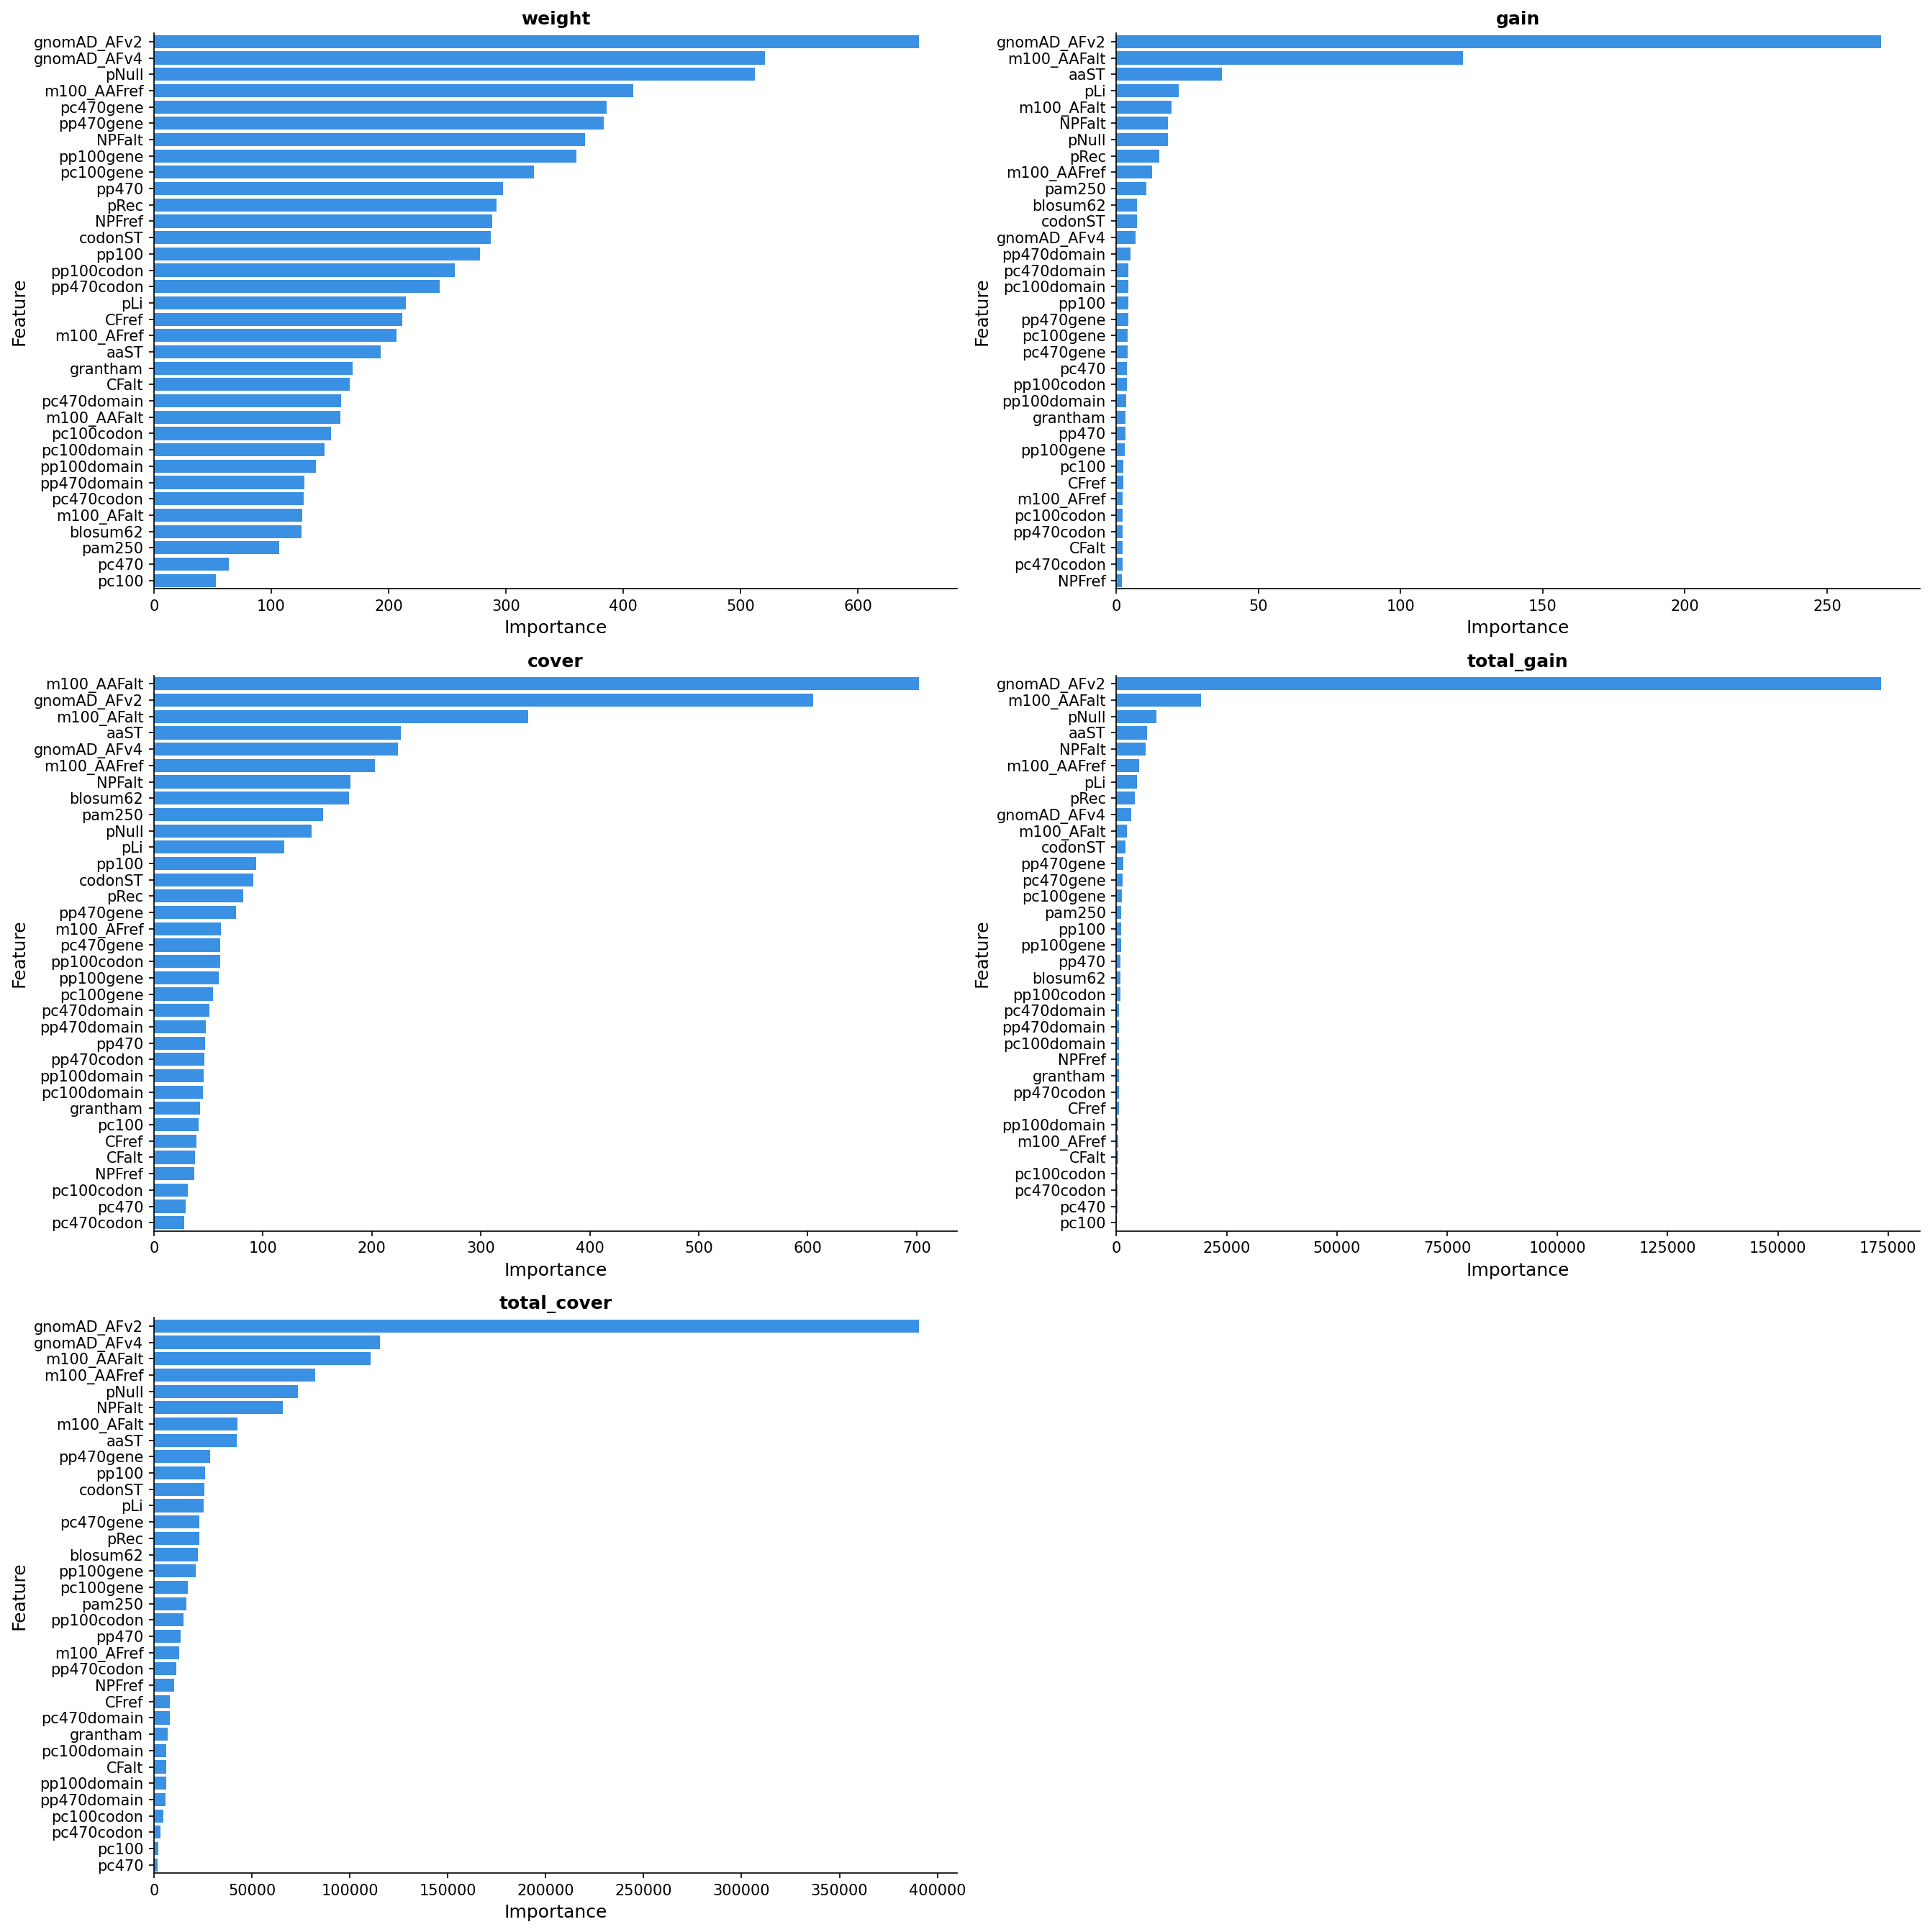

val


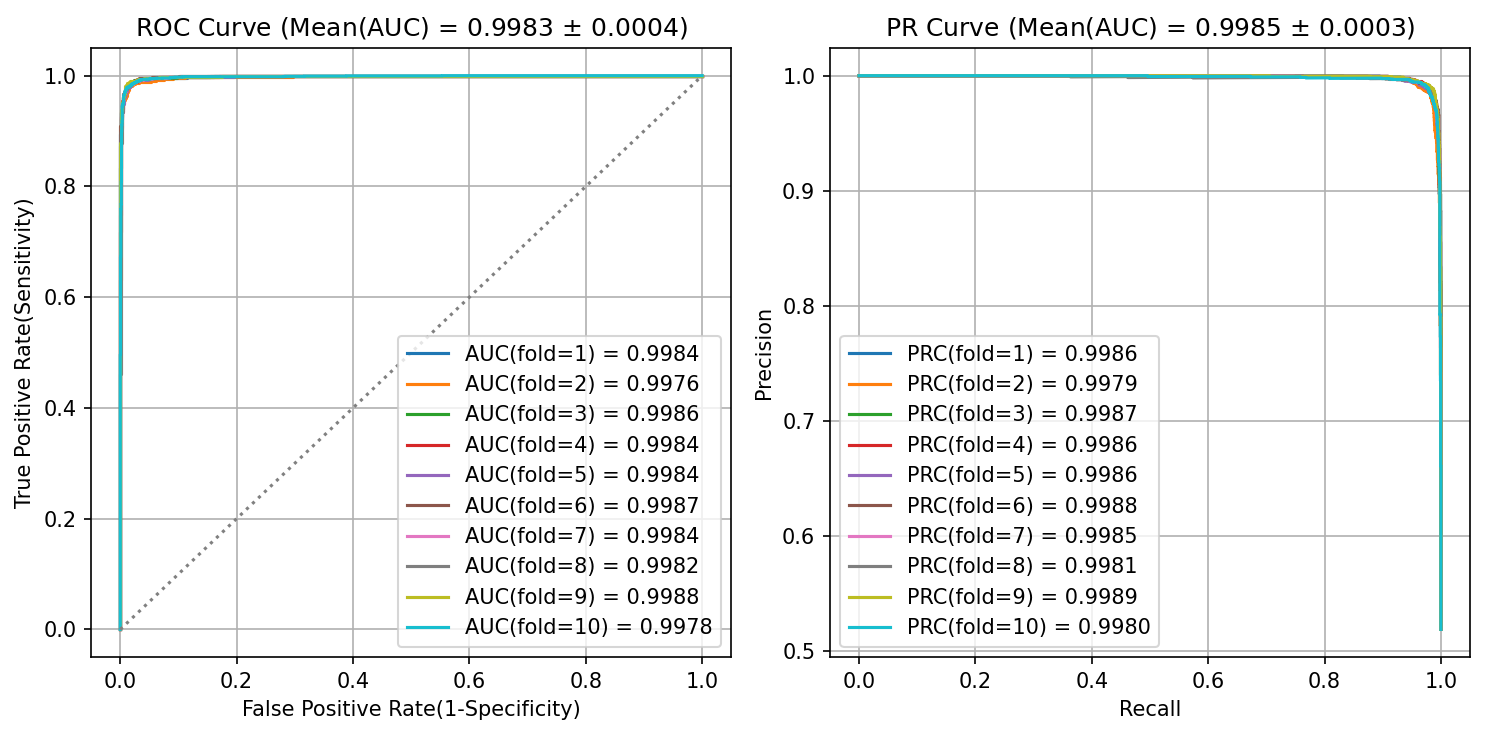

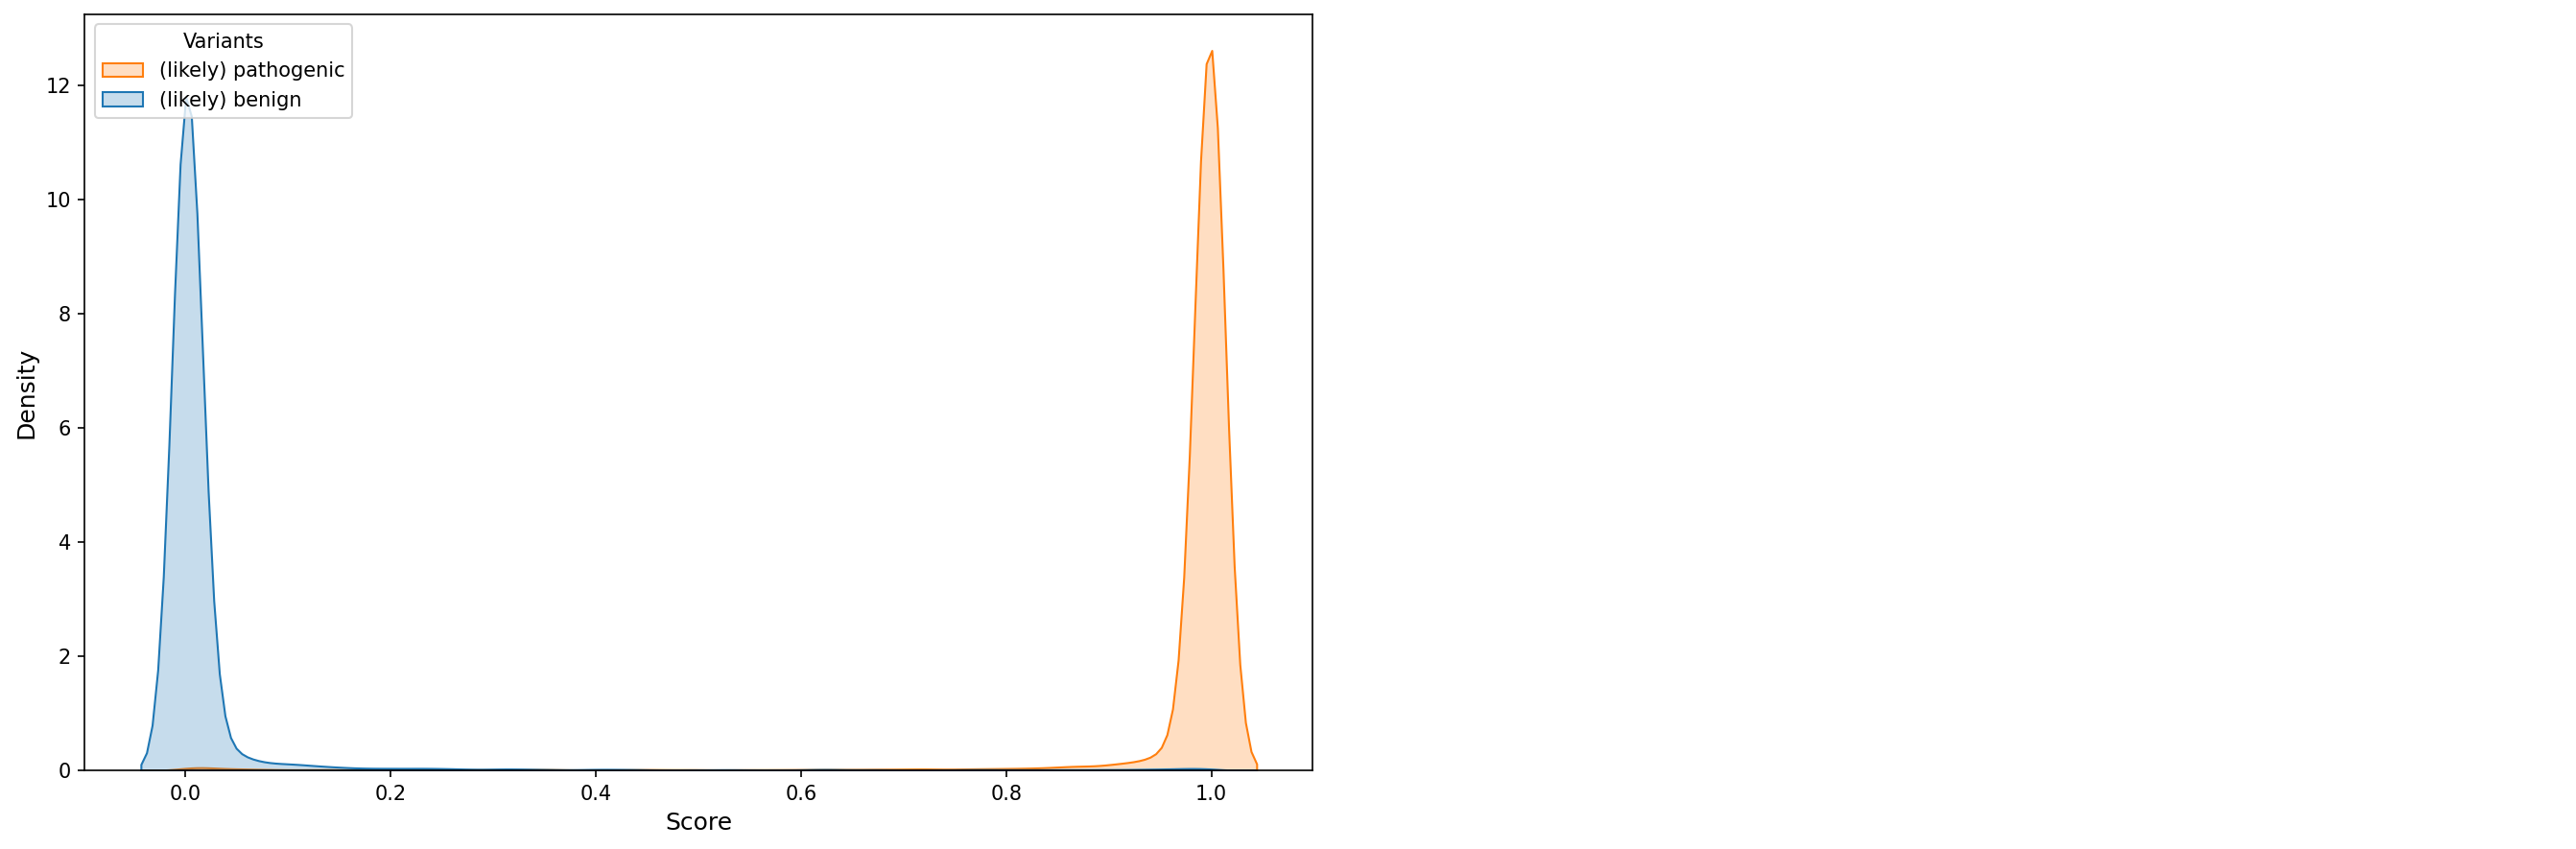

test


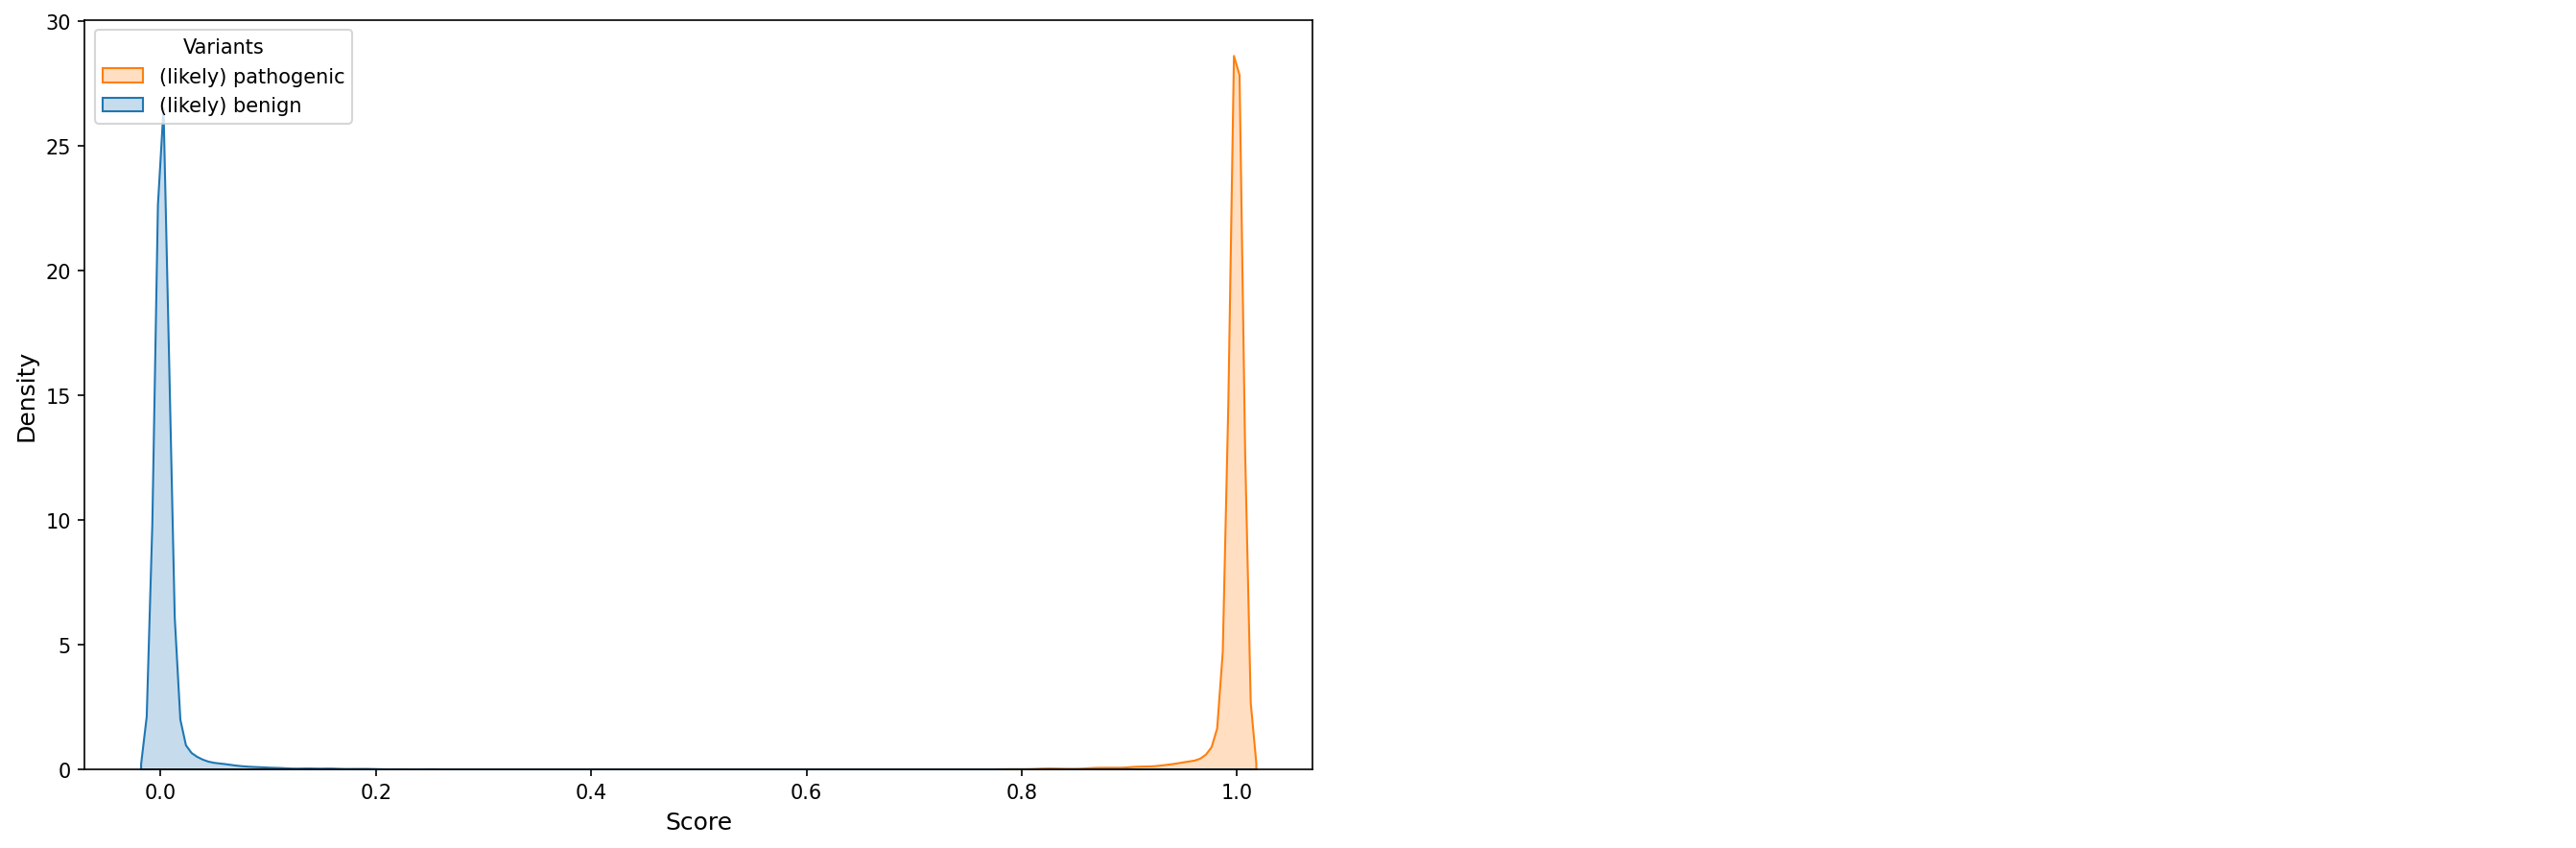

test


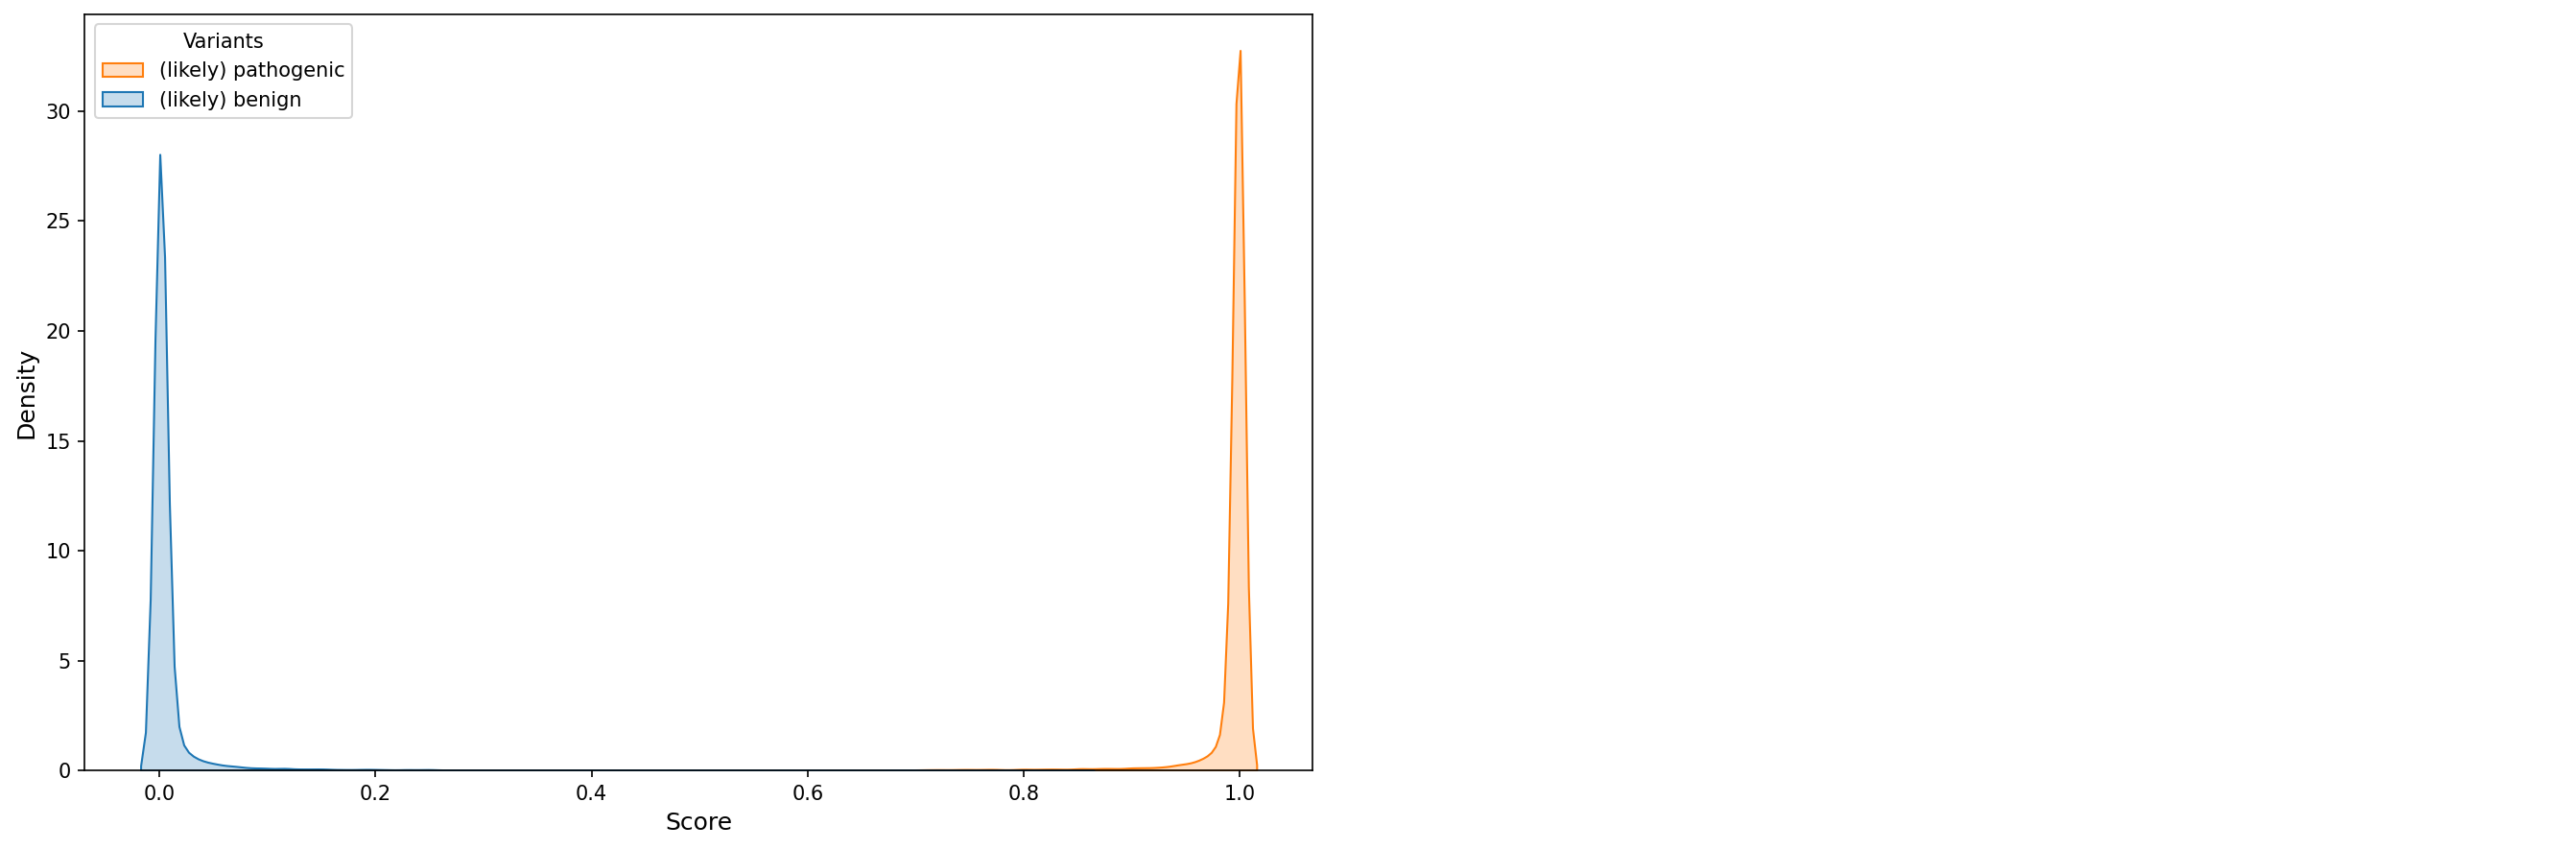

,thres,Accuracy,F1,MCC,Precision,Recall(=Sens),Specificity,AUC,AUCPR,G-mean,PPV,NPV,FNR,FPR,TN,FP,FN,TP
trial1_val1_roc_0.5000,0.5000,0.9829,0.9835,0.9658,0.9848,0.9822,0.9837,0.9984,0.9986,0.9829,0.9848,0.9809,0.0178,0.0163,2410.0,40.0,47.0,2592.0
trial1_val1_roc_0.5285,0.5285,0.9833,0.9838,0.9666,0.9867,0.9811,0.9857,0.9984,0.9986,0.9834,0.9867,0.9797,0.0189,0.0143,2415.0,35.0,50.0,2589.0
trial1_val1_roc_0.4520,0.4520,0.9829,0.9835,0.9658,0.9837,0.9833,0.9824,0.9984,0.9986,0.9829,0.9837,0.9820,0.0167,0.0176,2407.0,43.0,44.0,2595.0
trial1_val2_roc_0.5000,0.5000,0.9821,0.9827,0.9642,0.9848,0.9807,0.9837,0.9976,0.9979,0.9822,0.9848,0.9793,0.0193,0.0163,2410.0,40.0,51.0,2588.0
trial1_val2_roc_0.5041,0.5041,0.9821,0.9827,0.9642,0.9851,0.9803,0.9841,0.9976,0.9979,0.9822,0.9851,0.9789,0.0197,0.0159,2411.0,39.0,52.0,2587.0
trial1_val2_roc_0.4366,0.4366,0.9821,0.9827,0.9642,0.9837,0.9818,0.9824,0.9976,0.9979,0.9821,0.9837,0.9804,0.0182,0.0176,2407.0,43.0,48.0,2591.0
trial1_val2_roc_0.4081,0.4081,0.9817,0.9824,0.9634,0.9826,0.9822,0.9812,0.9976,0.9979,0.9817,0.9826,0.9808,0.0178,0.0188,2404.0,46.0,47.0,2592.0
trial1_val3_roc_0.5000,0.5000,0.9827,0.9833,0.9654,0.9837,0.9829,0.9824,0.9986,0.9987,0.9827,0.9837,0.9816,0.0171,0.0176,2407.0,43.0,45.0,2594.0
trial1_val3_roc_0.3407,0.3407,0.9843,0.9849,0.9685,0.9816,0.9883,0.9800,0.9986,0.9987,0.9841,0.9816,0.9873,0.0117,0.0200,2401.0,49.0,31.0,2608.0
trial1_val3_roc_0.3282,0.3282,0.9843,0.9849,0.9685,0.9812,0.9886,0.9796,0.9986,0.9987,0.9841,0.9812,0.9877,0.0114,0.0204,2400.0,50.0,30.0,2609.0


In [ ]:
print("!!!", _fold_name)

xgb_params = {'booster': 'gbtree', 'verbosity': 1,
              'objective':'binary:logistic', 'device': 'cuda',
              'seed': 42, #random_state
              'eval_metric' : ['auc','aucpr','pre', 'error', 'logloss'],}
xgb_params.update(study.best_trial.params)
split_t = 'skf'
split_n = 10
size_test = 0.25
random_state_list = [42]

splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
split_data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)

multi_model = Multi_Train(split_data_n=split_data_n, X_Train = X_Train, y_Train = y_Train, trial_num = 1)
return_auc = multi_model.execute(ml_name, xgb_params, "", fold_name = _fold_name)

### predict(optuna)

In [ ]:
# xgb
best_model = objective.best_booster

a = (new_X, X_Train, X_test,)
b = (y, y_Train, y_test,)
for _x, _y in zip(a,b):
    print(_x.shape, _y.shape)
    set_test = xgb.DMatrix(_x)
    y_pred= best_model.predict(set_test)

    name = 'xgb_predict'
    file_name = f'{name}.png'
    file_png = os.path.join(os.getcwd(), file_name)

    thres_lst = [0.5]
    _df = evaluation_thres(name, _y, y_pred.reshape(-1, 1), thres_lst, save_png = file_png)
    display(_df)

    _oob = pd.DataFrame(index=_y.index)
    _oob.loc[_y.index, 'y'] = _y
    _oob['y'] = _oob['y'].astype(int).astype('category')
    _oob.loc[_y.index, 'y_pred'] = y_pred

    plot_score_dist(_oob)

    plot_classification_report(_y.values, y_pred.reshape(-1,1), title='Classification', cmap='viridis')

### predict(model)

In [ ]:
print("!!!", _fold_name)
_set = list(_df.keys())
predict_test_dataset(test_X, test_y, test_head, _set, ml_name, _train, _fold_name)

In [ ]:
print("!!!", _fold_name)
_set = list(_df.keys())
plot_line_predicttion(_set, _fold_name, ml_name, _train)

### explain_shap

In [ ]:
#idx0 = _oob[(_oob['y'] == 1) & (_oob['eq'] == 1)].index
idx0 = _oob[(_oob['y'] == 1) & (_oob['eq'] == 1) &
 ((_oob['gnomAD_exom_v2_AF']>0) | (_oob['gnomAD_exom_v4_AF']>0))].index
rand_idx0 = np.random.choice(idx0, size=1000, replace=False)
#idx1 = _oob[(_oob['y'] == 0) & (_oob['eq'] == 1)].index
idx1 = _oob[(_oob['y'] == 0) & (_oob['eq'] == 1) &
 ((_oob['gnomAD_exom_v2_AF']>0) | (_oob['gnomAD_exom_v4_AF']>0))].index
rand_idx1 = np.random.choice(idx1, size=1000, replace=False)
rand_idx = np.concatenate([rand_idx0, rand_idx1])
rand_idx.sort()

base_values, shap_values = make_shap_value(multi_model.best_model, X_test.loc[rand_idx])
plot_shap(X_test.loc[rand_idx], base_values, shap_values, _fold_name)

Output hidden; open in https://colab.research.google.com to view.

### explain_shap_cv
* https://towardsdatascience.com/using-shap-with-cross-validation-d24af548fadc

In [ ]:
random_state = 42
split_t = 'skf'
split_n = 10
size_test=0.1
random_state_list = [42]

splitter = Splitter(split_t = split_t, split_n = split_n, size_test = size_test)
data_n = splitter.split_data(X_Train, y_Train, random_state_list=random_state_list)

base_values_fold=[]
shap_values_fold = pd.DataFrame(index=X_Train.index, columns=['shap'])

for i, (X_train_, X_valid_, y_train_, y_valid_, val_index) in enumerate(data_n):
    #print(f"Fold: {i+1}", X_train_.shape, X_valid_.shape, X_train_.index[0], X_valid_.index[0], type(X_train_), type(y_valid_),)
    #print(f"Fold: {i+1}", Counter(y_train_),Counter(y_valid_) )

    base_values, shap_values = make_shap_value(multi_model.best_models[i], X_valid_)

    for j, _v in enumerate(shap_values):
        #shap_values_fold.append(_v)
        shap_values_fold.loc[val_index[j], 'shap'] = _v
    base_values_fold.append(base_values)

fold_shap = f'{_fold_name}/shap'
make_folder(os.getcwd(), fold_shap)

save_npy = f'{fold_shap}/_{ml_name}_shap_values.npy'
np.save(save_npy, np.stack(shap_values_fold['shap'].values))
save_npy = f'{fold_shap}/_{ml_name}_base_values.npy'
np.save(save_npy, base_values_fold)

#plot_shap(X_Train, np.mean(np.concatenate(base_values_fold)),np.stack(shap_values_fold['shap'].values), fold_shap)
plot_shap(X_Train, np.mean(base_values_fold),np.stack(shap_values_fold['shap'].values), fold_shap)

Output hidden; open in https://colab.research.google.com to view.

### load_explain_shap

In [ ]:
save_npy = f'{fold_shap}/_{ml_name}_shap_values.npy'
loaded_shap_values = np.load(save_npy)
save_npy = f'{fold_shap}/_{ml_name}_base_values.npy'
loaded_base_values = np.load(save_npy)

#plot_shap(X_Train, np.mean(loaded_base_values), loaded_shap_values, fold_shap)
#plot_shap(_x, np.mean(loaded_base_values), loaded_shap_values, fold_shap)

In [ ]:
for i in tn_index:
    #if pd.notna(clinvar.iloc[i]['gnomAD_exom_v2_AF']):
    #if pd.notna(clinvar.iloc[i]['neigh_aa3AltFreqA']):
    #if clinvar.iloc[i]['gnomAD_exom_v2_AF'] < 0.00001:
    if _df[_train].iloc[i]['gnomAD_exom_v2_AF'] < 0.00001:
        break

#tp_index2 = tp_index[clinvar.loc[tp_index, 'gnomAD_exom_v2_AF'].notna()]
#i = tp_index[10110]
i=0
print(i)
#display(clinvar.iloc[i])
display(_df[_train].iloc[i].to_frame().T)
display(_oob.iloc[i].to_frame().T)

_ori = _x.loc[i]
#_ori = _ori.round(2)
#_ori = _ori.apply(lambda x: '{:.2e}'.format(x))
#_ori = new_X.loc[i].round(5)

fx = loaded_shap_values[i].sum()+ np.mean(loaded_base_values)
prob = 1 / (1 + np.exp(-fx))
print(fx, prob)

shap.force_plot(np.mean(loaded_base_values),
                loaded_shap_values[i],
                _ori, matplotlib=True, show=True, out_names=None )

shap.waterfall_plot(shap.Explanation(values = loaded_shap_values[i],
                                     base_values = np.mean(loaded_base_values),
                                     data = _ori,
                                    ))

shap.decision_plot(np.mean(loaded_base_values), loaded_shap_values[i],
                _ori, highlight=0,
                link='logit')

shap.force_plot(0,#np.mean(loaded_base_values),
                loaded_shap_values[i],
                _ori, matplotlib=True, show=True, out_names=None )

shap.waterfall_plot(shap.Explanation(values = loaded_shap_values[i],
                                     base_values = 0,#np.mean(loaded_base_values),
                                     data = _ori,
                                    ))
shap.decision_plot(0, loaded_shap_values[i],
                _ori, highlight=0,
                link='logit')

In [ ]:
save_npy = f'{fold_shap}/_{ml_name}_shap_values.npy'
loaded_shap_values = np.load(save_npy)
save_npy = f'{fold_shap}/_{ml_name}_base_values.npy'
loaded_base_values = np.load(save_npy)

#plot_shap(X_Train, np.mean(loaded_base_values), loaded_shap_values, fold_shap)
#plot_shap(_x, np.mean(loaded_base_values), loaded_shap_values, fold_shap)

In [ ]:
for col_name in _x.columns:
    plt.figure(figsize=(10, 6), dpi=150)
    shap.dependence_plot(col_name, loaded_shap_values, X_test, show=False)

Output hidden; open in https://colab.research.google.com to view.